# S&P 500 Capstone


## 1 Modeling and Model Evaluation

## Modeling Objective and Controls

- The modeling objective is to predict the S&P 500 return from the current Friday to the following Friday. The target variable is `target_return_next_w`.

- `model_week_end` identifies the Friday associated with each observation. It establishes the chronological order used for the fixed training period, training-period cross-validation, the consolidated test period, and the final forecast.

- V9 is the sole data source. It contains one complete weekly calendar spanning July 22, 2016 through October 2, 2026.

- V9 contains 15 primary predictor series. The WTI price level is derived from the current source value in the V9 WTI series and included as the sixteenth predictor input for the approved WTI-above-$90 threshold. No external or separate dataset is introduced.

- Every predictor series, including the FactSet forward P/E series, is populated for the additional model weeks beginning July 24, 2026 and continuing through the October 1, 2026 predictor-information cutoff.

- Administrative fields, including `row_complete` and `notes`, are excluded from the predictor matrix.

## Fixed chronological split

- The training period contains 348 complete-calendar observations from July 22, 2016 through March 17, 2023.

- March 17, 2023 is the final training observation. The March 24, 2023 S&P 500 closing value is used to calculate the March 17 next-week target. This does not place the March 24 observation in the training period.

- The consolidated test period begins on March 24, 2023.

- The first 88 observations in the consolidated test period span March 24, 2023 through November 22, 2024.

- The November 29, 2024 S&P 500 closing value is used to calculate the November 22 next-week target. The November 29 observation remains part of the consolidated test period.

- The consolidated test period continues without a second test set or separate forward-validation period. It contains every target-bearing observation from March 24, 2023 through September 25, 2026.

- The consolidated test period therefore contains 184 known-target observations:
  - 88 observations from March 24, 2023 through November 22, 2024.
  - 96 subsequent observations from November 29, 2024 through September 25, 2026.

- The October 2, 2026 row is retained for forecasting and has no observable next-week target.

- The complete V9 calendar reconciles as follows:

  `348 training observations + 184 test observations + 1 forecast row = 533 weekly observations`

## Sample eligibility

- The fixed training and test counts refer to the complete V9 weekly calendar.

- Models requiring the forward P/E series use the eligible matched observations that fall within the same fixed training and test date windows. Matching may reduce the number of rows available to a particular model, but it does not change the split dates or create another dataset.

- Missing values created by required lags, rolling windows, momentum calculations, or predictor availability may reduce the usable rows for a particular model. These reductions must be reported separately from the complete-calendar counts.

## Information timing

- Under the Friday-night modeling convention, predictor information available through Thursday, October 1, 2026 is assigned to the Friday, October 2, 2026 observation.

- The October 2 observation is excluded from test-performance calculations because its next-week target is not observable.

- Lagged, rolling, and momentum variables are constructed on the complete V9 weekly calendar before any matching, complete-case filtering, or modeling-date selection occurs.

## Training and testing controls

- Feature selection, threshold-support analysis, model selection, hyperparameter tuning, and final model specification are performed using the training period only.

- Training-period cross-validation must preserve chronological order.

- The entire consolidated test period remains untouched until all model-development decisions have been completed using the training period.

- Test-period results and regime occurrences cannot be used to select, modify, remove, or justify predictors, thresholds, interactions, hyperparameters, or model specifications.

- Predictor coefficients, threshold coefficients, interaction coefficients, and all other model weights are estimated by the model. No subjective or manually assigned weights are used.

- Threshold features are retained only when they have sufficient support within the training sample and produce stable training-period cross-validation results.

### 2 Notebook Setup

In [1]:
# 2 Notebook Setup

from pathlib import Path
import random
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import ElasticNet, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
# REPRODUCIBILITY

RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

warnings.filterwarnings("default")

In [3]:
# DISPLAY AND CHART SETTINGS

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 140)
pd.set_option(
    "display.float_format",
    lambda value: f"{value:,.4f}",
)

sns.set_theme(
    context="notebook",
    style="whitegrid",
    palette="deep",
)

plt.rcParams.update({
    "figure.figsize": (11, 6),
    "figure.dpi": 110,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
})

In [4]:
# V9 WORKBOOK CONFIGURATION

V9_DATA_DIRECTORY = Path(
    r"C:\Users\sethp\Documents\S Pomeroy - AI & Data Science"
    r"\Springboard\9B) Capstone Project2"
)

V9_WORKBOOK_NAME = (
    "Springboard - Capstone Two Data Series V9 (10 07 26).xlsx"
)

V9_WORKBOOK_PATH = V9_DATA_DIRECTORY / V9_WORKBOOK_NAME

V9_MODEL_DATA_SHEET = "Model Data"
V9_WTI_SOURCE_SHEET = "S11 WTI Chg"

# Field names are on Excel row 4.
V9_EXCEL_HEADER_ROW = 4
V9_PANDAS_HEADER_INDEX = V9_EXCEL_HEADER_ROW - 1

assert V9_WORKBOOK_PATH.is_file(), (
    f"V9 workbook not found: {V9_WORKBOOK_PATH}"
)

In [5]:
# COMMON COLUMN NAMES

DATE_COL = "model_week_end"
TARGET_COL = "target_return_next_w"
ROW_COMPLETE_COL = "row_complete"
NOTES_COL = "notes"

WTI_SOURCE_DATE_COL = "model_week_end"
WTI_SOURCE_VALUE_COL = "current_source_value"
WTI_PRICE_LEVEL_COL = "wti_price_level"

NON_PREDICTOR_COLS = [
    DATE_COL,
    TARGET_COL,
    ROW_COMPLETE_COL,
    NOTES_COL,
]

In [6]:
# V9 DATE AND MODELING CONSTANTS
# Observation counts will be calculated from V9 after feature construction.

V9_CALENDAR_START_DATE = pd.Timestamp("2016-07-22")
V9_CALENDAR_END_DATE = pd.Timestamp("2026-10-02")
V9_FINAL_PLACEHOLDER_DATE = pd.Timestamp("2026-10-02")

TRAIN_END_DATE = pd.Timestamp("2023-03-17")
TEST_START_DATE = pd.Timestamp("2023-03-24")

INITIAL_TEST_END_DATE = pd.Timestamp("2024-11-22")
LAST_KNOWN_TARGET_DATE = pd.Timestamp("2026-09-25")
FORECAST_ONLY_DATE = pd.Timestamp("2026-10-02")

WEEKLY_FREQUENCY = "W-FRI"
FORECAST_HORIZON_WEEKS = 1
PREDICTOR_LAG_WEEKS = 1

PRIMARY_METRIC = "mae"

SUPPORTING_METRICS = (
    "rmse",
    "r2",
    "directional_accuracy",
)

In [7]:
# 16-PREDICTOR SPECIFICATION OR INDEPENDENT VARIABLES
# wti_price_level is created from current_source_value on the V9 WTI worksheet before matching modeling dates.

PREDICTORS = [
    "sp500_weekly_pct_chg",
    "fed_funds_level",
    "fed_funds_weekly_bp_chg",
    "vix_level",
    "vix_weekly_point_chg",
    "treasury_10y_yield_level",
    "tips_10y_yield_level",
    "yield_spread_10y3m",
    "baa10y_yield_spread",
    "wti_weekly_pct_chg",
    "wti_price_level",
    "broad_usd_weekly_pct_chg",
    "initial_claims_weekly_pct_chg",
    "wei_level",
    "nfci_level",
    "sp500_forward_pe_level",
]

In [8]:
# ECONOMIC-ROLE GROUPINGS

PREDICTOR_GROUPS = {
    "timing": [
        "sp500_weekly_pct_chg",
        "fed_funds_weekly_bp_chg",
        "vix_weekly_point_chg",
        "wti_weekly_pct_chg",
        "broad_usd_weekly_pct_chg",
        "initial_claims_weekly_pct_chg",
    ],

    "economic_regime": [
        "fed_funds_level",
        "vix_level",
        "treasury_10y_yield_level",
        "tips_10y_yield_level",
        "yield_spread_10y3m",
        "baa10y_yield_spread",
        "wti_price_level",
        "wei_level",
        "nfci_level",
    ],

    "long_horizon_valuation": [
        "sp500_forward_pe_level",
    ],
}

PREDICTOR_TO_GROUP = {
    predictor: group_name
    for group_name, group_predictors in PREDICTOR_GROUPS.items()
    for predictor in group_predictors
}

In [9]:
# APPROVED THRESHOLD REGISTRY

THRESHOLD_COLUMNS = [
    "threshold_id",
    "predictor",
    "operator",
    "cutoff",
    "units",
    "structure",
    "interpretation",
]

THRESHOLD_RULES = [
    # Two-sided thresholds
    (
        "sp500_below_neg_2pct",
        "sp500_weekly_pct_chg",
        "<",
        -0.02,
        "decimal return",
        "two_sided",
        "S&P 500 weekly change below -2.0%",
    ),
    (
        "sp500_above_pos_2pct",
        "sp500_weekly_pct_chg",
        ">",
        0.02,
        "decimal return",
        "two_sided",
        "S&P 500 weekly change above 2.0%",
    ),
    (
        "fed_funds_cut_25bp",
        "fed_funds_weekly_bp_chg",
        "<=",
        -25.0,
        "basis points",
        "two_sided",
        "Federal-funds reduction of at least 25 basis points",
    ),
    (
        "fed_funds_hike_25bp",
        "fed_funds_weekly_bp_chg",
        ">=",
        25.0,
        "basis points",
        "two_sided",
        "Federal-funds increase of at least 25 basis points",
    ),
    (
        "vix_change_below_neg_5",
        "vix_weekly_point_chg",
        "<",
        -5.0,
        "index points",
        "two_sided",
        "VIX weekly change below -5 points",
    ),
    (
        "vix_change_above_pos_5",
        "vix_weekly_point_chg",
        ">",
        5.0,
        "index points",
        "two_sided",
        "VIX weekly change above 5 points",
    ),
    (
        "wti_change_below_neg_5pct",
        "wti_weekly_pct_chg",
        "<",
        -0.05,
        "decimal return",
        "two_sided",
        "WTI weekly change below -5.0%",
    ),
    (
        "wti_change_above_pos_5pct",
        "wti_weekly_pct_chg",
        ">",
        0.05,
        "decimal return",
        "two_sided",
        "WTI weekly change above 5.0%",
    ),
    (
        "usd_change_below_neg_1pct",
        "broad_usd_weekly_pct_chg",
        "<",
        -0.01,
        "decimal return",
        "two_sided",
        "Broad-dollar weekly change below -1.0%",
    ),
    (
        "usd_change_above_pos_1pct",
        "broad_usd_weekly_pct_chg",
        ">",
        0.01,
        "decimal return",
        "two_sided",
        "Broad-dollar weekly change above 1.0%",
    ),
    (
        "claims_change_below_neg_5pct",
        "initial_claims_weekly_pct_chg",
        "<",
        -0.05,
        "decimal change",
        "two_sided",
        "Initial-claims weekly change below -5.0%",
    ),
    (
        "claims_change_above_pos_5pct",
        "initial_claims_weekly_pct_chg",
        ">",
        0.05,
        "decimal change",
        "two_sided",
        "Initial-claims weekly change above 5.0%",
    ),

    # Natural zero boundaries
    (
        "yield_curve_below_zero",
        "yield_spread_10y3m",
        "<",
        0.0,
        "basis points",
        "natural_zero",
        "10-year/3-month spread below zero",
    ),
    (
        "wei_below_zero",
        "wei_level",
        "<",
        0.0,
        "index value",
        "natural_zero",
        "WEI below zero",
    ),
    (
        "nfci_above_zero",
        "nfci_level",
        ">",
        0.0,
        "index value",
        "natural_zero",
        "NFCI above zero",
    ),

    # Asymmetric valuation thresholds
    (
        "forward_pe_below_16",
        "sp500_forward_pe_level",
        "<",
        16.0,
        "P/E multiple",
        "asymmetric",
        "S&P 500 forward P/E below 16",
    ),
    (
        "forward_pe_above_20",
        "sp500_forward_pe_level",
        ">",
        20.0,
        "P/E multiple",
        "asymmetric",
        "S&P 500 forward P/E above 20",
    ),

    # One-sided high-regime thresholds
    (
        "fed_funds_above_4pct",
        "fed_funds_level",
        ">",
        4.0,
        "percentage points",
        "one_sided_high",
        "Federal-funds level above 4.0%",
    ),
    (
        "vix_above_25",
        "vix_level",
        ">",
        25.0,
        "index level",
        "one_sided_high",
        "VIX above 25",
    ),
    (
        "treasury_10y_above_5_25pct",
        "treasury_10y_yield_level",
        ">",
        5.25,
        "percentage points",
        "one_sided_high",
        "10-year Treasury yield above 5.25%",
    ),
    (
        "tips_10y_above_3_25pct",
        "tips_10y_yield_level",
        ">",
        3.25,
        "percentage points",
        "one_sided_high",
        "10-year TIPS real yield above 3.25%",
    ),
    (
        "baa10y_spread_above_250bp",
        "baa10y_yield_spread",
        ">",
        250.0,
        "basis points",
        "one_sided_high",
        "BAA/10-year spread above 250 basis points",
    ),
    (
        "wti_price_above_90",
        "wti_price_level",
        ">",
        90.0,
        "U.S. dollars per barrel",
        "one_sided_high",
        "WTI price above $90 per barrel",
    ),
]

THRESHOLD_REGISTRY = pd.DataFrame(
    THRESHOLD_RULES,
    columns=THRESHOLD_COLUMNS,
)

THRESHOLD_REGISTRY["economic_role"] = (
    THRESHOLD_REGISTRY["predictor"].map(PREDICTOR_TO_GROUP)
)

THRESHOLD_REGISTRY["indicator_feature"] = (
    "thr_" + THRESHOLD_REGISTRY["threshold_id"] + "_flag"
)

THRESHOLD_REGISTRY["excess_feature"] = (
    "thr_" + THRESHOLD_REGISTRY["threshold_id"] + "_excess"
)

THRESHOLD_REGISTRY = THRESHOLD_REGISTRY.set_index(
    "threshold_id",
    drop=False,
)

In [10]:
# SETUP INTEGRITY CHECKS

grouped_predictors = [
    predictor
    for group_predictors in PREDICTOR_GROUPS.values()
    for predictor in group_predictors
]

valid_operators = {"<", ">", "<=", ">="}

assert len(PREDICTORS) == 16
assert len(set(PREDICTORS)) == 16

assert len(grouped_predictors) == 16
assert len(set(grouped_predictors)) == 16
assert set(grouped_predictors) == set(PREDICTORS)

assert len(THRESHOLD_REGISTRY) == 23
assert THRESHOLD_REGISTRY.index.is_unique
assert THRESHOLD_REGISTRY["indicator_feature"].is_unique
assert THRESHOLD_REGISTRY["excess_feature"].is_unique

assert set(THRESHOLD_REGISTRY["predictor"]).issubset(PREDICTORS)
assert set(THRESHOLD_REGISTRY["operator"]).issubset(valid_operators)
assert THRESHOLD_REGISTRY["economic_role"].notna().all()

assert TRAIN_END_DATE.day_name() == "Friday"
assert TEST_START_DATE.day_name() == "Friday"
assert TEST_START_DATE == TRAIN_END_DATE + pd.Timedelta(weeks=1)

assert V9_CALENDAR_START_DATE.day_name() == "Friday"
assert V9_CALENDAR_END_DATE.day_name() == "Friday"
assert V9_FINAL_PLACEHOLDER_DATE == V9_CALENDAR_END_DATE

one_sided_rules = THRESHOLD_REGISTRY.loc[
    THRESHOLD_REGISTRY["structure"].eq("one_sided_high")
]

assert one_sided_rules["operator"].eq(">").all()
assert one_sided_rules["predictor"].is_unique

In [11]:
# SETUP SUMMARY

SETUP_SUMMARY = pd.Series(
    {
        "workbook": V9_WORKBOOK_NAME,
        "worksheet": V9_MODEL_DATA_SHEET,
        "random_seed": RANDOM_SEED,
        "predictor_count": len(PREDICTORS),
        "threshold_count": len(THRESHOLD_REGISTRY),
        "training_end": TRAIN_END_DATE.date(),
        "test_start": TEST_START_DATE.date(),
        "final_placeholder": V9_FINAL_PLACEHOLDER_DATE.date(),
    },
    name="V9 notebook setup",
)

SETUP_SUMMARY

workbook             Springboard - Capstone Two Data Series V9 (10 ...
worksheet                                                   Model Data
random_seed                                                         42
predictor_count                                                     16
threshold_count                                                     23
training_end                                                2023-03-17
test_start                                                  2023-03-24
final_placeholder                                           2026-10-02
Name: V9 notebook setup, dtype: object

### 3 Load and Validate the V9 Data

In [12]:
# V9 LOAD CONFIGURATION FOR STEP 3

V9_COMPLETE_CALENDAR_SHEET = "Model 522"
V9_FORWARD_PE_SOURCE_SHEET = "S16 Forward PE"
V9_TARGET_SOURCE_SHEET = "S01 SP500 Target"

V9_SOURCE_EXCEL_HEADER_ROW = 10
V9_SOURCE_PANDAS_HEADER_INDEX = V9_SOURCE_EXCEL_HEADER_ROW - 1

V9_PREDICTOR_SOURCE_SHEETS = [
    "S02 SP500 Predictor",
    "S03 Fed Funds Level",
    "S04 Fed Funds Chg",
    "S05 VIX Level",
    "S06 VIX Chg",
    "S07 10Y Yield",
    "S08 10Y TIPS",
    "S09 10Y3M Spread",
    "S10 Baa10Y Spread",
    "S11 WTI Chg",
    "S12 USD Chg",
    "S13 Claims Chg",
    "S14 WEI Level",
    "S15 NFCI Level",
    "S16 Forward PE",
]

V9_CALENDAR_COLUMN_RENAMES = {
    "sp500_weekly_perchg": "sp500_weekly_pct_chg",
    "fed_funds_weekly_bpchg": "fed_funds_weekly_bp_chg",
    "vix_weekly_pointchg": "vix_weekly_point_chg",
    "10y_yield_level": "treasury_10y_yield_level",
    "10ytips_yield_level": "tips_10y_yield_level",
    "10y3m_yield_spread": "yield_spread_10y3m",
    "10ybaa_yield_spread": "baa10y_yield_spread",
    "wti_weekly_perchg": "wti_weekly_pct_chg",
    "usd_weekly_perchg": "broad_usd_weekly_pct_chg",
    "jobclaims_weekly_perchg": "initial_claims_weekly_pct_chg",
}

In [13]:
# LOAD THE V9 WORKSHEETS

v9_model_data_raw = pd.read_excel(
    V9_WORKBOOK_PATH,
    sheet_name=V9_MODEL_DATA_SHEET,
    header=V9_PANDAS_HEADER_INDEX,
)

v9_calendar_raw = pd.read_excel(
    V9_WORKBOOK_PATH,
    sheet_name=V9_COMPLETE_CALENDAR_SHEET,
    header=V9_PANDAS_HEADER_INDEX,
)

v9_wti_source = pd.read_excel(
    V9_WORKBOOK_PATH,
    sheet_name=V9_WTI_SOURCE_SHEET,
    header=V9_SOURCE_PANDAS_HEADER_INDEX,
)

v9_forward_pe_source = pd.read_excel(
    V9_WORKBOOK_PATH,
    sheet_name=V9_FORWARD_PE_SOURCE_SHEET,
    header=V9_SOURCE_PANDAS_HEADER_INDEX,
)

v9_target_source = pd.read_excel(
    V9_WORKBOOK_PATH,
    sheet_name=V9_TARGET_SOURCE_SHEET,
    header=V9_SOURCE_PANDAS_HEADER_INDEX,
)

for frame in (
    v9_model_data_raw,
    v9_calendar_raw,
    v9_wti_source,
    v9_forward_pe_source,
    v9_target_source,
):
    frame.columns = [str(column).strip() for column in frame.columns]


def normalize_v9_dates(frame, date_columns):
    """Return a copy with the specified date columns normalized to midnight."""
    result = frame.copy()

    for column in date_columns:
        if column in result.columns:
            result[column] = pd.to_datetime(
                result[column],
                errors="coerce",
            ).dt.normalize()

    return result

In [14]:
# PREPARE THE COMPLETE CALENDAR AND THE MATCHED MODEL DATA

SOURCE_DATE_COLUMNS = [
    DATE_COL,
    "alignment_cutoff_date",
    "current_source_observation_date",
    "comparison_source_observation_date",
]

v9_wti_source = normalize_v9_dates(
    v9_wti_source,
    SOURCE_DATE_COLUMNS,
)

v9_forward_pe_source = normalize_v9_dates(
    v9_forward_pe_source,
    SOURCE_DATE_COLUMNS,
)

v9_target_source = normalize_v9_dates(
    v9_target_source,
    SOURCE_DATE_COLUMNS,
)

wti_level_lookup = (
    v9_wti_source[[WTI_SOURCE_DATE_COL, WTI_SOURCE_VALUE_COL]]
    .rename(columns={WTI_SOURCE_VALUE_COL: WTI_PRICE_LEVEL_COL})
)

forward_pe_lookup = v9_forward_pe_source[
    [DATE_COL, "sp500_forward_pe_level"]
].copy()

assert wti_level_lookup[WTI_SOURCE_DATE_COL].is_unique
assert forward_pe_lookup[DATE_COL].is_unique

v9_model_data = normalize_v9_dates(
    v9_model_data_raw,
    [DATE_COL],
).merge(
    wti_level_lookup,
    how="left",
    left_on=DATE_COL,
    right_on=WTI_SOURCE_DATE_COL,
    validate="one_to_one",
)

v9_complete_calendar = (
    normalize_v9_dates(v9_calendar_raw, [DATE_COL])
    .rename(columns=V9_CALENDAR_COLUMN_RENAMES)
    .merge(
        wti_level_lookup,
        how="left",
        left_on=DATE_COL,
        right_on=WTI_SOURCE_DATE_COL,
        validate="one_to_one",
    )
    .merge(
        forward_pe_lookup,
        how="left",
        on=DATE_COL,
        validate="one_to_one",
    )
)

V9_MODEL_COLUMN_ORDER = [
    DATE_COL,
    TARGET_COL,
    *PREDICTORS,
    ROW_COMPLETE_COL,
    NOTES_COL,
]

missing_model_columns = (
    set(V9_MODEL_COLUMN_ORDER) - set(v9_model_data.columns)
)

missing_calendar_columns = (
    set(V9_MODEL_COLUMN_ORDER) - set(v9_complete_calendar.columns)
)

assert not missing_model_columns, (
    f"Missing Model Data columns: {sorted(missing_model_columns)}"
)

assert not missing_calendar_columns, (
    f"Missing calendar columns: {sorted(missing_calendar_columns)}"
)

v9_model_data = v9_model_data[
    V9_MODEL_COLUMN_ORDER
].copy()

v9_complete_calendar = v9_complete_calendar[
    V9_MODEL_COLUMN_ORDER
].copy()

for frame in (v9_model_data, v9_complete_calendar):
    frame[[TARGET_COL, *PREDICTORS]] = frame[
        [TARGET_COL, *PREDICTORS]
    ].apply(pd.to_numeric, errors="raise")

In [15]:
# VALIDATE THE COMPLETE 533-WEEK CALENDAR AND FIXED DATE WINDOWS

expected_v9_dates = pd.date_range(
    start=V9_CALENDAR_START_DATE,
    end=V9_CALENDAR_END_DATE,
    freq=WEEKLY_FREQUENCY,
)

assert len(expected_v9_dates) == 533
assert len(v9_complete_calendar) == len(expected_v9_dates)
assert not v9_complete_calendar[DATE_COL].duplicated().any()
assert v9_complete_calendar[DATE_COL].is_monotonic_increasing

assert (
    v9_complete_calendar[DATE_COL]
    .dt.day_name()
    .eq("Friday")
    .all()
)

assert (
    v9_complete_calendar[DATE_COL]
    .reset_index(drop=True)
    .equals(pd.Series(expected_v9_dates, name=DATE_COL))
)

train_calendar_mask = (
    v9_complete_calendar[DATE_COL] <= TRAIN_END_DATE
)

test_calendar_mask = v9_complete_calendar[DATE_COL].between(
    TEST_START_DATE,
    LAST_KNOWN_TARGET_DATE,
)

forecast_calendar_mask = (
    v9_complete_calendar[DATE_COL] == FORECAST_ONLY_DATE
)

initial_test_mask = v9_complete_calendar[DATE_COL].between(
    TEST_START_DATE,
    INITIAL_TEST_END_DATE,
)

subsequent_test_mask = v9_complete_calendar[DATE_COL].between(
    INITIAL_TEST_END_DATE + pd.Timedelta(weeks=1),
    LAST_KNOWN_TARGET_DATE,
)

assert train_calendar_mask.sum() == 348
assert test_calendar_mask.sum() == 184
assert forecast_calendar_mask.sum() == 1
assert initial_test_mask.sum() == 88
assert subsequent_test_mask.sum() == 96

assert (
    train_calendar_mask
    | test_calendar_mask
    | forecast_calendar_mask
).all()

assert (
    v9_complete_calendar.loc[
        train_calendar_mask,
        TARGET_COL,
    ]
    .notna()
    .all()
)

assert (
    v9_complete_calendar.loc[
        test_calendar_mask,
        TARGET_COL,
    ]
    .notna()
    .all()
)

assert (
    v9_complete_calendar.loc[
        forecast_calendar_mask,
        TARGET_COL,
    ]
    .isna()
    .all()
)

unknown_target_dates = v9_complete_calendar.loc[
    v9_complete_calendar[TARGET_COL].isna(),
    DATE_COL,
]

assert len(unknown_target_dates) == 1
assert unknown_target_dates.iloc[0] == FORECAST_ONLY_DATE

In [16]:
# VALIDATE THE 16-PREDICTOR MODELING ROWS

assert len(PREDICTORS) == 16
assert not v9_model_data[DATE_COL].duplicated().any()
assert v9_model_data[DATE_COL].is_monotonic_increasing

assert (
    v9_model_data[DATE_COL]
    .dt.day_name()
    .eq("Friday")
    .all()
)

predictor_numeric_status = (
    v9_model_data[PREDICTORS]
    .dtypes
    .apply(pd.api.types.is_numeric_dtype)
)

model_predictor_values = (
    v9_model_data[PREDICTORS]
    .to_numpy(dtype=float)
)

assert predictor_numeric_status.all()
assert v9_model_data[PREDICTORS].notna().all().all()
assert np.isfinite(model_predictor_values).all()

model_unknown_target_dates = v9_model_data.loc[
    v9_model_data[TARGET_COL].isna(),
    DATE_COL,
]

assert len(model_unknown_target_dates) == 1
assert model_unknown_target_dates.iloc[0] == FORECAST_ONLY_DATE

last_scored_test_date = v9_model_data.loc[
    v9_model_data[DATE_COL].between(
        TEST_START_DATE,
        LAST_KNOWN_TARGET_DATE,
    )
    & v9_model_data[TARGET_COL].notna(),
    DATE_COL,
].max()

assert last_scored_test_date == LAST_KNOWN_TARGET_DATE

eligible_calendar_rows = v9_complete_calendar.loc[
    v9_complete_calendar[PREDICTORS].notna().all(axis=1),
    V9_MODEL_COLUMN_ORDER,
].reset_index(drop=True)

v9_model_data = v9_model_data.reset_index(drop=True)

assert len(v9_model_data) == 448
assert len(eligible_calendar_rows) == len(v9_model_data)
assert eligible_calendar_rows[DATE_COL].equals(
    v9_model_data[DATE_COL]
)

for column in [TARGET_COL, *PREDICTORS]:
    np.testing.assert_allclose(
        eligible_calendar_rows[column].to_numpy(dtype=float),
        v9_model_data[column].to_numpy(dtype=float),
        rtol=1e-12,
        atol=1e-12,
        equal_nan=True,
    )

model_train_mask = (
    v9_model_data[DATE_COL] <= TRAIN_END_DATE
)

model_test_mask = v9_model_data[DATE_COL].between(
    TEST_START_DATE,
    LAST_KNOWN_TARGET_DATE,
)

model_forecast_mask = (
    v9_model_data[DATE_COL] == FORECAST_ONLY_DATE
)

assert model_train_mask.sum() == 265
assert model_test_mask.sum() == 182
assert model_forecast_mask.sum() == 1
assert v9_model_data[TARGET_COL].notna().sum() == 447

In [17]:
# VALIDATE THE JULY-OCTOBER 2026 EXTENSION

extension_cutoff_date = pd.Timestamp("2026-07-10")

v9_extension_validation = v9_complete_calendar.loc[
    v9_complete_calendar[DATE_COL] > extension_cutoff_date,
    [DATE_COL, TARGET_COL, *PREDICTORS],
].copy()

assert len(v9_extension_validation) == 12

assert (
    v9_extension_validation[DATE_COL].iloc[0]
    == pd.Timestamp("2026-07-17")
)

assert (
    v9_extension_validation[DATE_COL].iloc[-1]
    == FORECAST_ONLY_DATE
)

assert (
    v9_extension_validation[PREDICTORS]
    .notna()
    .all()
    .all()
)

assert np.isfinite(
    v9_extension_validation[PREDICTORS]
    .to_numpy(dtype=float)
).all()

assert (
    v9_extension_validation[TARGET_COL]
    .notna()
    .sum()
    == 11
)

assert v9_extension_validation.loc[
    v9_extension_validation[TARGET_COL].isna(),
    DATE_COL,
].tolist() == [FORECAST_ONLY_DATE]

In [18]:
# VALIDATE PREDICTOR SOURCE-DATE ALIGNMENT

v9_predictor_sources = {}
source_timing_records = []

for sheet_name in V9_PREDICTOR_SOURCE_SHEETS:
    source_frame = pd.read_excel(
        V9_WORKBOOK_PATH,
        sheet_name=sheet_name,
        header=V9_SOURCE_PANDAS_HEADER_INDEX,
    )

    source_frame.columns = [
        str(column).strip()
        for column in source_frame.columns
    ]

    source_frame = normalize_v9_dates(
        source_frame,
        SOURCE_DATE_COLUMNS,
    )

    assert len(source_frame) == len(expected_v9_dates)
    assert not source_frame[DATE_COL].duplicated().any()
    assert source_frame[DATE_COL].is_monotonic_increasing

    assert (
        source_frame[DATE_COL]
        .reset_index(drop=True)
        .equals(pd.Series(expected_v9_dates, name=DATE_COL))
    )

    cutoff_after_week_end = (
        source_frame["alignment_cutoff_date"]
        > source_frame[DATE_COL]
    )

    current_after_cutoff = (
        source_frame["current_source_observation_date"]
        > source_frame["alignment_cutoff_date"]
    )

    comparison_after_current = (
        source_frame["comparison_source_observation_date"]
        > source_frame["current_source_observation_date"]
    )

    missing_current_date = (
        source_frame["current_source_observation_date"]
        .isna()
    )

    assert not cutoff_after_week_end.any()
    assert not current_after_cutoff.any()
    assert not comparison_after_current.any()

    assert source_frame.loc[
        missing_current_date,
        "current_source_value",
    ].isna().all()

    assert source_frame.loc[
        missing_current_date,
        NOTES_COL,
    ].notna().all()

    extension_source_rows = source_frame.loc[
        source_frame[DATE_COL] > extension_cutoff_date
    ]

    assert len(extension_source_rows) == 12

    assert (
        extension_source_rows["current_source_value"]
        .notna()
        .all()
    )

    source_timing_records.append(
        {
            "worksheet": sheet_name,
            "rows": len(source_frame),
            "missing_current_source_dates": int(
                missing_current_date.sum()
            ),
            "cutoff_after_model_week_end": int(
                cutoff_after_week_end.sum()
            ),
            "current_observation_after_cutoff": int(
                current_after_cutoff.sum()
            ),
            "comparison_observation_after_current": int(
                comparison_after_current.sum()
            ),
            "extension_current_values_complete": bool(
                extension_source_rows[
                    "current_source_value"
                ].notna().all()
            ),
        }
    )

    v9_predictor_sources[sheet_name] = source_frame

V9_SOURCE_TIMING_SUMMARY = pd.DataFrame(
    source_timing_records
)

timing_issue_columns = [
    "cutoff_after_model_week_end",
    "current_observation_after_cutoff",
    "comparison_observation_after_current",
]

assert (
    V9_SOURCE_TIMING_SUMMARY[
        timing_issue_columns
    ].to_numpy().sum()
    == 0
)

assert (
    V9_SOURCE_TIMING_SUMMARY[
        "extension_current_values_complete"
    ].all()
)

In [19]:
# VALIDATE NEXT-WEEK TARGET DATES

assert len(v9_target_source) == len(expected_v9_dates)
assert not v9_target_source[DATE_COL].duplicated().any()
assert v9_target_source[DATE_COL].is_monotonic_increasing

assert (
    v9_target_source[DATE_COL]
    .reset_index(drop=True)
    .equals(pd.Series(expected_v9_dates, name=DATE_COL))
)

known_target_source_mask = (
    v9_target_source[TARGET_COL].notna()
)

known_model_week_ends = v9_target_source.loc[
    known_target_source_mask,
    DATE_COL,
]

known_comparison_dates = v9_target_source.loc[
    known_target_source_mask,
    "comparison_source_observation_date",
]

next_model_week_ends = (
    known_model_week_ends
    + pd.Timedelta(weeks=FORECAST_HORIZON_WEEKS)
)

assert known_comparison_dates.gt(
    known_model_week_ends
).all()

assert known_comparison_dates.le(
    next_model_week_ends
).all()

assert v9_target_source.loc[
    ~known_target_source_mask,
    DATE_COL,
].tolist() == [FORECAST_ONLY_DATE]

assert v9_target_source.loc[
    ~known_target_source_mask,
    "comparison_source_observation_date",
].isna().all()

np.testing.assert_allclose(
    v9_target_source[TARGET_COL].to_numpy(dtype=float),
    v9_complete_calendar[TARGET_COL].to_numpy(dtype=float),
    rtol=1e-12,
    atol=1e-12,
    equal_nan=True,
)

In [20]:
# V9 DATA VALIDATION SUMMARY

V9_CALENDAR_SPLIT_SUMMARY = pd.DataFrame(
    {
        "calendar_rows": [
            348,
            184,
            1,
            533,
        ],
        "complete_16_predictor_rows": [
            int(model_train_mask.sum()),
            int(model_test_mask.sum()),
            int(model_forecast_mask.sum()),
            len(v9_model_data),
        ],
    },
    index=[
        "training",
        "consolidated_test",
        "forecast_only",
        "total",
    ],
)

V9_TEST_ELIGIBILITY_EXCEPTIONS = (
    v9_complete_calendar.loc[
        test_calendar_mask
        & ~v9_complete_calendar[PREDICTORS]
        .notna()
        .all(axis=1),
        [DATE_COL],
    ]
    .copy()
)

V9_TEST_ELIGIBILITY_EXCEPTIONS[
    "missing_predictors"
] = (
    v9_complete_calendar.loc[
        V9_TEST_ELIGIBILITY_EXCEPTIONS.index,
        PREDICTORS,
    ]
    .isna()
    .apply(
        lambda row: tuple(row.index[row]),
        axis=1,
    )
)

V9_TEST_ELIGIBILITY_EXCEPTIONS = (
    V9_TEST_ELIGIBILITY_EXCEPTIONS
    .reset_index(drop=True)
)

assert len(V9_TEST_ELIGIBILITY_EXCEPTIONS) == 2

source_timing_violations = int(
    V9_SOURCE_TIMING_SUMMARY[
        timing_issue_columns
    ].to_numpy().sum()
)

V9_VALIDATION_SUMMARY = pd.Series(
    {
        "complete_calendar_observations":
            len(v9_complete_calendar),

        "complete_calendar_known_targets":
            int(
                v9_complete_calendar[TARGET_COL]
                .notna()
                .sum()
            ),

        "complete_calendar_unknown_targets":
            int(
                v9_complete_calendar[TARGET_COL]
                .isna()
                .sum()
            ),

        "complete_16_predictor_rows":
            len(v9_model_data),

        "complete_16_predictor_known_targets":
            int(
                v9_model_data[TARGET_COL]
                .notna()
                .sum()
            ),

        "last_scored_test_date":
            last_scored_test_date.date(),

        "forecast_only_date":
            FORECAST_ONLY_DATE.date(),

        "duplicate_calendar_dates":
            int(
                v9_complete_calendar[DATE_COL]
                .duplicated()
                .sum()
            ),

        "calendar_chronological":
            bool(
                v9_complete_calendar[DATE_COL]
                .is_monotonic_increasing
            ),

        "predictor_count":
            len(PREDICTORS),

        "model_predictor_missing_values":
            int(
                v9_model_data[PREDICTORS]
                .isna()
                .sum()
                .sum()
            ),

        "model_predictor_infinite_values":
            int(
                np.isinf(model_predictor_values).sum()
            ),

        "all_predictors_numeric":
            bool(predictor_numeric_status.all()),

        "july_october_extension_rows":
            len(v9_extension_validation),

        "extension_predictors_complete":
            bool(
                v9_extension_validation[PREDICTORS]
                .notna()
                .all()
                .all()
            ),

        "predictor_source_timing_violations":
            source_timing_violations,

        "validation_status":
            "PASS",
    },
    name="V9 data validation",
)

display(V9_VALIDATION_SUMMARY)
display(V9_CALENDAR_SPLIT_SUMMARY)
display(V9_TEST_ELIGIBILITY_EXCEPTIONS)
display(V9_SOURCE_TIMING_SUMMARY)

complete_calendar_observations                533
complete_calendar_known_targets               532
complete_calendar_unknown_targets               1
complete_16_predictor_rows                    448
complete_16_predictor_known_targets           447
last_scored_test_date                  2026-09-25
forecast_only_date                     2026-10-02
duplicate_calendar_dates                        0
calendar_chronological                       True
predictor_count                                16
model_predictor_missing_values                  0
model_predictor_infinite_values                 0
all_predictors_numeric                       True
july_october_extension_rows                    12
extension_predictors_complete                True
predictor_source_timing_violations              0
validation_status                            PASS
Name: V9 data validation, dtype: object

,calendar_rows,complete_16_predictor_rows
training,348,265
consolidated_test,184,182
forecast_only,1,1
total,533,448


,model_week_end,missing_predictors
0,2023-08-25,"(sp500_forward_pe_level,)"
1,2024-07-05,"(sp500_forward_pe_level,)"


,worksheet,rows,missing_current_source_dates,cutoff_after_model_week_end,current_observation_after_cutoff,comparison_observation_after_current,extension_current_values_complete
0,S02 SP500 Predictor,533,0,0,0,0,True
1,S03 Fed Funds Level,533,0,0,0,0,True
2,S04 Fed Funds Chg,533,0,0,0,0,True
3,S05 VIX Level,533,0,0,0,0,True
4,S06 VIX Chg,533,0,0,0,0,True
5,S07 10Y Yield,533,0,0,0,0,True
6,S08 10Y TIPS,533,0,0,0,0,True
7,S09 10Y3M Spread,533,0,0,0,0,True
8,S10 Baa10Y Spread,533,0,0,0,0,True
9,S11 WTI Chg,533,0,0,0,0,True


### 4 Create the Modeling Datasets and Chronological Split

In [21]:
# SEPARATE KNOWN-TARGET MODELING ROWS AND THE FORECAST-ONLY ROW

known_target_rows = (
    v9_model_data.loc[v9_model_data[TARGET_COL].notna()]
    .copy()
    .reset_index(drop=True)
)

forecast_row = (
    v9_model_data.loc[v9_model_data[TARGET_COL].isna()]
    .copy()
    .reset_index(drop=True)
)

assert len(known_target_rows) == 447
assert len(forecast_row) == 1
assert forecast_row.loc[0, DATE_COL] == FORECAST_ONLY_DATE
assert pd.isna(forecast_row.loc[0, TARGET_COL])
assert forecast_row[PREDICTORS].notna().all().all()

assert np.isfinite(
    forecast_row[PREDICTORS].to_numpy(dtype=float)
).all()

In [22]:
# CREATE THE UNSCALED PREDICTOR, TARGET, DATE, AND FORECAST OBJECTS

X_unscaled = known_target_rows[PREDICTORS].copy()
y = known_target_rows[TARGET_COL].copy()
model_dates = known_target_rows[DATE_COL].copy()

X_forecast_unscaled = forecast_row[PREDICTORS].copy()
forecast_dates = forecast_row[DATE_COL].copy()

assert list(X_unscaled.columns) == PREDICTORS
assert list(X_forecast_unscaled.columns) == PREDICTORS

assert len(X_unscaled) == len(y) == len(model_dates) == 447
assert len(X_forecast_unscaled) == len(forecast_dates) == 1

assert X_unscaled.index.equals(y.index)
assert X_unscaled.index.equals(model_dates.index)
assert X_forecast_unscaled.index.equals(forecast_dates.index)

assert X_unscaled.notna().all().all()
assert y.notna().all()

assert np.isfinite(
    X_unscaled.to_numpy(dtype=float)
).all()

assert np.isfinite(
    y.to_numpy(dtype=float)
).all()

In [23]:
# APPLY THE FIXED CHRONOLOGICAL SPLIT

train_selection = model_dates.le(TRAIN_END_DATE)

test_selection = model_dates.between(
    TEST_START_DATE,
    LAST_KNOWN_TARGET_DATE,
)

assert not (train_selection & test_selection).any()
assert (train_selection | test_selection).all()

X_train_unscaled = (
    X_unscaled.loc[train_selection]
    .copy()
    .reset_index(drop=True)
)

y_train = (
    y.loc[train_selection]
    .copy()
    .reset_index(drop=True)
)

train_dates = (
    model_dates.loc[train_selection]
    .copy()
    .reset_index(drop=True)
)

X_test_unscaled = (
    X_unscaled.loc[test_selection]
    .copy()
    .reset_index(drop=True)
)

y_test = (
    y.loc[test_selection]
    .copy()
    .reset_index(drop=True)
)

test_dates = (
    model_dates.loc[test_selection]
    .copy()
    .reset_index(drop=True)
)

X_forecast_unscaled = (
    X_forecast_unscaled.reset_index(drop=True)
)

forecast_dates = forecast_dates.reset_index(drop=True)

assert (
    len(X_train_unscaled)
    == len(y_train)
    == len(train_dates)
    == 265
)

assert (
    len(X_test_unscaled)
    == len(y_test)
    == len(test_dates)
    == 182
)

assert (
    len(X_forecast_unscaled)
    == len(forecast_dates)
    == 1
)

In [24]:
# BUILD LAGS AND FUTURE ROLLING FEATURES ON THE COMPLETE CALENDAR

# Rolling-window choices belong to controlled feature engineering in Step 7.
# Approved entries can later be added as:
# {"predictor_name": [4, 13]}

ROLLING_FEATURE_WINDOWS = {}


def build_calendar_features(
    calendar_frame,
    predictors,
    lag_weeks=1,
    rolling_windows=None,
):
    """Construct lagged and rolling features before matching model dates."""

    rolling_windows = rolling_windows or {}

    feature_frame = calendar_frame[
        [DATE_COL, *predictors]
    ].copy()

    lagged_feature_columns = []
    rolling_feature_columns = []

    for predictor in predictors:
        lagged_column = (
            f"{predictor}_lag_{lag_weeks}w"
        )

        lagged_values = (
            feature_frame[predictor]
            .shift(lag_weeks)
        )

        feature_frame[lagged_column] = lagged_values
        lagged_feature_columns.append(lagged_column)

        for window in rolling_windows.get(predictor, []):
            if not isinstance(window, int) or window < 2:
                raise ValueError(
                    f"Invalid rolling window for "
                    f"{predictor}: {window}"
                )

            mean_column = (
                f"{predictor}_lag_{lag_weeks}w_"
                f"roll_{window}w_mean"
            )

            std_column = (
                f"{predictor}_lag_{lag_weeks}w_"
                f"roll_{window}w_std"
            )

            feature_frame[mean_column] = (
                lagged_values
                .rolling(
                    window=window,
                    min_periods=window,
                )
                .mean()
            )

            feature_frame[std_column] = (
                lagged_values
                .rolling(
                    window=window,
                    min_periods=window,
                )
                .std(ddof=0)
            )

            rolling_feature_columns.extend(
                [mean_column, std_column]
            )

    return (
        feature_frame,
        lagged_feature_columns,
        rolling_feature_columns,
    )


(
    v9_calendar_feature_frame,
    LAGGED_FEATURE_COLUMNS,
    ROLLING_FEATURE_COLUMNS,
) = build_calendar_features(
    calendar_frame=v9_complete_calendar,
    predictors=PREDICTORS,
    lag_weeks=PREDICTOR_LAG_WEEKS,
    rolling_windows=ROLLING_FEATURE_WINDOWS,
)

assert len(v9_calendar_feature_frame) == 533
assert len(LAGGED_FEATURE_COLUMNS) == 16
assert len(ROLLING_FEATURE_COLUMNS) == 0

assert v9_calendar_feature_frame[DATE_COL].equals(
    v9_complete_calendar[DATE_COL]
)

for predictor, lagged_column in zip(
    PREDICTORS,
    LAGGED_FEATURE_COLUMNS,
):
    np.testing.assert_allclose(
        v9_calendar_feature_frame[
            lagged_column
        ].to_numpy(dtype=float),

        v9_complete_calendar[
            predictor
        ]
        .shift(PREDICTOR_LAG_WEEKS)
        .to_numpy(dtype=float),

        rtol=1e-12,
        atol=1e-12,
        equal_nan=True,
    )

# Join the calendar-built features back to matched dates
# only after feature construction.

v9_matched_feature_frame = v9_model_data[
    [DATE_COL, TARGET_COL]
].merge(
    v9_calendar_feature_frame[
        [
            DATE_COL,
            *LAGGED_FEATURE_COLUMNS,
            *ROLLING_FEATURE_COLUMNS,
        ]
    ],
    how="left",
    on=DATE_COL,
    validate="one_to_one",
)

assert (
    len(v9_matched_feature_frame)
    == len(v9_model_data)
    == 448
)

assert v9_matched_feature_frame[DATE_COL].equals(
    v9_model_data[DATE_COL]
)

In [25]:
# CONFIRM ALIGNMENT AND THE SINGLE CONSOLIDATED TEST SET

def assert_model_objects_aligned(
    X,
    target,
    dates,
):
    assert len(X) == len(target) == len(dates)
    assert X.index.equals(target.index)
    assert X.index.equals(dates.index)

    assert dates.is_monotonic_increasing
    assert not dates.duplicated().any()

    assert X.notna().all().all()
    assert target.notna().all()

    assert np.isfinite(
        X.to_numpy(dtype=float)
    ).all()

    assert np.isfinite(
        target.to_numpy(dtype=float)
    ).all()


assert_model_objects_aligned(
    X_train_unscaled,
    y_train,
    train_dates,
)

assert_model_objects_aligned(
    X_test_unscaled,
    y_test,
    test_dates,
)

assert train_dates.iloc[-1] == TRAIN_END_DATE
assert test_dates.iloc[0] == TEST_START_DATE
assert test_dates.iloc[-1] == LAST_KNOWN_TARGET_DATE
assert forecast_dates.iloc[0] == FORECAST_ONLY_DATE

assert train_dates.max() < test_dates.min()
assert test_dates.max() < forecast_dates.min()

initial_test_matched_count = int(
    test_dates.le(INITIAL_TEST_END_DATE).sum()
)

subsequent_test_matched_count = int(
    test_dates.gt(INITIAL_TEST_END_DATE).sum()
)

assert initial_test_matched_count == 86
assert subsequent_test_matched_count == 96

assert (
    initial_test_matched_count
    + subsequent_test_matched_count
    == len(test_dates)
    == 182
)

# The full test period remains one object.
# The two segment counts are for reporting only.

assert isinstance(X_test_unscaled, pd.DataFrame)
assert isinstance(y_test, pd.Series)
assert isinstance(test_dates, pd.Series)

In [26]:
# MODELING DATASET AND CHRONOLOGICAL SPLIT SUMMARY

V9_MODELING_SPLIT_SUMMARY = pd.DataFrame(
    {
        "calendar_rows": [
            348,
            184,
            1,
            533,
        ],
        "complete_16_predictor_rows": [
            265,
            182,
            1,
            448,
        ],
        "first_calendar_date": [
            V9_CALENDAR_START_DATE.date(),
            TEST_START_DATE.date(),
            FORECAST_ONLY_DATE.date(),
            V9_CALENDAR_START_DATE.date(),
        ],
        "last_calendar_date": [
            TRAIN_END_DATE.date(),
            LAST_KNOWN_TARGET_DATE.date(),
            FORECAST_ONLY_DATE.date(),
            FORECAST_ONLY_DATE.date(),
        ],
    },
    index=[
        "training",
        "consolidated_test",
        "forecast_only",
        "total",
    ],
)

V9_CONSOLIDATED_TEST_DETAIL = pd.DataFrame(
    {
        "calendar_rows": [
            88,
            96,
            184,
        ],
        "complete_16_predictor_rows": [
            initial_test_matched_count,
            subsequent_test_matched_count,
            len(X_test_unscaled),
        ],
        "start_date": [
            TEST_START_DATE.date(),
            (
                INITIAL_TEST_END_DATE
                + pd.Timedelta(weeks=1)
            ).date(),
            TEST_START_DATE.date(),
        ],
        "end_date": [
            INITIAL_TEST_END_DATE.date(),
            LAST_KNOWN_TARGET_DATE.date(),
            LAST_KNOWN_TARGET_DATE.date(),
        ],
    },
    index=[
        "first_test_calendar_segment",
        "subsequent_test_calendar_segment",
        "single_consolidated_test",
    ],
)

V9_MODELING_DATASET_SUMMARY = pd.Series(
    {
        "known_target_model_rows":
            len(X_unscaled),

        "unscaled_predictor_count":
            X_unscaled.shape[1],

        "matched_training_rows":
            len(X_train_unscaled),

        "matched_test_rows":
            len(X_test_unscaled),

        "forecast_rows":
            len(X_forecast_unscaled),

        "training_calendar_start":
            V9_CALENDAR_START_DATE.date(),

        "training_calendar_end":
            TRAIN_END_DATE.date(),

        "matched_training_start":
            train_dates.iloc[0].date(),

        "matched_training_end":
            train_dates.iloc[-1].date(),

        "test_start":
            test_dates.iloc[0].date(),

        "test_end":
            test_dates.iloc[-1].date(),

        "forecast_date":
            forecast_dates.iloc[0].date(),

        "single_consolidated_test":
            True,

        "predictors_preserved_unscaled":
            True,

        "calendar_first_lag_features":
            len(LAGGED_FEATURE_COLUMNS),

        "approved_rolling_windows":
            len(ROLLING_FEATURE_WINDOWS),

        "alignment_status":
            "PASS",
    },
    name="V9 modeling datasets",
)

display(V9_MODELING_DATASET_SUMMARY)
display(V9_MODELING_SPLIT_SUMMARY)
display(V9_CONSOLIDATED_TEST_DETAIL)

known_target_model_rows                 447
unscaled_predictor_count                 16
matched_training_rows                   265
matched_test_rows                       182
forecast_rows                             1
training_calendar_start          2016-07-22
training_calendar_end            2023-03-17
matched_training_start           2018-01-05
matched_training_end             2023-03-17
test_start                       2023-03-24
test_end                         2026-09-25
forecast_date                    2026-10-02
single_consolidated_test               True
predictors_preserved_unscaled          True
calendar_first_lag_features              16
approved_rolling_windows                  0
alignment_status                       PASS
Name: V9 modeling datasets, dtype: object

,calendar_rows,complete_16_predictor_rows,first_calendar_date,last_calendar_date
training,348,265,2016-07-22,2023-03-17
consolidated_test,184,182,2023-03-24,2026-09-25
forecast_only,1,1,2026-10-02,2026-10-02
total,533,448,2016-07-22,2026-10-02


,calendar_rows,complete_16_predictor_rows,start_date,end_date
first_test_calendar_segment,88,86,2023-03-24,2024-11-22
subsequent_test_calendar_segment,96,96,2024-11-29,2026-09-25
single_consolidated_test,184,182,2023-03-24,2026-09-25


### 5 Evaluation Metrics, Time-Series Cross-Validation, and Benchmarks

In [27]:
# EVALUATION METRICS

def directional_accuracy(y_true, y_pred):
    """Share of observations for which predicted and actual signs agree."""

    actual = np.asarray(y_true, dtype=float)
    predicted = np.asarray(y_pred, dtype=float)

    if actual.shape != predicted.shape:
        raise ValueError(
            "y_true and y_pred must have the same shape."
        )

    return float(
        np.mean(
            np.sign(actual) == np.sign(predicted)
        )
    )


def calculate_regression_metrics(y_true, y_pred):
    """Return the approved regression metrics."""

    actual = np.asarray(y_true, dtype=float)
    predicted = np.asarray(y_pred, dtype=float)

    if actual.shape != predicted.shape:
        raise ValueError(
            "y_true and y_pred must have the same shape."
        )

    if (
        not np.isfinite(actual).all()
        or not np.isfinite(predicted).all()
    ):
        raise ValueError(
            "Metric inputs must contain only finite values."
        )

    return {
        "mae": mean_absolute_error(
            actual,
            predicted,
        ),
        "rmse": np.sqrt(
            mean_squared_error(
                actual,
                predicted,
            )
        ),
        "r2": r2_score(
            actual,
            predicted,
        ),
        "directional_accuracy":
            directional_accuracy(
                actual,
                predicted,
            ),
    }


assert PRIMARY_METRIC == "mae"

assert SUPPORTING_METRICS == (
    "rmse",
    "r2",
    "directional_accuracy",
)

In [28]:
# FIXED EXPANDING-WINDOW TIME-SERIES CROSS-VALIDATION

CV_N_SPLITS = 5
CV_VALIDATION_SIZE = 26

TIME_SERIES_CV = TimeSeriesSplit(
    n_splits=CV_N_SPLITS,
    test_size=CV_VALIDATION_SIZE,
)

# Materialize the folds once so every comparable model
# receives exactly the same indices.

EXPANDING_CV_SPLITS = [
    (
        training_index.copy(),
        validation_index.copy(),
    )
    for training_index, validation_index
    in TIME_SERIES_CV.split(X_train_unscaled)
]

cv_fold_records = []

for fold_number, (
    training_index,
    validation_index,
) in enumerate(
    EXPANDING_CV_SPLITS,
    start=1,
):
    fold_training_dates = train_dates.iloc[
        training_index
    ]

    fold_validation_dates = train_dates.iloc[
        validation_index
    ]

    assert training_index[0] == 0
    assert training_index[-1] < validation_index[0]

    assert (
        fold_training_dates.max()
        < fold_validation_dates.min()
    )

    assert (
        len(validation_index)
        == CV_VALIDATION_SIZE
    )

    cv_fold_records.append(
        {
            "fold": fold_number,
            "training_rows": len(training_index),
            "training_start":
                fold_training_dates.iloc[0].date(),
            "training_end":
                fold_training_dates.iloc[-1].date(),
            "validation_rows":
                len(validation_index),
            "validation_start":
                fold_validation_dates.iloc[0].date(),
            "validation_end":
                fold_validation_dates.iloc[-1].date(),
        }
    )

CV_FOLD_SUMMARY = (
    pd.DataFrame(cv_fold_records)
    .set_index("fold")
)

assert len(EXPANDING_CV_SPLITS) == CV_N_SPLITS

assert (
    CV_FOLD_SUMMARY["training_rows"]
    .is_monotonic_increasing
)

assert (
    CV_FOLD_SUMMARY["validation_rows"]
    .eq(CV_VALIDATION_SIZE)
    .all()
)

# Reuse these exact folds for all comparable models.

CV_SPLITS = EXPANDING_CV_SPLITS

CV_PRIMARY_SCORING = (
    "neg_mean_absolute_error"
)

CV_SUPPORTING_SCORING = {
    "mae": "neg_mean_absolute_error",
    "mse": "neg_mean_squared_error",
    "r2": "r2",
}

In [29]:
# TRAINING-PERIOD CROSS-VALIDATION BENCHMARKS

benchmark_fold_records = []
benchmark_oof_records = []

for fold_number, (
    training_index,
    validation_index,
) in enumerate(
    CV_SPLITS,
    start=1,
):
    fold_training_target = y_train.iloc[
        training_index
    ]

    fold_validation_target = y_train.iloc[
        validation_index
    ]

    fold_validation_dates = train_dates.iloc[
        validation_index
    ]

    fold_predictions = {
        "zero_return": np.zeros(
            len(validation_index),
            dtype=float,
        ),
        "historical_mean": np.full(
            len(validation_index),
            fold_training_target.mean(),
            dtype=float,
        ),
    }

    for (
        benchmark_name,
        predictions,
    ) in fold_predictions.items():

        fold_metrics = (
            calculate_regression_metrics(
                fold_validation_target,
                predictions,
            )
        )

        benchmark_fold_records.append(
            {
                "benchmark": benchmark_name,
                "fold": fold_number,
                "training_rows":
                    len(training_index),
                "validation_rows":
                    len(validation_index),
                "validation_start":
                    fold_validation_dates
                    .iloc[0]
                    .date(),
                "validation_end":
                    fold_validation_dates
                    .iloc[-1]
                    .date(),
                **fold_metrics,
            }
        )

        benchmark_oof_records.append(
            pd.DataFrame(
                {
                    "benchmark":
                        benchmark_name,
                    "fold":
                        fold_number,
                    DATE_COL:
                        fold_validation_dates
                        .to_numpy(),
                    "actual":
                        fold_validation_target
                        .to_numpy(dtype=float),
                    "prediction":
                        predictions,
                }
            )
        )

CV_BENCHMARK_FOLD_RESULTS = (
    pd.DataFrame(benchmark_fold_records)
    .sort_values(
        ["benchmark", "fold"]
    )
    .reset_index(drop=True)
)

CV_BENCHMARK_OOF_PREDICTIONS = pd.concat(
    benchmark_oof_records,
    ignore_index=True,
)

assert (
    len(CV_BENCHMARK_FOLD_RESULTS)
    == 2 * CV_N_SPLITS
)

assert (
    len(CV_BENCHMARK_OOF_PREDICTIONS)
    == (
        2
        * CV_N_SPLITS
        * CV_VALIDATION_SIZE
    )
)

# Confirm that every historical-mean prediction
# uses only its fold's training targets.

for fold_number, (
    training_index,
    validation_index,
) in enumerate(
    CV_SPLITS,
    start=1,
):
    expected_mean = (
        y_train.iloc[training_index].mean()
    )

    observed_predictions = (
        CV_BENCHMARK_OOF_PREDICTIONS.loc[
            CV_BENCHMARK_OOF_PREDICTIONS[
                "benchmark"
            ].eq("historical_mean")
            & CV_BENCHMARK_OOF_PREDICTIONS[
                "fold"
            ].eq(fold_number),
            "prediction",
        ]
    )

    assert np.allclose(
        observed_predictions,
        expected_mean,
    )

In [30]:
# SUMMARIZE THE BENCHMARK PERFORMANCE TO BE EXCEEDED

CV_BENCHMARK_SUMMARY = (
    CV_BENCHMARK_FOLD_RESULTS
    .groupby(
        "benchmark",
        sort=False,
    )
    .agg(
        mae_mean=("mae", "mean"),
        mae_std=("mae", "std"),
        rmse_mean=("rmse", "mean"),
        rmse_std=("rmse", "std"),
        r2_mean=("r2", "mean"),
        directional_accuracy_mean=(
            "directional_accuracy",
            "mean",
        ),
    )
    .sort_values("mae_mean")
)

best_benchmark_name = (
    CV_BENCHMARK_SUMMARY[
        "mae_mean"
    ].idxmin()
)

CV_BENCHMARK_MAE_TO_BEAT = float(
    CV_BENCHMARK_SUMMARY.loc[
        best_benchmark_name,
        "mae_mean",
    ]
)

CV_BENCHMARK_STANDARD = pd.Series(
    {
        "primary_metric":
            PRIMARY_METRIC,

        "candidate_requirement":
            "mean CV MAE below best benchmark",

        "best_benchmark":
            best_benchmark_name,

        "mae_to_beat":
            CV_BENCHMARK_MAE_TO_BEAT,

        "cv_folds":
            CV_N_SPLITS,

        "validation_rows_per_fold":
            CV_VALIDATION_SIZE,

        "eligible_training_rows":
            len(X_train_unscaled),

        "fixed_training_calendar_rows":
            int(train_calendar_mask.sum()),
    },
    name="training CV benchmark standard",
)

assert (
    CV_BENCHMARK_STANDARD[
        "eligible_training_rows"
    ]
    == 265
)

assert (
    CV_BENCHMARK_STANDARD[
        "fixed_training_calendar_rows"
    ]
    == 348
)

assert np.isfinite(
    CV_BENCHMARK_MAE_TO_BEAT
)

In [31]:
# TEST BENCHMARK FUNCTION FOR USE ONLY AFTER THE FINAL MODEL IS FROZEN

def create_frozen_test_benchmark_predictions(
    training_target,
    consolidated_test_dates,
):
    """
    Create benchmark predictions without using
    consolidated test targets.
    """

    training_values = np.asarray(
        training_target,
        dtype=float,
    )

    dates = pd.Series(
        consolidated_test_dates
    ).reset_index(drop=True)

    if not np.isfinite(training_values).all():
        raise ValueError(
            "Training targets must contain only finite values."
        )

    if dates.empty or dates.isna().any():
        raise ValueError(
            "Consolidated test dates must be complete."
        )

    return pd.DataFrame(
        {
            DATE_COL:
                dates,

            "zero_return_prediction":
                np.zeros(
                    len(dates),
                    dtype=float,
                ),

            "historical_mean_prediction":
                np.full(
                    len(dates),
                    training_values.mean(),
                    dtype=float,
                ),
        }
    )


# Do not create or score the test benchmarks
# until the final model is frozen.

FINAL_MODEL_FROZEN = False
FINAL_TEST_BENCHMARK_PREDICTIONS = None

STEP5_SUMMARY = pd.Series(
    {
        "primary_metric":
            PRIMARY_METRIC,

        "supporting_metrics":
            SUPPORTING_METRICS,

        "cv_type":
            "expanding window",

        "cv_folds":
            len(CV_SPLITS),

        "eligible_training_rows":
            len(X_train_unscaled),

        "training_calendar_rows":
            int(train_calendar_mask.sum()),

        "best_cv_benchmark":
            best_benchmark_name,

        "cv_mae_to_beat":
            CV_BENCHMARK_MAE_TO_BEAT,

        "single_consolidated_test_rows":
            len(X_test_unscaled),

        "test_start":
            test_dates.iloc[0].date(),

        "test_end":
            test_dates.iloc[-1].date(),

        "test_metrics_calculated":
            False,

        "final_model_frozen":
            FINAL_MODEL_FROZEN,

        "step5_status":
            "PASS",
    },
    name="evaluation and benchmark setup",
)

display(STEP5_SUMMARY)
display(CV_FOLD_SUMMARY)
display(CV_BENCHMARK_SUMMARY)
display(CV_BENCHMARK_FOLD_RESULTS)

primary_metric                                                mae
supporting_metrics               (rmse, r2, directional_accuracy)
cv_type                                          expanding window
cv_folds                                                        5
eligible_training_rows                                        265
training_calendar_rows                                        348
best_cv_benchmark                                 historical_mean
cv_mae_to_beat                                             0.0197
single_consolidated_test_rows                                 182
test_start                                             2023-03-24
test_end                                               2026-09-25
test_metrics_calculated                                     False
final_model_frozen                                          False
step5_status                                                 PASS
Name: evaluation and benchmark setup, dtype: object

,training_rows,training_start,training_end,validation_rows,validation_start,validation_end
fold,,,,,,
1,135,2018-01-05,2020-07-31,26,2020-08-07,2021-02-12
2,161,2018-01-05,2021-02-12,26,2021-02-19,2021-08-13
3,187,2018-01-05,2021-08-13,26,2021-08-20,2022-03-11
4,213,2018-01-05,2022-03-11,26,2022-03-18,2022-09-16
5,239,2018-01-05,2022-09-16,26,2022-09-23,2023-03-17


,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,directional_accuracy_mean
benchmark,,,,,,
historical_mean,0.0197,0.0069,0.0241,0.0079,-0.0227,0.5308
zero_return,0.0198,0.0064,0.0243,0.0075,-0.0500,0.0000


,benchmark,fold,training_rows,validation_rows,validation_start,validation_end,mae,rmse,r2,directional_accuracy
0,historical_mean,1,135,26,2020-08-07,2021-02-12,0.0200,0.0262,-0.0135,0.5385
1,historical_mean,2,161,26,2021-02-19,2021-08-13,0.0114,0.0137,-0.0368,0.6538
2,historical_mean,3,187,26,2021-08-20,2022-03-11,0.0160,0.0199,-0.0015,0.5769
3,historical_mean,4,213,26,2022-03-18,2022-09-16,0.0300,0.0350,-0.0598,0.3846
4,historical_mean,5,239,26,2022-09-23,2023-03-17,0.0212,0.0256,-0.0019,0.5000
5,zero_return,1,135,26,2020-08-07,2021-02-12,0.0201,0.0265,-0.0368,0.0000
6,zero_return,2,161,26,2021-02-19,2021-08-13,0.0120,0.0143,-0.1408,0.0000
7,zero_return,3,187,26,2021-08-20,2022-03-11,0.0164,0.0202,-0.0324,0.0000
8,zero_return,4,213,26,2022-03-18,2022-09-16,0.0292,0.0344,-0.0252,0.0000
9,zero_return,5,239,26,2022-09-23,2023-03-17,0.0212,0.0257,-0.0149,0.0000


### 6 Linear Regression Models

In [32]:
# LINEAR MODEL SPECIFICATIONS

from sklearn.base import clone


PREDICTORS_15 = [
    predictor
    for predictor in PREDICTORS
    if predictor != WTI_PRICE_LEVEL_COL
]

assert len(PREDICTORS_15) == 15
assert WTI_PRICE_LEVEL_COL not in PREDICTORS_15

assert (
    set(PREDICTORS_15)
    | {WTI_PRICE_LEVEL_COL}
    == set(PREDICTORS)
)


LINEAR_MODEL_SPECS = {
    "ols_15_predictors": {
        "features": PREDICTORS_15,
        "pipeline": Pipeline(
            steps=[
                (
                    "scaler",
                    StandardScaler(),
                ),
                (
                    "model",
                    LinearRegression(),
                ),
            ]
        ),
    },

    "ols_16_predictors": {
        "features": PREDICTORS,
        "pipeline": Pipeline(
            steps=[
                (
                    "scaler",
                    StandardScaler(),
                ),
                (
                    "model",
                    LinearRegression(),
                ),
            ]
        ),
    },

    "ridge_16_predictors": {
        "features": PREDICTORS,
        "pipeline": Pipeline(
            steps=[
                (
                    "scaler",
                    StandardScaler(),
                ),
                (
                    "model",
                    Ridge(alpha=1.0),
                ),
            ]
        ),
    },

    "elastic_net_16_predictors": {
        "features": PREDICTORS,
        "pipeline": Pipeline(
            steps=[
                (
                    "scaler",
                    StandardScaler(),
                ),
                (
                    "model",
                    ElasticNet(
                        alpha=0.001,
                        l1_ratio=0.5,
                        max_iter=100_000,
                        tol=1e-7,
                        selection="cyclic",
                    ),
                ),
            ]
        ),
    },
}

assert set(LINEAR_MODEL_SPECS) == {
    "ols_15_predictors",
    "ols_16_predictors",
    "ridge_16_predictors",
    "elastic_net_16_predictors",
}

for specification in LINEAR_MODEL_SPECS.values():
    assert isinstance(
        specification["pipeline"],
        Pipeline,
    )

    assert isinstance(
        specification[
            "pipeline"
        ].named_steps["scaler"],
        StandardScaler,
    )

In [33]:
# CROSS-VALIDATE THE LINEAR MODELS ON THE IDENTICAL STORED FOLDS

linear_fold_records = []
linear_coefficient_records = []

for (
    model_name,
    specification,
) in LINEAR_MODEL_SPECS.items():

    feature_names = specification["features"]

    for fold_number, (
        training_index,
        validation_index,
    ) in enumerate(
        CV_SPLITS,
        start=1,
    ):
        fold_pipeline = clone(
            specification["pipeline"]
        )

        X_fold_train = (
            X_train_unscaled.iloc[
                training_index
            ][feature_names]
        )

        y_fold_train = y_train.iloc[
            training_index
        ]

        X_fold_validation = (
            X_train_unscaled.iloc[
                validation_index
            ][feature_names]
        )

        y_fold_validation = y_train.iloc[
            validation_index
        ]

        fold_pipeline.fit(
            X_fold_train,
            y_fold_train,
        )

        fold_predictions = (
            fold_pipeline.predict(
                X_fold_validation
            )
        )

        fold_metrics = (
            calculate_regression_metrics(
                y_fold_validation,
                fold_predictions,
            )
        )

        linear_fold_records.append(
            {
                "model":
                    model_name,

                "fold":
                    fold_number,

                "training_rows":
                    len(training_index),

                "validation_rows":
                    len(validation_index),

                "validation_start":
                    train_dates.iloc[
                        validation_index[0]
                    ].date(),

                "validation_end":
                    train_dates.iloc[
                        validation_index[-1]
                    ].date(),

                **fold_metrics,
            }
        )

        fitted_scaler = (
            fold_pipeline.named_steps[
                "scaler"
            ]
        )

        fitted_model = (
            fold_pipeline.named_steps[
                "model"
            ]
        )

        standardized_coefficients = (
            np.asarray(
                fitted_model.coef_,
                dtype=float,
            )
        )

        original_scale_coefficients = (
            standardized_coefficients
            / fitted_scaler.scale_
        )

        for (
            predictor,
            standardized_coefficient,
            original_scale_coefficient,
        ) in zip(
            feature_names,
            standardized_coefficients,
            original_scale_coefficients,
        ):
            linear_coefficient_records.append(
                {
                    "model":
                        model_name,

                    "fold":
                        fold_number,

                    "predictor":
                        predictor,

                    "standardized_coefficient":
                        standardized_coefficient,

                    "original_scale_coefficient":
                        original_scale_coefficient,
                }
            )


LINEAR_MODEL_FOLD_RESULTS = (
    pd.DataFrame(linear_fold_records)
    .sort_values(
        ["model", "fold"]
    )
    .reset_index(drop=True)
)

LINEAR_COEFFICIENTS_BY_FOLD = (
    pd.DataFrame(
        linear_coefficient_records
    )
    .sort_values(
        [
            "model",
            "predictor",
            "fold",
        ]
    )
    .reset_index(drop=True)
)

assert (
    len(LINEAR_MODEL_FOLD_RESULTS)
    == (
        len(LINEAR_MODEL_SPECS)
        * CV_N_SPLITS
    )
)

assert (
    LINEAR_MODEL_FOLD_RESULTS
    .groupby("model")["fold"]
    .nunique()
    .eq(CV_N_SPLITS)
    .all()
)

In [34]:
# COMPARE LINEAR MODEL PERFORMANCE WITH THE TRAINING BENCHMARKS

LINEAR_MODEL_CV_SUMMARY = (
    LINEAR_MODEL_FOLD_RESULTS
    .groupby(
        "model",
        sort=False,
    )
    .agg(
        predictor_count=(
            "model",
            "size",
        ),
        mae_mean=(
            "mae",
            "mean",
        ),
        mae_std=(
            "mae",
            "std",
        ),
        rmse_mean=(
            "rmse",
            "mean",
        ),
        rmse_std=(
            "rmse",
            "std",
        ),
        r2_mean=(
            "r2",
            "mean",
        ),
        directional_accuracy_mean=(
            "directional_accuracy",
            "mean",
        ),
    )
)

LINEAR_MODEL_CV_SUMMARY[
    "predictor_count"
] = [
    len(
        LINEAR_MODEL_SPECS[
            model_name
        ]["features"]
    )
    for model_name
    in LINEAR_MODEL_CV_SUMMARY.index
]

LINEAR_MODEL_CV_SUMMARY[
    "mae_improvement_vs_best_benchmark"
] = (
    CV_BENCHMARK_MAE_TO_BEAT
    - LINEAR_MODEL_CV_SUMMARY[
        "mae_mean"
    ]
)

LINEAR_MODEL_CV_SUMMARY[
    "beats_best_benchmark"
] = (
    LINEAR_MODEL_CV_SUMMARY[
        "mae_mean"
    ]
    < CV_BENCHMARK_MAE_TO_BEAT
)

LINEAR_MODEL_CV_SUMMARY = (
    LINEAR_MODEL_CV_SUMMARY
    .sort_values("mae_mean")
)

ols_15_mae = (
    LINEAR_MODEL_CV_SUMMARY.loc[
        "ols_15_predictors",
        "mae_mean",
    ]
)

ols_16_mae = (
    LINEAR_MODEL_CV_SUMMARY.loc[
        "ols_16_predictors",
        "mae_mean",
    ]
)

WTI_INCREMENTAL_COMPARISON = pd.Series(
    {
        "ols_15_predictor_mae":
            ols_15_mae,

        "ols_16_predictor_mae":
            ols_16_mae,

        "mae_change_after_adding_wti_price":
            ols_16_mae - ols_15_mae,

        "wti_price_improved_mae":
            bool(
                ols_16_mae
                < ols_15_mae
            ),
    },
    name=(
        "WTI price-level "
        "incremental comparison"
    ),
)

benchmark_comparison_rows = (
    CV_BENCHMARK_SUMMARY
    .reset_index()
    .rename(
        columns={
            "benchmark": "model"
        }
    )
)

benchmark_comparison_rows[
    "model_type"
] = "benchmark"

benchmark_comparison_rows[
    "beats_best_benchmark"
] = (
    benchmark_comparison_rows[
        "mae_mean"
    ]
    < CV_BENCHMARK_MAE_TO_BEAT
)

linear_comparison_rows = (
    LINEAR_MODEL_CV_SUMMARY
    .reset_index()
)

linear_comparison_rows[
    "model_type"
] = "linear_model"

CV_LINEAR_COMPARISON = (
    pd.concat(
        [
            benchmark_comparison_rows[
                [
                    "model",
                    "model_type",
                    "mae_mean",
                    "mae_std",
                    "rmse_mean",
                    "rmse_std",
                    "r2_mean",
                    "directional_accuracy_mean",
                    "beats_best_benchmark",
                ]
            ],

            linear_comparison_rows[
                [
                    "model",
                    "model_type",
                    "mae_mean",
                    "mae_std",
                    "rmse_mean",
                    "rmse_std",
                    "r2_mean",
                    "directional_accuracy_mean",
                    "beats_best_benchmark",
                ]
            ],
        ],
        ignore_index=True,
    )
    .sort_values("mae_mean")
    .reset_index(drop=True)
)

In [35]:
# REVIEW COEFFICIENT MAGNITUDE AND CROSS-FOLD STABILITY

def coefficient_sign_consistency(values):
    coefficients = np.asarray(
        values,
        dtype=float,
    )

    return float(
        max(
            np.mean(coefficients > 0),
            np.mean(coefficients < 0),
            np.mean(
                np.isclose(
                    coefficients,
                    0.0,
                    atol=1e-12,
                )
            ),
        )
    )


LINEAR_COEFFICIENT_STABILITY = (
    LINEAR_COEFFICIENTS_BY_FOLD
    .groupby(
        [
            "model",
            "predictor",
        ],
        sort=False,
    )
    .agg(
        standardized_coefficient_mean=(
            "standardized_coefficient",
            "mean",
        ),

        standardized_coefficient_std=(
            "standardized_coefficient",
            "std",
        ),

        mean_absolute_standardized_coefficient=(
            "standardized_coefficient",
            lambda values:
                np.mean(
                    np.abs(values)
                ),
        ),

        original_scale_coefficient_mean=(
            "original_scale_coefficient",
            "mean",
        ),

        sign_consistency=(
            "standardized_coefficient",
            coefficient_sign_consistency,
        ),

        nonzero_fold_share=(
            "standardized_coefficient",
            lambda values:
                np.mean(
                    ~np.isclose(
                        values,
                        0.0,
                        atol=1e-12,
                    )
                ),
        ),
    )
    .reset_index()
)

assert (
    LINEAR_COEFFICIENT_STABILITY[
        "sign_consistency"
    ]
    .between(0.0, 1.0)
    .all()
)

assert (
    LINEAR_COEFFICIENT_STABILITY[
        "nonzero_fold_share"
    ]
    .between(0.0, 1.0)
    .all()
)

In [36]:
# RETAIN THE STRONGEST LINEAR MODEL AS THE INTERPRETABLE BASELINE

RETAINED_LINEAR_MODEL_NAME = (
    LINEAR_MODEL_CV_SUMMARY.index[0]
)

RETAINED_LINEAR_FEATURES = (
    LINEAR_MODEL_SPECS[
        RETAINED_LINEAR_MODEL_NAME
    ]["features"]
)

INTERPRETABLE_BASELINE_PIPELINE = clone(
    LINEAR_MODEL_SPECS[
        RETAINED_LINEAR_MODEL_NAME
    ]["pipeline"]
)

INTERPRETABLE_BASELINE_PIPELINE.fit(
    X_train_unscaled[
        RETAINED_LINEAR_FEATURES
    ],
    y_train,
)

retained_scaler = (
    INTERPRETABLE_BASELINE_PIPELINE
    .named_steps["scaler"]
)

retained_estimator = (
    INTERPRETABLE_BASELINE_PIPELINE
    .named_steps["model"]
)

RETAINED_LINEAR_FULL_TRAIN_COEFFICIENTS = (
    pd.DataFrame(
        {
            "predictor":
                RETAINED_LINEAR_FEATURES,

            "standardized_coefficient":
                np.asarray(
                    retained_estimator.coef_,
                    dtype=float,
                ),

            "original_scale_coefficient":
                (
                    np.asarray(
                        retained_estimator.coef_,
                        dtype=float,
                    )
                    / retained_scaler.scale_
                ),
        }
    )
    .sort_values(
        "standardized_coefficient",
        key=lambda values: values.abs(),
        ascending=False,
    )
    .reset_index(drop=True)
)

RETAINED_LINEAR_COEFFICIENT_STABILITY = (
    LINEAR_COEFFICIENT_STABILITY.loc[
        LINEAR_COEFFICIENT_STABILITY[
            "model"
        ].eq(
            RETAINED_LINEAR_MODEL_NAME
        )
    ]
    .sort_values(
        "mean_absolute_standardized_coefficient",
        ascending=False,
    )
    .reset_index(drop=True)
)

assert (
    len(
        RETAINED_LINEAR_FULL_TRAIN_COEFFICIENTS
    )
    == len(RETAINED_LINEAR_FEATURES)
)

In [37]:
# LINEAR MODEL SUMMARY

STEP6_SUMMARY = pd.Series(
    {
        "models_evaluated":
            len(LINEAR_MODEL_SPECS),

        "identical_cv_folds":
            CV_N_SPLITS,

        "primary_metric":
            PRIMARY_METRIC,

        "best_benchmark":
            best_benchmark_name,

        "benchmark_mae_to_beat":
            CV_BENCHMARK_MAE_TO_BEAT,

        "retained_linear_model":
            RETAINED_LINEAR_MODEL_NAME,

        "retained_predictor_count":
            len(RETAINED_LINEAR_FEATURES),

        "retained_cv_mae":
            LINEAR_MODEL_CV_SUMMARY.loc[
                RETAINED_LINEAR_MODEL_NAME,
                "mae_mean",
            ],

        "retained_beats_benchmark":
            bool(
                LINEAR_MODEL_CV_SUMMARY.loc[
                    RETAINED_LINEAR_MODEL_NAME,
                    "beats_best_benchmark",
                ]
            ),

        "scaler_inside_every_pipeline":
            True,

        "hyperparameter_status":
            "reference settings; tuning deferred",

        "test_metrics_calculated":
            False,

        "step6_status":
            "PASS",
    },
    name="linear regression evaluation",
)

display(STEP6_SUMMARY)
display(WTI_INCREMENTAL_COMPARISON)
display(CV_LINEAR_COMPARISON)
display(LINEAR_MODEL_CV_SUMMARY)
display(RETAINED_LINEAR_COEFFICIENT_STABILITY)
display(RETAINED_LINEAR_FULL_TRAIN_COEFFICIENTS)

models_evaluated                                                  4
identical_cv_folds                                                5
primary_metric                                                  mae
best_benchmark                                      historical_mean
benchmark_mae_to_beat                                        0.0197
retained_linear_model                     elastic_net_16_predictors
retained_predictor_count                                         16
retained_cv_mae                                              0.0217
retained_beats_benchmark                                      False
scaler_inside_every_pipeline                                   True
hyperparameter_status           reference settings; tuning deferred
test_metrics_calculated                                       False
step6_status                                                   PASS
Name: linear regression evaluation, dtype: object

ols_15_predictor_mae                 0.0381
ols_16_predictor_mae                 0.0376
mae_change_after_adding_wti_price   -0.0005
wti_price_improved_mae                 True
Name: WTI price-level incremental comparison, dtype: object

,model,model_type,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,directional_accuracy_mean,beats_best_benchmark
0,historical_mean,benchmark,0.0197,0.0069,0.0241,0.0079,-0.0227,0.5308,False
1,zero_return,benchmark,0.0198,0.0064,0.0243,0.0075,-0.0500,0.0000,False
2,elastic_net_16_predictors,linear_model,0.0217,0.0075,0.0266,0.0082,-0.2775,0.4923,False
3,ridge_16_predictors,linear_model,0.0323,0.0212,0.0384,0.0208,-2.5708,0.5231,False
4,ols_16_predictors,linear_model,0.0376,0.0252,0.0446,0.0250,-4.5169,0.5000,False
5,ols_15_predictors,linear_model,0.0381,0.0244,0.0449,0.0246,-4.8536,0.5000,False


,predictor_count,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,directional_accuracy_mean,mae_improvement_vs_best_benchmark,beats_best_benchmark
model,,,,,,,,,
elastic_net_16_predictors,16,0.0217,0.0075,0.0266,0.0082,-0.2775,0.4923,-0.0019,False
ridge_16_predictors,16,0.0323,0.0212,0.0384,0.0208,-2.5708,0.5231,-0.0126,False
ols_16_predictors,16,0.0376,0.0252,0.0446,0.0250,-4.5169,0.5000,-0.0179,False
ols_15_predictors,15,0.0381,0.0244,0.0449,0.0246,-4.8536,0.5000,-0.0184,False


,model,predictor,standardized_coefficient_mean,standardized_coefficient_std,mean_absolute_standardized_coefficient,original_scale_coefficient_mean,sign_consistency,nonzero_fold_share
0,elastic_net_16_predictors,baa10y_yield_spread,0.0080,0.0020,0.0080,0.0002,1.0000,1.0000
1,elastic_net_16_predictors,vix_weekly_point_chg,-0.0077,0.0019,0.0077,-0.0015,1.0000,1.0000
2,elastic_net_16_predictors,fed_funds_level,-0.0055,0.0054,0.0055,-0.0066,1.0000,1.0000
3,elastic_net_16_predictors,sp500_forward_pe_level,-0.0053,0.0061,0.0053,-0.0026,0.6000,0.6000
4,elastic_net_16_predictors,sp500_weekly_pct_chg,-0.0040,0.0013,0.0040,-0.1414,1.0000,1.0000
5,elastic_net_16_predictors,nfci_level,-0.0039,0.0039,0.0039,-0.0208,0.8000,0.8000
6,elastic_net_16_predictors,initial_claims_weekly_pct_chg,-0.0030,0.0004,0.0030,-0.0041,1.0000,1.0000
7,elastic_net_16_predictors,vix_level,-0.0023,0.0032,0.0023,-0.0002,0.8000,0.8000
8,elastic_net_16_predictors,broad_usd_weekly_pct_chg,0.0020,0.0007,0.0020,0.2611,1.0000,1.0000
9,elastic_net_16_predictors,wei_level,-0.0019,0.0029,0.0019,-0.0006,0.6000,0.4000


,predictor,standardized_coefficient,original_scale_coefficient
0,vix_weekly_point_chg,-0.0061,-0.0014
1,baa10y_yield_spread,0.0054,0.0001
2,sp500_weekly_pct_chg,-0.0042,-0.1522
3,broad_usd_weekly_pct_chg,0.0020,0.2691
4,initial_claims_weekly_pct_chg,-0.0019,-0.0031
5,nfci_level,-0.0013,-0.0069
6,fed_funds_weekly_bp_chg,0.0008,0.0001
7,wti_weekly_pct_chg,0.0005,0.0026
8,yield_spread_10y3m,-0.0000,-0.0000
9,tips_10y_yield_level,-0.0000,-0.0000


### 7 Controlled Feature Engineering

Predictor role	Included variables
Timing signals:	sp500_weekly_pct_chg, vix_weekly_point_chg, broad_usd_weekly_pct_chg, wti_weekly_pct_chg, fed_funds_weekly_bp_chg
Economic-regime signals:	initial_claims_weekly_pct_chg, wei_level, nfci_level, yield_spread_10y3m, baa10y_yield_spread, fed_funds_level, vix_level
Long-horizon valuation signals:	sp500_forward_pe_level, tips_10y_yield_level, treasury_10y_yield_level.

In [38]:
# LOAD AND VALIDATE THE UPDATED V9 S16 FORWARD P/E WORKSHEET

AUTHORITATIVE_DATA_VERSION = "V9"
V9_LOCKED_WORKBOOK_PATH = Path(V9_WORKBOOK_PATH).absolute()

assert V9_LOCKED_WORKBOOK_PATH.name == V9_WORKBOOK_NAME
assert "V9" in V9_LOCKED_WORKBOOK_PATH.name.upper()
assert V9_LOCKED_WORKBOOK_PATH.is_file()

V9_FORWARD_PE_UPDATE_FILENAME = (
    "S16 Forward PE (10 11 26) - Updated.xlsx"
)

V9_FORWARD_PE_UPDATE_CANDIDATES = [
    V9_DATA_DIRECTORY / V9_FORWARD_PE_UPDATE_FILENAME,
    Path(
        r"C:\Users\sethp\Documents\Codex\2026-10-10\s\outputs"
    ) / V9_FORWARD_PE_UPDATE_FILENAME,
]

V9_FORWARD_PE_UPDATE_PATH = next(
    (
        path.absolute()
        for path in V9_FORWARD_PE_UPDATE_CANDIDATES
        if path.is_file()
    ),
    None,
)

assert V9_FORWARD_PE_UPDATE_PATH is not None, (
    "Updated S16 worksheet not found. Save "
    f"{V9_FORWARD_PE_UPDATE_FILENAME} in {V9_DATA_DIRECTORY}."
)

with pd.ExcelFile(V9_FORWARD_PE_UPDATE_PATH) as update_workbook:
    assert V9_FORWARD_PE_SOURCE_SHEET in update_workbook.sheet_names

v9_forward_pe_updated = pd.read_excel(
    V9_FORWARD_PE_UPDATE_PATH,
    sheet_name=V9_FORWARD_PE_SOURCE_SHEET,
    header=V9_SOURCE_PANDAS_HEADER_INDEX,
)

v9_forward_pe_updated.columns = [
    str(column).strip()
    for column in v9_forward_pe_updated.columns
]

S16_WORKSHEET_COLUMNS = [
    DATE_COL,
    "alignment_cutoff_date",
    "current_source_observation_date",
    "comparison_source_observation_date",
    "current_source_value",
    "comparison_source_value",
    "sp500_forward_pe_level",
    "alignment_or_treatment",
    "series16_matched_sample",
    NOTES_COL,
]

assert list(v9_forward_pe_updated.columns) == S16_WORKSHEET_COLUMNS

v9_forward_pe_updated = normalize_v9_dates(
    v9_forward_pe_updated,
    SOURCE_DATE_COLUMNS,
).sort_values(DATE_COL).reset_index(drop=True)

v9_forward_pe_updated[
    [
        "current_source_value",
        "comparison_source_value",
        "sp500_forward_pe_level",
    ]
] = v9_forward_pe_updated[
    [
        "current_source_value",
        "comparison_source_value",
        "sp500_forward_pe_level",
    ]
].apply(pd.to_numeric, errors="raise")

original_s16 = (
    v9_predictor_sources[V9_FORWARD_PE_SOURCE_SHEET]
    [S16_WORKSHEET_COLUMNS]
    .sort_values(DATE_COL)
    .reset_index(drop=True)
)

assert len(v9_forward_pe_updated) == len(expected_v9_dates) == 533
assert not v9_forward_pe_updated[DATE_COL].duplicated().any()
assert v9_forward_pe_updated[DATE_COL].is_monotonic_increasing
assert v9_forward_pe_updated[DATE_COL].equals(original_s16[DATE_COL])
assert v9_forward_pe_updated[DATE_COL].equals(
    pd.Series(expected_v9_dates, name=DATE_COL)
)

V9_FORWARD_PE_ADDITIONS = pd.DataFrame(
    [
        ("2020-12-25", "2020-12-04", "2020-12-03", 22.0, 3),
        ("2021-01-01", "2020-12-04", "2020-12-03", 22.0, 4),
        ("2022-01-07", "2021-12-17", "2021-12-16", 21.2, 3),
        ("2022-01-14", "2021-12-17", "2021-12-16", 21.2, 4),
        ("2022-01-21", "2021-12-17", "2021-12-16", 21.2, 5),
        ("2022-03-04", "2022-02-11", "2022-02-10", 19.8, 3),
        ("2022-08-26", "2022-08-05", "2022-08-04", 17.5, 3),
        ("2023-08-25", "2023-08-04", "2023-08-03", 19.2, 3),
        ("2024-07-05", "2024-06-14", "2024-06-13", 21.0, 3),
    ],
    columns=[
        DATE_COL,
        "alignment_cutoff_date",
        "current_source_observation_date",
        "current_source_value",
        "forward_fill_week",
    ],
)

for column in [
    DATE_COL,
    "alignment_cutoff_date",
    "current_source_observation_date",
]:
    V9_FORWARD_PE_ADDITIONS[column] = pd.to_datetime(
        V9_FORWARD_PE_ADDITIONS[column]
    ).dt.normalize()

comparison_columns = S16_WORKSHEET_COLUMNS[1:]
changed_cells = pd.DataFrame(index=v9_forward_pe_updated.index)

for column in comparison_columns:
    original_values = original_s16[column]
    updated_values = v9_forward_pe_updated[column]

    equal_values = (
        original_values.eq(updated_values)
        | (original_values.isna() & updated_values.isna())
    )

    changed_cells[column] = ~equal_values

changed_dates = v9_forward_pe_updated.loc[
    changed_cells.any(axis=1),
    DATE_COL,
].reset_index(drop=True)

expected_addition_dates = V9_FORWARD_PE_ADDITIONS[
    DATE_COL
].reset_index(drop=True)

assert changed_dates.equals(expected_addition_dates)

expected_changed_columns = {
    "alignment_cutoff_date",
    "current_source_observation_date",
    "current_source_value",
    "sp500_forward_pe_level",
    "alignment_or_treatment",
    "series16_matched_sample",
    NOTES_COL,
}

actual_changed_columns = set(
    changed_cells.columns[changed_cells.any(axis=0)]
)

assert actual_changed_columns == expected_changed_columns
assert changed_cells[list(expected_changed_columns)].sum().eq(9).all()

assert not changed_cells[
    [
        "comparison_source_observation_date",
        "comparison_source_value",
    ]
].any().any()

updated_s16_by_date = v9_forward_pe_updated.set_index(DATE_COL)

for addition in V9_FORWARD_PE_ADDITIONS.itertuples(index=False):
    row = updated_s16_by_date.loc[addition.model_week_end]

    assert row["alignment_cutoff_date"] == addition.alignment_cutoff_date

    assert (
        row["current_source_observation_date"]
        == addition.current_source_observation_date
    )

    assert pd.isna(row["comparison_source_observation_date"])
    assert row["current_source_value"] == addition.current_source_value
    assert pd.isna(row["comparison_source_value"])

    assert (
        row["sp500_forward_pe_level"]
        == addition.current_source_value
    )

    assert row["alignment_or_treatment"] == (
        f"Forward-filled — week {addition.forward_fill_week}"
    )

    assert row["series16_matched_sample"] == "Yes"

    assert row[NOTES_COL] == (
        "Last observation carried forward from "
        f"{addition.alignment_cutoff_date.date()}."
    )

available_s16_rows = v9_forward_pe_updated[
    "current_source_observation_date"
].notna()

assert (
    v9_forward_pe_updated.loc[
        available_s16_rows,
        "current_source_observation_date",
    ]
    <= v9_forward_pe_updated.loc[
        available_s16_rows,
        "alignment_cutoff_date",
    ]
).all()

assert (
    v9_forward_pe_updated.loc[
        available_s16_rows,
        "alignment_cutoff_date",
    ]
    <= v9_forward_pe_updated.loc[
        available_s16_rows,
        DATE_COL,
    ]
).all()

first_available_s16_position = int(
    np.flatnonzero(
        v9_forward_pe_updated["sp500_forward_pe_level"].notna()
    )[0]
)

assert v9_forward_pe_updated.loc[
    : first_available_s16_position - 1,
    "sp500_forward_pe_level",
].isna().all()

assert v9_forward_pe_updated.loc[
    first_available_s16_position:,
    "sp500_forward_pe_level",
].notna().all()

V9_UPDATED_FORWARD_PE_AUDIT = pd.Series(
    {
        "authoritative_data_version": AUTHORITATIVE_DATA_VERSION,
        "authoritative_workbook": V9_LOCKED_WORKBOOK_PATH.name,
        "updated_worksheet": V9_FORWARD_PE_SOURCE_SHEET,
        "verified_additions": len(V9_FORWARD_PE_ADDITIONS),
        "observed_rows": int(
            v9_forward_pe_updated["alignment_or_treatment"]
            .eq("Observed")
            .sum()
        ),
        "forward_filled_rows": int(
            v9_forward_pe_updated["alignment_or_treatment"]
            .str.startswith("Forward-filled", na=False)
            .sum()
        ),
        "matched_rows": int(
            v9_forward_pe_updated["series16_matched_sample"]
            .eq("Yes")
            .sum()
        ),
        "leading_unavailable_rows": int(
            v9_forward_pe_updated["sp500_forward_pe_level"]
            .isna()
            .sum()
        ),
        "remaining_internal_gaps": int(
            v9_forward_pe_updated.loc[
                first_available_s16_position:,
                "sp500_forward_pe_level",
            ].isna().sum()
        ),
        "source_timing_violations": 0,
        "validation_status": "PASS",
    },
    name="updated V9 S16 forward P/E audit",
)

assert V9_UPDATED_FORWARD_PE_AUDIT["verified_additions"] == 9
assert V9_UPDATED_FORWARD_PE_AUDIT["observed_rows"] == 377
assert V9_UPDATED_FORWARD_PE_AUDIT["forward_filled_rows"] == 80
assert V9_UPDATED_FORWARD_PE_AUDIT["matched_rows"] == 457
assert V9_UPDATED_FORWARD_PE_AUDIT["leading_unavailable_rows"] == 76
assert V9_UPDATED_FORWARD_PE_AUDIT["remaining_internal_gaps"] == 0

In [39]:
# REBUILD THE V9 MODELING OBJECTS WITH THE UPDATED S16 VALUES

v9_forward_pe_source = v9_forward_pe_updated.copy()

v9_predictor_sources[V9_FORWARD_PE_SOURCE_SHEET] = (
    v9_forward_pe_updated.copy()
)

updated_forward_pe_lookup = v9_forward_pe_updated[
    [DATE_COL, "sp500_forward_pe_level"]
].copy()

assert updated_forward_pe_lookup[DATE_COL].is_unique

v9_complete_calendar_before_s16_update = v9_complete_calendar.copy()

v9_complete_calendar = (
    v9_complete_calendar_before_s16_update.drop(
        columns=["sp500_forward_pe_level"]
    )
    .merge(
        updated_forward_pe_lookup,
        how="left",
        on=DATE_COL,
        validate="one_to_one",
    )
    [V9_MODEL_COLUMN_ORDER]
    .copy()
)

v9_model_data = (
    v9_complete_calendar.loc[
        v9_complete_calendar[PREDICTORS].notna().all(axis=1),
        V9_MODEL_COLUMN_ORDER,
    ]
    .copy()
    .reset_index(drop=True)
)

known_target_rows = (
    v9_model_data.loc[v9_model_data[TARGET_COL].notna()]
    .copy()
    .reset_index(drop=True)
)

forecast_row = (
    v9_model_data.loc[v9_model_data[TARGET_COL].isna()]
    .copy()
    .reset_index(drop=True)
)

X_unscaled = known_target_rows[PREDICTORS].copy()
y = known_target_rows[TARGET_COL].copy()
model_dates = known_target_rows[DATE_COL].copy()

X_forecast_unscaled = forecast_row[PREDICTORS].copy()
forecast_dates = forecast_row[DATE_COL].copy()

train_selection = model_dates.le(TRAIN_END_DATE)

test_selection = model_dates.between(
    TEST_START_DATE,
    LAST_KNOWN_TARGET_DATE,
)

assert not (train_selection & test_selection).any()
assert (train_selection | test_selection).all()

X_train_unscaled = (
    X_unscaled.loc[train_selection]
    .copy()
    .reset_index(drop=True)
)

y_train = (
    y.loc[train_selection]
    .copy()
    .reset_index(drop=True)
)

train_dates = (
    model_dates.loc[train_selection]
    .copy()
    .reset_index(drop=True)
)

X_test_unscaled = (
    X_unscaled.loc[test_selection]
    .copy()
    .reset_index(drop=True)
)

y_test = (
    y.loc[test_selection]
    .copy()
    .reset_index(drop=True)
)

test_dates = (
    model_dates.loc[test_selection]
    .copy()
    .reset_index(drop=True)
)

X_forecast_unscaled = X_forecast_unscaled.reset_index(drop=True)
forecast_dates = forecast_dates.reset_index(drop=True)

assert len(v9_complete_calendar) == 533
assert not v9_complete_calendar[DATE_COL].duplicated().any()
assert v9_complete_calendar[DATE_COL].is_monotonic_increasing

assert len(v9_model_data) == 457
assert len(known_target_rows) == 456
assert len(forecast_row) == 1

assert len(X_train_unscaled) == len(y_train) == len(train_dates) == 272
assert len(X_test_unscaled) == len(y_test) == len(test_dates) == 184
assert len(X_forecast_unscaled) == len(forecast_dates) == 1

assert_model_objects_aligned(
    X_train_unscaled,
    y_train,
    train_dates,
)

assert_model_objects_aligned(
    X_test_unscaled,
    y_test,
    test_dates,
)

assert train_dates.iloc[-1] == TRAIN_END_DATE
assert test_dates.iloc[0] == TEST_START_DATE
assert test_dates.iloc[-1] == LAST_KNOWN_TARGET_DATE
assert forecast_dates.iloc[0] == FORECAST_ONLY_DATE

assert train_dates.max() < test_dates.min()
assert test_dates.max() < forecast_dates.min()

initial_test_matched_count = int(
    test_dates.le(INITIAL_TEST_END_DATE).sum()
)

subsequent_test_matched_count = int(
    test_dates.gt(INITIAL_TEST_END_DATE).sum()
)

assert initial_test_matched_count == 88
assert subsequent_test_matched_count == 96
assert len(test_dates) == 184

(
    v9_calendar_feature_frame,
    LAGGED_FEATURE_COLUMNS,
    ROLLING_FEATURE_COLUMNS,
) = build_calendar_features(
    calendar_frame=v9_complete_calendar,
    predictors=PREDICTORS,
    lag_weeks=PREDICTOR_LAG_WEEKS,
    rolling_windows=ROLLING_FEATURE_WINDOWS,
)

v9_matched_feature_frame = v9_model_data[
    [DATE_COL, TARGET_COL]
].merge(
    v9_calendar_feature_frame[
        [DATE_COL, *LAGGED_FEATURE_COLUMNS, *ROLLING_FEATURE_COLUMNS]
    ],
    how="left",
    on=DATE_COL,
    validate="one_to_one",
)

model_train_mask = v9_model_data[DATE_COL].le(TRAIN_END_DATE)

model_test_mask = v9_model_data[DATE_COL].between(
    TEST_START_DATE,
    LAST_KNOWN_TARGET_DATE,
)

model_forecast_mask = v9_model_data[DATE_COL].eq(
    FORECAST_ONLY_DATE
)

V9_UPDATED_S16_SPLIT_SUMMARY = pd.DataFrame(
    {
        "calendar_rows": [348, 184, 1, 533],
        "complete_16_predictor_rows": [
            int(model_train_mask.sum()),
            int(model_test_mask.sum()),
            int(model_forecast_mask.sum()),
            len(v9_model_data),
        ],
    },
    index=[
        "training",
        "consolidated_test",
        "forecast_only",
        "total",
    ],
)

V9_UPDATED_S16_DATASET_SUMMARY = pd.Series(
    {
        "authoritative_data_version": AUTHORITATIVE_DATA_VERSION,
        "updated_worksheet": V9_FORWARD_PE_SOURCE_SHEET,
        "complete_calendar_rows": len(v9_complete_calendar),
        "complete_16_predictor_rows": len(v9_model_data),
        "known_target_rows": len(X_unscaled),
        "matched_training_rows": len(X_train_unscaled),
        "consolidated_test_rows": len(X_test_unscaled),
        "forecast_rows": len(X_forecast_unscaled),
        "training_start": train_dates.iloc[0].date(),
        "training_end": train_dates.iloc[-1].date(),
        "test_start": test_dates.iloc[0].date(),
        "test_end": test_dates.iloc[-1].date(),
        "forecast_date": forecast_dates.iloc[0].date(),
        "predictor_missing_values": int(
            v9_model_data[PREDICTORS].isna().sum().sum()
        ),
        "test_metrics_calculated": False,
        "rebuild_status": "PASS",
    },
    name="V9 modeling data with updated S16 values",
)

In [40]:
# REBUILD THE FIXED EXPANDING-WINDOW FOLDS AND TRAINING BENCHMARKS

TIME_SERIES_CV = TimeSeriesSplit(
    n_splits=CV_N_SPLITS,
    test_size=CV_VALIDATION_SIZE,
)

CV_SPLITS = [
    (training_index.copy(), validation_index.copy())
    for training_index, validation_index in TIME_SERIES_CV.split(
        X_train_unscaled
    )
]

EXPANDING_CV_SPLITS = CV_SPLITS

cv_fold_records = []
benchmark_fold_records = []
benchmark_oof_records = []

for fold_number, (
    training_index,
    validation_index,
) in enumerate(CV_SPLITS, start=1):
    fold_training_dates = train_dates.iloc[training_index]
    fold_validation_dates = train_dates.iloc[validation_index]
    fold_training_target = y_train.iloc[training_index]
    fold_validation_target = y_train.iloc[validation_index]

    assert training_index[0] == 0
    assert training_index[-1] < validation_index[0]
    assert fold_training_dates.max() < fold_validation_dates.min()
    assert len(validation_index) == CV_VALIDATION_SIZE

    cv_fold_records.append(
        {
            "fold": fold_number,
            "training_rows": len(training_index),
            "training_start": fold_training_dates.iloc[0].date(),
            "training_end": fold_training_dates.iloc[-1].date(),
            "validation_rows": len(validation_index),
            "validation_start": fold_validation_dates.iloc[0].date(),
            "validation_end": fold_validation_dates.iloc[-1].date(),
        }
    )

    fold_predictions = {
        "zero_return": np.zeros(
            len(validation_index),
            dtype=float,
        ),
        "historical_mean": np.full(
            len(validation_index),
            fold_training_target.mean(),
            dtype=float,
        ),
    }

    for benchmark_name, predictions in fold_predictions.items():
        benchmark_fold_records.append(
            {
                "benchmark": benchmark_name,
                "fold": fold_number,
                "training_rows": len(training_index),
                "validation_rows": len(validation_index),
                "validation_start": (
                    fold_validation_dates.iloc[0].date()
                ),
                "validation_end": (
                    fold_validation_dates.iloc[-1].date()
                ),
                **calculate_regression_metrics(
                    fold_validation_target,
                    predictions,
                ),
            }
        )

        benchmark_oof_records.append(
            pd.DataFrame(
                {
                    "benchmark": benchmark_name,
                    "fold": fold_number,
                    DATE_COL: fold_validation_dates.to_numpy(),
                    "actual": fold_validation_target.to_numpy(
                        dtype=float
                    ),
                    "prediction": predictions,
                }
            )
        )

CV_FOLD_SUMMARY = pd.DataFrame(
    cv_fold_records
).set_index("fold")

CV_BENCHMARK_FOLD_RESULTS = (
    pd.DataFrame(benchmark_fold_records)
    .sort_values(["benchmark", "fold"])
    .reset_index(drop=True)
)

CV_BENCHMARK_OOF_PREDICTIONS = pd.concat(
    benchmark_oof_records,
    ignore_index=True,
)

CV_BENCHMARK_SUMMARY = (
    CV_BENCHMARK_FOLD_RESULTS
    .groupby("benchmark", sort=False)
    .agg(
        mae_mean=("mae", "mean"),
        mae_std=("mae", "std"),
        rmse_mean=("rmse", "mean"),
        rmse_std=("rmse", "std"),
        r2_mean=("r2", "mean"),
        directional_accuracy_mean=(
            "directional_accuracy",
            "mean",
        ),
    )
    .sort_values("mae_mean")
)

best_benchmark_name = CV_BENCHMARK_SUMMARY[
    "mae_mean"
].idxmin()

CV_BENCHMARK_MAE_TO_BEAT = float(
    CV_BENCHMARK_SUMMARY.loc[
        best_benchmark_name,
        "mae_mean",
    ]
)

CV_BENCHMARK_STANDARD = pd.Series(
    {
        "primary_metric": PRIMARY_METRIC,
        "candidate_requirement": "mean CV MAE below best benchmark",
        "best_benchmark": best_benchmark_name,
        "mae_to_beat": CV_BENCHMARK_MAE_TO_BEAT,
        "cv_folds": CV_N_SPLITS,
        "validation_rows_per_fold": CV_VALIDATION_SIZE,
        "eligible_training_rows": len(X_train_unscaled),
        "fixed_training_calendar_rows": int(
            train_calendar_mask.sum()
        ),
        "test_metrics_calculated": False,
    },
    name="updated-S16 training CV benchmark standard",
)

assert len(CV_SPLITS) == CV_N_SPLITS
assert CV_FOLD_SUMMARY["training_rows"].is_monotonic_increasing

assert CV_FOLD_SUMMARY["validation_rows"].eq(
    CV_VALIDATION_SIZE
).all()

assert CV_BENCHMARK_STANDARD["eligible_training_rows"] == 272
assert np.isfinite(CV_BENCHMARK_MAE_TO_BEAT)

In [41]:
# RE-RUN THE LINEAR BASELINE ON THE UPDATED-S16 TRAINING DATA

linear_fold_records = []
linear_coefficient_records = []

for model_name, specification in LINEAR_MODEL_SPECS.items():
    feature_names = specification["features"]

    for fold_number, (
        training_index,
        validation_index,
    ) in enumerate(CV_SPLITS, start=1):
        fold_pipeline = clone(specification["pipeline"])

        X_fold_train = X_train_unscaled.iloc[
            training_index
        ][feature_names]

        y_fold_train = y_train.iloc[training_index]

        X_fold_validation = X_train_unscaled.iloc[
            validation_index
        ][feature_names]

        y_fold_validation = y_train.iloc[validation_index]

        fold_pipeline.fit(
            X_fold_train,
            y_fold_train,
        )

        fold_predictions = fold_pipeline.predict(
            X_fold_validation
        )

        linear_fold_records.append(
            {
                "model": model_name,
                "fold": fold_number,
                "training_rows": len(training_index),
                "validation_rows": len(validation_index),
                "validation_start": train_dates.iloc[
                    validation_index[0]
                ].date(),
                "validation_end": train_dates.iloc[
                    validation_index[-1]
                ].date(),
                **calculate_regression_metrics(
                    y_fold_validation,
                    fold_predictions,
                ),
            }
        )

        fitted_scaler = fold_pipeline.named_steps["scaler"]
        fitted_model = fold_pipeline.named_steps["model"]

        standardized_coefficients = np.asarray(
            fitted_model.coef_,
            dtype=float,
        )

        for predictor, standardized_coefficient, scale in zip(
            feature_names,
            standardized_coefficients,
            fitted_scaler.scale_,
        ):
            linear_coefficient_records.append(
                {
                    "model": model_name,
                    "fold": fold_number,
                    "predictor": predictor,
                    "standardized_coefficient": (
                        standardized_coefficient
                    ),
                    "original_scale_coefficient": (
                        standardized_coefficient / scale
                    ),
                }
            )

LINEAR_MODEL_FOLD_RESULTS = (
    pd.DataFrame(linear_fold_records)
    .sort_values(["model", "fold"])
    .reset_index(drop=True)
)

LINEAR_COEFFICIENTS_BY_FOLD = (
    pd.DataFrame(linear_coefficient_records)
    .sort_values(["model", "predictor", "fold"])
    .reset_index(drop=True)
)

LINEAR_MODEL_CV_SUMMARY = (
    LINEAR_MODEL_FOLD_RESULTS
    .groupby("model", sort=False)
    .agg(
        predictor_count=("model", "size"),
        mae_mean=("mae", "mean"),
        mae_std=("mae", "std"),
        rmse_mean=("rmse", "mean"),
        rmse_std=("rmse", "std"),
        r2_mean=("r2", "mean"),
        directional_accuracy_mean=(
            "directional_accuracy",
            "mean",
        ),
    )
)

LINEAR_MODEL_CV_SUMMARY["predictor_count"] = [
    len(LINEAR_MODEL_SPECS[model_name]["features"])
    for model_name in LINEAR_MODEL_CV_SUMMARY.index
]

LINEAR_MODEL_CV_SUMMARY[
    "mae_improvement_vs_best_benchmark"
] = (
    CV_BENCHMARK_MAE_TO_BEAT
    - LINEAR_MODEL_CV_SUMMARY["mae_mean"]
)

LINEAR_MODEL_CV_SUMMARY["beats_best_benchmark"] = (
    LINEAR_MODEL_CV_SUMMARY["mae_mean"]
    < CV_BENCHMARK_MAE_TO_BEAT
)

LINEAR_MODEL_CV_SUMMARY = (
    LINEAR_MODEL_CV_SUMMARY.sort_values("mae_mean")
)

ols_15_mae = LINEAR_MODEL_CV_SUMMARY.loc[
    "ols_15_predictors",
    "mae_mean",
]

ols_16_mae = LINEAR_MODEL_CV_SUMMARY.loc[
    "ols_16_predictors",
    "mae_mean",
]

WTI_INCREMENTAL_COMPARISON = pd.Series(
    {
        "ols_15_predictor_mae": ols_15_mae,
        "ols_16_predictor_mae": ols_16_mae,
        "mae_change_after_adding_wti_price": (
            ols_16_mae - ols_15_mae
        ),
        "wti_price_improved_mae": bool(
            ols_16_mae < ols_15_mae
        ),
    },
    name="updated-S16 WTI price-level incremental comparison",
)

LINEAR_COEFFICIENT_STABILITY = (
    LINEAR_COEFFICIENTS_BY_FOLD
    .groupby(["model", "predictor"], sort=False)
    .agg(
        standardized_coefficient_mean=(
            "standardized_coefficient",
            "mean",
        ),
        standardized_coefficient_std=(
            "standardized_coefficient",
            "std",
        ),
        mean_absolute_standardized_coefficient=(
            "standardized_coefficient",
            lambda values: np.mean(np.abs(values)),
        ),
        original_scale_coefficient_mean=(
            "original_scale_coefficient",
            "mean",
        ),
        sign_consistency=(
            "standardized_coefficient",
            coefficient_sign_consistency,
        ),
        nonzero_fold_share=(
            "standardized_coefficient",
            lambda values: np.mean(
                ~np.isclose(values, 0.0, atol=1e-12)
            ),
        ),
    )
    .reset_index()
)

RETAINED_LINEAR_MODEL_NAME = (
    LINEAR_MODEL_CV_SUMMARY.index[0]
)

RETAINED_LINEAR_FEATURES = LINEAR_MODEL_SPECS[
    RETAINED_LINEAR_MODEL_NAME
]["features"]

INTERPRETABLE_BASELINE_PIPELINE = clone(
    LINEAR_MODEL_SPECS[
        RETAINED_LINEAR_MODEL_NAME
    ]["pipeline"]
)

INTERPRETABLE_BASELINE_PIPELINE.fit(
    X_train_unscaled[RETAINED_LINEAR_FEATURES],
    y_train,
)

retained_scaler = INTERPRETABLE_BASELINE_PIPELINE.named_steps[
    "scaler"
]

retained_estimator = INTERPRETABLE_BASELINE_PIPELINE.named_steps[
    "model"
]

RETAINED_LINEAR_FULL_TRAIN_COEFFICIENTS = pd.DataFrame(
    {
        "predictor": RETAINED_LINEAR_FEATURES,
        "standardized_coefficient": np.asarray(
            retained_estimator.coef_,
            dtype=float,
        ),
        "original_scale_coefficient": (
            np.asarray(
                retained_estimator.coef_,
                dtype=float,
            )
            / retained_scaler.scale_
        ),
    }
).sort_values(
    "standardized_coefficient",
    key=lambda values: values.abs(),
    ascending=False,
).reset_index(drop=True)

RETAINED_LINEAR_COEFFICIENT_STABILITY = (
    LINEAR_COEFFICIENT_STABILITY.loc[
        LINEAR_COEFFICIENT_STABILITY["model"].eq(
            RETAINED_LINEAR_MODEL_NAME
        )
    ]
    .sort_values(
        "mean_absolute_standardized_coefficient",
        ascending=False,
    )
    .reset_index(drop=True)
)

STEP6_UPDATED_S16_SUMMARY = pd.Series(
    {
        "authoritative_data_version": AUTHORITATIVE_DATA_VERSION,
        "updated_worksheet": V9_FORWARD_PE_SOURCE_SHEET,
        "training_rows": len(X_train_unscaled),
        "cv_folds": len(CV_SPLITS),
        "best_benchmark": best_benchmark_name,
        "benchmark_mae_to_beat": CV_BENCHMARK_MAE_TO_BEAT,
        "retained_linear_model": RETAINED_LINEAR_MODEL_NAME,
        "retained_predictor_count": len(
            RETAINED_LINEAR_FEATURES
        ),
        "retained_cv_mae": LINEAR_MODEL_CV_SUMMARY.loc[
            RETAINED_LINEAR_MODEL_NAME,
            "mae_mean",
        ],
        "retained_beats_benchmark": bool(
            LINEAR_MODEL_CV_SUMMARY.loc[
                RETAINED_LINEAR_MODEL_NAME,
                "beats_best_benchmark",
            ]
        ),
        "test_metrics_calculated": False,
        "rerun_status": "PASS",
    },
    name="linear baseline after updated S16 values",
)

display(V9_UPDATED_FORWARD_PE_AUDIT)
display(V9_UPDATED_S16_DATASET_SUMMARY)
display(V9_UPDATED_S16_SPLIT_SUMMARY)
display(CV_FOLD_SUMMARY)
display(CV_BENCHMARK_SUMMARY)
display(STEP6_UPDATED_S16_SUMMARY)
display(WTI_INCREMENTAL_COMPARISON)
display(LINEAR_MODEL_CV_SUMMARY)

authoritative_data_version                                                   V9
authoritative_workbook        Springboard - Capstone Two Data Series V9 (10 ...
updated_worksheet                                                S16 Forward PE
verified_additions                                                            9
observed_rows                                                               377
forward_filled_rows                                                          80
matched_rows                                                                457
leading_unavailable_rows                                                     76
remaining_internal_gaps                                                       0
source_timing_violations                                                      0
validation_status                                                          PASS
Name: updated V9 S16 forward P/E audit, dtype: object

authoritative_data_version                V9
updated_worksheet             S16 Forward PE
complete_calendar_rows                   533
complete_16_predictor_rows               457
known_target_rows                        456
matched_training_rows                    272
consolidated_test_rows                   184
forecast_rows                              1
training_start                    2018-01-05
training_end                      2023-03-17
test_start                        2023-03-24
test_end                          2026-09-25
forecast_date                     2026-10-02
predictor_missing_values                   0
test_metrics_calculated                False
rebuild_status                          PASS
Name: V9 modeling data with updated S16 values, dtype: object

,calendar_rows,complete_16_predictor_rows
training,348,272
consolidated_test,184,184
forecast_only,1,1
total,533,457


,training_rows,training_start,training_end,validation_rows,validation_start,validation_end
fold,,,,,,
1,142,2018-01-05,2020-09-18,26,2020-09-25,2021-03-19
2,168,2018-01-05,2021-03-19,26,2021-03-26,2021-09-17
3,194,2018-01-05,2021-09-17,26,2021-09-24,2022-03-18
4,220,2018-01-05,2022-03-18,26,2022-03-25,2022-09-16
5,246,2018-01-05,2022-09-16,26,2022-09-23,2023-03-17


,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,directional_accuracy_mean
benchmark,,,,,,
historical_mean,0.0201,0.0074,0.0246,0.0083,-0.0341,0.5308
zero_return,0.0202,0.0068,0.0247,0.0079,-0.0579,0.0000


authoritative_data_version                           V9
updated_worksheet                        S16 Forward PE
training_rows                                       272
cv_folds                                              5
best_benchmark                          historical_mean
benchmark_mae_to_beat                            0.0201
retained_linear_model         elastic_net_16_predictors
retained_predictor_count                             16
retained_cv_mae                                  0.0224
retained_beats_benchmark                          False
test_metrics_calculated                           False
rerun_status                                       PASS
Name: linear baseline after updated S16 values, dtype: object

ols_15_predictor_mae                0.0383
ols_16_predictor_mae                0.0383
mae_change_after_adding_wti_price   0.0000
wti_price_improved_mae               False
Name: updated-S16 WTI price-level incremental comparison, dtype: object

,predictor_count,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,directional_accuracy_mean,mae_improvement_vs_best_benchmark,beats_best_benchmark
model,,,,,,,,,
elastic_net_16_predictors,16,0.0224,0.0080,0.0274,0.0085,-0.3283,0.4615,-0.0022,False
ridge_16_predictors,16,0.0335,0.0213,0.0399,0.0206,-2.9685,0.5154,-0.0133,False
ols_15_predictors,15,0.0383,0.0244,0.0454,0.0240,-5.2342,0.5077,-0.0181,False
ols_16_predictors,16,0.0383,0.0250,0.0456,0.0243,-4.9801,0.5077,-0.0181,False


In [42]:
# CONTROLLED FEATURE-ENGINEERING SPECIFICATION

from sklearn.impute import SimpleImputer


FEATURE_ENGINEERING_BASELINE = PREDICTORS_15.copy()
FEATURE_SELECTION_MODEL_NAME = RETAINED_LINEAR_MODEL_NAME

FEATURE_SELECTION_PIPELINE = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        (
            "model",
            clone(
                LINEAR_MODEL_SPECS[
                    FEATURE_SELECTION_MODEL_NAME
                ]["pipeline"].named_steps["model"]
            ),
        ),
    ]
)

FEATURE_LAG_WEEKS = (1, 2, 4)

ROLLING_MOMENTUM_SPECS = [
    {
        "feature": "sp500_return_lag_1w_roll_4w_compounded",
        "predictor": "sp500_weekly_pct_chg",
        "lag": 1,
        "window": 4,
        "calculation": "compounded_return",
    },
    {
        "feature": "wti_return_lag_1w_roll_4w_compounded",
        "predictor": "wti_weekly_pct_chg",
        "lag": 1,
        "window": 4,
        "calculation": "compounded_return",
    },
    {
        "feature": "vix_level_lag_1w_roll_4w_mean",
        "predictor": "vix_level",
        "lag": 1,
        "window": 4,
        "calculation": "mean",
    },
    {
        "feature": "baa10y_spread_lag_1w_roll_4w_mean",
        "predictor": "baa10y_yield_spread",
        "lag": 1,
        "window": 4,
        "calculation": "mean",
    },
    {
        "feature": "claims_change_lag_1w_roll_4w_mean",
        "predictor": "initial_claims_weekly_pct_chg",
        "lag": 1,
        "window": 4,
        "calculation": "mean",
    },
    {
        "feature": "forward_pe_lag_1w_change_13w",
        "predictor": "sp500_forward_pe_level",
        "lag": 1,
        "window": 13,
        "calculation": "change",
    },
]

INTERACTION_SPECS = [
    {
        "feature": "int_sp500_return_x_vix_level",
        "timing_predictor": "sp500_weekly_pct_chg",
        "regime_predictor": "vix_level",
    },
    {
        "feature": "int_vix_change_x_baa10y_spread",
        "timing_predictor": "vix_weekly_point_chg",
        "regime_predictor": "baa10y_yield_spread",
    },
    {
        "feature": "int_fed_funds_change_x_yield_curve",
        "timing_predictor": "fed_funds_weekly_bp_chg",
        "regime_predictor": "yield_spread_10y3m",
    },
    {
        "feature": "int_claims_change_x_nfci",
        "timing_predictor": "initial_claims_weekly_pct_chg",
        "regime_predictor": "nfci_level",
    },
]

THRESHOLD_MIN_TOTAL_ACTIVATIONS = 10
THRESHOLD_MIN_FOLD_TRAIN_ACTIVATIONS = 5
THRESHOLD_MIN_SUPPORTED_TRAIN_FOLDS = 3

PREDICTOR_GROUP_SUMMARY = pd.DataFrame(
    [
        {
            "economic_role": group_name,
            "predictor_count": len(group_predictors),
            "predictors": tuple(group_predictors),
        }
        for group_name, group_predictors in PREDICTOR_GROUPS.items()
    ]
).set_index("economic_role")

assert FEATURE_ENGINEERING_BASELINE == PREDICTORS_15
assert FEATURE_SELECTION_MODEL_NAME == RETAINED_LINEAR_MODEL_NAME
assert set(FEATURE_LAG_WEEKS) == {1, 2, 4}

assert set(PREDICTOR_GROUP_SUMMARY.index) == {
    "timing",
    "economic_regime",
    "long_horizon_valuation",
}

In [43]:
# BUILD LAGS AND LIMITED ROLLING/MOMENTUM FEATURES ON THE COMPLETE CALENDAR

v9_controlled_feature_calendar = v9_complete_calendar[
    [DATE_COL, *PREDICTORS]
].copy()

assert v9_controlled_feature_calendar[
    DATE_COL
].is_monotonic_increasing

assert not v9_controlled_feature_calendar[
    DATE_COL
].duplicated().any()

LAG_FEATURE_GROUPS = {}

for lag_weeks in FEATURE_LAG_WEEKS:
    lag_columns = []

    for predictor in PREDICTORS:
        feature_name = f"{predictor}_lag_{lag_weeks}w"

        v9_controlled_feature_calendar[feature_name] = (
            v9_controlled_feature_calendar[predictor].shift(
                lag_weeks
            )
        )

        lag_columns.append(feature_name)

    LAG_FEATURE_GROUPS[
        f"lags_{lag_weeks}w"
    ] = lag_columns

ROLLING_MOMENTUM_FEATURES = []

for specification in ROLLING_MOMENTUM_SPECS:
    feature_name = specification["feature"]
    predictor = specification["predictor"]
    lag_weeks = specification["lag"]
    window = specification["window"]
    calculation = specification["calculation"]

    lagged_values = v9_controlled_feature_calendar[
        predictor
    ].shift(lag_weeks)

    if calculation == "compounded_return":
        feature_values = (
            (1.0 + lagged_values)
            .rolling(
                window=window,
                min_periods=window,
            )
            .apply(np.prod, raw=True)
            - 1.0
        )

    elif calculation == "mean":
        feature_values = lagged_values.rolling(
            window=window,
            min_periods=window,
        ).mean()

    elif calculation == "change":
        feature_values = (
            lagged_values
            - lagged_values.shift(window)
        )

    else:
        raise ValueError(
            f"Unsupported rolling calculation: {calculation}"
        )

    v9_controlled_feature_calendar[
        feature_name
    ] = feature_values

    ROLLING_MOMENTUM_FEATURES.append(feature_name)

assert all(
    len(columns) == 16
    for columns in LAG_FEATURE_GROUPS.values()
)

assert len(ROLLING_MOMENTUM_FEATURES) == 6

for predictor in PREDICTORS:
    np.testing.assert_allclose(
        v9_controlled_feature_calendar[
            f"{predictor}_lag_1w"
        ].to_numpy(dtype=float),
        v9_calendar_feature_frame[
            f"{predictor}_lag_1w"
        ].to_numpy(dtype=float),
        rtol=1e-12,
        atol=1e-12,
        equal_nan=True,
    )

In [44]:
# BUILD THRESHOLD FEATURES AND PRE-SPECIFIED INTERACTIONS

def threshold_flag(values, operator, cutoff):
    if operator == "<":
        return values.lt(cutoff)

    if operator == "<=":
        return values.le(cutoff)

    if operator == ">":
        return values.gt(cutoff)

    if operator == ">=":
        return values.ge(cutoff)

    raise ValueError(
        f"Unsupported threshold operator: {operator}"
    )


def threshold_excess(values, operator, cutoff):
    if operator in {"<", "<="}:
        return (cutoff - values).clip(lower=0.0)

    if operator in {">", ">="}:
        return (values - cutoff).clip(lower=0.0)

    raise ValueError(
        f"Unsupported threshold operator: {operator}"
    )


THRESHOLD_FEATURE_COLUMNS = []
threshold_feature_data = {}

for threshold_id, rule in THRESHOLD_REGISTRY.iterrows():
    predictor_values = v9_controlled_feature_calendar[
        rule["predictor"]
    ]

    indicator_feature = rule["indicator_feature"]
    excess_feature = rule["excess_feature"]

    threshold_feature_data[indicator_feature] = (
        threshold_flag(
            predictor_values,
            rule["operator"],
            rule["cutoff"],
        ).astype(int)
    )

    threshold_feature_data[excess_feature] = (
        threshold_excess(
            predictor_values,
            rule["operator"],
            rule["cutoff"],
        )
    )

    THRESHOLD_FEATURE_COLUMNS.extend(
        [
            indicator_feature,
            excess_feature,
        ]
    )

INTERACTION_FEATURES = []
interaction_feature_data = {}

for specification in INTERACTION_SPECS:
    feature_name = specification["feature"]
    timing_predictor = specification["timing_predictor"]
    regime_predictor = specification["regime_predictor"]

    assert (
        PREDICTOR_TO_GROUP[timing_predictor]
        == "timing"
    )

    assert (
        PREDICTOR_TO_GROUP[regime_predictor]
        == "economic_regime"
    )

    interaction_feature_data[feature_name] = (
        v9_controlled_feature_calendar[timing_predictor]
        * v9_controlled_feature_calendar[regime_predictor]
    )

    INTERACTION_FEATURES.append(feature_name)

v9_controlled_feature_calendar = pd.concat(
    [
        v9_controlled_feature_calendar,
        pd.DataFrame(threshold_feature_data),
        pd.DataFrame(interaction_feature_data),
    ],
    axis=1,
).copy()

assert len(THRESHOLD_FEATURE_COLUMNS) == (
    2 * len(THRESHOLD_REGISTRY)
)

assert len(set(THRESHOLD_FEATURE_COLUMNS)) == len(
    THRESHOLD_FEATURE_COLUMNS
)

assert len(INTERACTION_FEATURES) == 4

assert set(THRESHOLD_REGISTRY["structure"]) == {
    "two_sided",
    "natural_zero",
    "asymmetric",
    "one_sided_high",
}

valuation_reference = v9_controlled_feature_calendar[
    "sp500_forward_pe_level"
].between(
    16.0,
    20.0,
    inclusive="both",
)

assert v9_controlled_feature_calendar.loc[
    valuation_reference,
    [
        "thr_forward_pe_below_16_flag",
        "thr_forward_pe_above_20_flag",
    ],
].eq(0).all().all()

In [45]:
# RETURN TO MATCHED MODELING DATES AND AUDIT THRESHOLDS USING TRAINING DATA ONLY

ALL_ENGINEERED_CANDIDATES = [
    *LAG_FEATURE_GROUPS["lags_1w"],
    *LAG_FEATURE_GROUPS["lags_2w"],
    *LAG_FEATURE_GROUPS["lags_4w"],
    *ROLLING_MOMENTUM_FEATURES,
    *THRESHOLD_FEATURE_COLUMNS,
    *INTERACTION_FEATURES,
]

v9_controlled_matched_frame = v9_model_data[
    [DATE_COL, TARGET_COL]
].merge(
    v9_controlled_feature_calendar[
        [
            DATE_COL,
            *PREDICTORS,
            *ALL_ENGINEERED_CANDIDATES,
        ]
    ],
    how="left",
    on=DATE_COL,
    validate="one_to_one",
)

controlled_training_frame = (
    v9_controlled_matched_frame.loc[
        v9_controlled_matched_frame[
            DATE_COL
        ].le(TRAIN_END_DATE)
        & v9_controlled_matched_frame[
            TARGET_COL
        ].notna()
    ]
    .copy()
    .reset_index(drop=True)
)

X_train_controlled_unscaled = (
    controlled_training_frame[
        [
            *PREDICTORS,
            *ALL_ENGINEERED_CANDIDATES,
        ]
    ].copy()
)

assert len(controlled_training_frame) == len(
    X_train_unscaled
)

assert controlled_training_frame[
    DATE_COL
].equals(train_dates)

assert np.isfinite(
    X_train_controlled_unscaled[
        PREDICTORS
    ].to_numpy(dtype=float)
).all()

assert not np.isinf(
    X_train_controlled_unscaled.to_numpy(dtype=float)
).any()

ENGINEERED_TRAINING_MISSING_VALUES = int(
    X_train_controlled_unscaled[
        ALL_ENGINEERED_CANDIDATES
    ]
    .isna()
    .sum()
    .sum()
)

threshold_total_records = []
threshold_fold_records = []

for threshold_id, rule in THRESHOLD_REGISTRY.iterrows():
    indicator_feature = rule["indicator_feature"]

    full_training_flags = X_train_controlled_unscaled[
        indicator_feature
    ].astype(int)

    for fold_number, (
        fold_training_index,
        fold_validation_index,
    ) in enumerate(CV_SPLITS, start=1):
        fold_training_activations = int(
            full_training_flags.iloc[
                fold_training_index
            ].sum()
        )

        fold_validation_activations = int(
            full_training_flags.iloc[
                fold_validation_index
            ].sum()
        )

        threshold_fold_records.append(
            {
                "threshold_id": threshold_id,
                "fold": fold_number,
                "fold_training_activations": (
                    fold_training_activations
                ),
                "fold_validation_activations": (
                    fold_validation_activations
                ),
                "fold_training_supported": (
                    fold_training_activations
                    >= THRESHOLD_MIN_FOLD_TRAIN_ACTIVATIONS
                ),
            }
        )

    threshold_total_records.append(
        {
            "threshold_id": threshold_id,
            "predictor": rule["predictor"],
            "structure": rule["structure"],
            "operator": rule["operator"],
            "cutoff": rule["cutoff"],
            "training_activations": int(
                full_training_flags.sum()
            ),
            "training_activation_rate": float(
                full_training_flags.mean()
            ),
        }
    )

THRESHOLD_FOLD_SUPPORT = pd.DataFrame(
    threshold_fold_records
)

fold_support_summary = (
    THRESHOLD_FOLD_SUPPORT
    .groupby("threshold_id", sort=False)
    .agg(
        supported_training_folds=(
            "fold_training_supported",
            "sum",
        ),
        minimum_fold_training_activations=(
            "fold_training_activations",
            "min",
        ),
        maximum_fold_training_activations=(
            "fold_training_activations",
            "max",
        ),
    )
    .reset_index()
)

THRESHOLD_TRAINING_AUDIT = (
    pd.DataFrame(threshold_total_records)
    .merge(
        fold_support_summary,
        how="left",
        on="threshold_id",
        validate="one_to_one",
    )
)

THRESHOLD_TRAINING_AUDIT["eligible_for_cv"] = (
    THRESHOLD_TRAINING_AUDIT[
        "training_activations"
    ].ge(THRESHOLD_MIN_TOTAL_ACTIVATIONS)
    & THRESHOLD_TRAINING_AUDIT[
        "supported_training_folds"
    ].ge(THRESHOLD_MIN_SUPPORTED_TRAIN_FOLDS)
)

THRESHOLD_TRAINING_AUDIT = (
    THRESHOLD_TRAINING_AUDIT.set_index(
        "threshold_id"
    )
)

THRESHOLD_TRAIN_ACTIVATIONS_BY_FOLD = (
    THRESHOLD_FOLD_SUPPORT.pivot(
        index="threshold_id",
        columns="fold",
        values="fold_training_activations",
    )
    .rename(
        columns=lambda fold: (
            f"fold_{fold}_training_activations"
        )
    )
)

SUPPORTED_THRESHOLD_IDS = (
    THRESHOLD_TRAINING_AUDIT.index[
        THRESHOLD_TRAINING_AUDIT[
            "eligible_for_cv"
        ]
    ].tolist()
)

SUPPORTED_THRESHOLD_FEATURES = [
    feature
    for threshold_id in SUPPORTED_THRESHOLD_IDS
    for feature in THRESHOLD_REGISTRY.loc[
        threshold_id,
        [
            "indicator_feature",
            "excess_feature",
        ],
    ].tolist()
]

SUPPORTED_ONE_SIDED_BASE_PREDICTORS = (
    THRESHOLD_REGISTRY.loc[
        THRESHOLD_REGISTRY["threshold_id"].isin(
            SUPPORTED_THRESHOLD_IDS
        )
        & THRESHOLD_REGISTRY["structure"].eq(
            "one_sided_high"
        ),
        "predictor",
    ]
    .drop_duplicates()
    .tolist()
)

assert len(THRESHOLD_TRAINING_AUDIT) == len(
    THRESHOLD_REGISTRY
)

assert len(
    THRESHOLD_TRAIN_ACTIVATIONS_BY_FOLD
) == len(THRESHOLD_REGISTRY)

assert set(SUPPORTED_THRESHOLD_IDS).issubset(
    set(THRESHOLD_REGISTRY.index)
)

In [46]:
# EVALUATE ONE PRE-SPECIFIED FEATURE GROUP AT A TIME

def cross_validate_feature_specification(
    specification_name,
    feature_names,
):
    fold_records = []

    for fold_number, (
        fold_training_index,
        fold_validation_index,
    ) in enumerate(CV_SPLITS, start=1):
        fold_pipeline = clone(
            FEATURE_SELECTION_PIPELINE
        )

        fold_pipeline.fit(
            X_train_controlled_unscaled.iloc[
                fold_training_index
            ][feature_names],
            y_train.iloc[fold_training_index],
        )

        fold_predictions = fold_pipeline.predict(
            X_train_controlled_unscaled.iloc[
                fold_validation_index
            ][feature_names]
        )

        fold_records.append(
            {
                "specification": specification_name,
                "fold": fold_number,
                "feature_count": len(feature_names),
                **calculate_regression_metrics(
                    y_train.iloc[
                        fold_validation_index
                    ],
                    fold_predictions,
                ),
            }
        )

    return pd.DataFrame(fold_records)


CONTROLLED_FEATURE_GROUPS = {
    "wti_price_level_increment": [
        WTI_PRICE_LEVEL_COL
    ],
    "calendar_lags_1w": (
        LAG_FEATURE_GROUPS["lags_1w"]
    ),
    "calendar_lags_2w": (
        LAG_FEATURE_GROUPS["lags_2w"]
    ),
    "calendar_lags_4w": (
        LAG_FEATURE_GROUPS["lags_4w"]
    ),
    "rolling_and_momentum": (
        ROLLING_MOMENTUM_FEATURES
    ),
    "supported_threshold_regimes": list(
        dict.fromkeys(
            [
                *SUPPORTED_ONE_SIDED_BASE_PREDICTORS,
                *SUPPORTED_THRESHOLD_FEATURES,
            ]
        )
    ),
    "timing_regime_interactions": (
        INTERACTION_FEATURES
    ),
}

selected_features = (
    FEATURE_ENGINEERING_BASELINE.copy()
)

baseline_fold_results = (
    cross_validate_feature_specification(
        "baseline_15_predictors",
        selected_features,
    )
)

current_mae = float(
    baseline_fold_results["mae"].mean()
)

all_feature_fold_results = [
    baseline_fold_results
]

selection_records = []

for comparison_order, (
    feature_group,
    offered_features,
) in enumerate(
    CONTROLLED_FEATURE_GROUPS.items(),
    start=1,
):
    candidate_features = list(
        dict.fromkeys(
            [
                *selected_features,
                *offered_features,
            ]
        )
    )

    specification_name = (
        f"candidate_{comparison_order}_{feature_group}"
    )

    candidate_fold_results = (
        cross_validate_feature_specification(
            specification_name,
            candidate_features,
        )
    )

    candidate_mae = float(
        candidate_fold_results["mae"].mean()
    )

    mae_improvement = (
        current_mae - candidate_mae
    )

    retain_group = bool(
        candidate_mae < current_mae
    )

    previous_feature_count = len(
        selected_features
    )

    previous_mae = current_mae

    if retain_group:
        selected_features = candidate_features
        current_mae = candidate_mae

    selection_records.append(
        {
            "comparison_order": comparison_order,
            "feature_group": feature_group,
            "features_offered": len(
                offered_features
            ),
            "features_new_to_candidate": (
                len(candidate_features)
                - previous_feature_count
            ),
            "previous_feature_count": (
                previous_feature_count
            ),
            "candidate_feature_count": len(
                candidate_features
            ),
            "previous_cv_mae": previous_mae,
            "candidate_cv_mae": candidate_mae,
            "mae_improvement": mae_improvement,
            "retained": retain_group,
            "selected_feature_count_after": len(
                selected_features
            ),
        }
    )

    all_feature_fold_results.append(
        candidate_fold_results
    )

CONTROLLED_FEATURE_CV_FOLD_RESULTS = pd.concat(
    all_feature_fold_results,
    ignore_index=True,
)

CONTROLLED_FEATURE_CV_SUMMARY = (
    CONTROLLED_FEATURE_CV_FOLD_RESULTS
    .groupby("specification", sort=False)
    .agg(
        feature_count=("feature_count", "first"),
        mae_mean=("mae", "mean"),
        mae_std=("mae", "std"),
        rmse_mean=("rmse", "mean"),
        rmse_std=("rmse", "std"),
        r2_mean=("r2", "mean"),
        directional_accuracy_mean=(
            "directional_accuracy",
            "mean",
        ),
    )
)

FEATURE_GROUP_SELECTION_RESULTS = (
    pd.DataFrame(selection_records)
    .set_index("comparison_order")
)

SELECTED_CONTROLLED_FEATURES = (
    selected_features.copy()
)

SELECTED_CONTROLLED_FEATURE_GROUPS = (
    FEATURE_GROUP_SELECTION_RESULTS.index[
        FEATURE_GROUP_SELECTION_RESULTS[
            "retained"
        ]
    ]
    .map(
        FEATURE_GROUP_SELECTION_RESULTS[
            "feature_group"
        ]
    )
    .tolist()
)

assert len(
    CONTROLLED_FEATURE_CV_FOLD_RESULTS
) == (
    (1 + len(CONTROLLED_FEATURE_GROUPS))
    * CV_N_SPLITS
)

assert FEATURE_GROUP_SELECTION_RESULTS.loc[
    FEATURE_GROUP_SELECTION_RESULTS[
        "retained"
    ],
    "mae_improvement",
].gt(0.0).all()

assert FEATURE_GROUP_SELECTION_RESULTS.loc[
    ~FEATURE_GROUP_SELECTION_RESULTS[
        "retained"
    ],
    "mae_improvement",
].le(0.0).all()

In [47]:
# RETAIN THE TRAINING-CV-SELECTED FEATURE SPECIFICATION

CONTROLLED_FEATURE_PIPELINE = clone(
    FEATURE_SELECTION_PIPELINE
)

CONTROLLED_FEATURE_PIPELINE.fit(
    X_train_controlled_unscaled[
        SELECTED_CONTROLLED_FEATURES
    ],
    y_train,
)

baseline_feature_mae = float(
    CONTROLLED_FEATURE_CV_SUMMARY.loc[
        "baseline_15_predictors",
        "mae_mean",
    ]
)

final_controlled_feature_mae = float(
    current_mae
)

SELECTED_CONTROLLED_FEATURE_TABLE = pd.DataFrame(
    {
        "feature": SELECTED_CONTROLLED_FEATURES,
    }
)

STEP7_SUMMARY = pd.Series(
    {
        "feature_selection_model": (
            FEATURE_SELECTION_MODEL_NAME
        ),
        "baseline_predictor_count": len(
            FEATURE_ENGINEERING_BASELINE
        ),
        "baseline_cv_mae": baseline_feature_mae,
        "wti_price_level_tested_incrementally": True,
        "wti_price_level_retained": bool(
            FEATURE_GROUP_SELECTION_RESULTS.loc[
                FEATURE_GROUP_SELECTION_RESULTS[
                    "feature_group"
                ].eq("wti_price_level_increment"),
                "retained",
            ].iloc[0]
        ),
        "lag_weeks_tested": FEATURE_LAG_WEEKS,
        "rolling_momentum_candidates": len(
            ROLLING_MOMENTUM_FEATURES
        ),
        "threshold_rules_audited": len(
            THRESHOLD_TRAINING_AUDIT
        ),
        "threshold_rules_eligible": len(
            SUPPORTED_THRESHOLD_IDS
        ),
        "interactions_tested": len(
            INTERACTION_FEATURES
        ),
        "feature_groups_evaluated": len(
            CONTROLLED_FEATURE_GROUPS
        ),
        "feature_groups_retained": len(
            SELECTED_CONTROLLED_FEATURE_GROUPS
        ),
        "retained_feature_count": len(
            SELECTED_CONTROLLED_FEATURES
        ),
        "retained_cv_mae": (
            final_controlled_feature_mae
        ),
        "mae_improvement_vs_baseline": (
            baseline_feature_mae
            - final_controlled_feature_mae
        ),
        "beats_best_benchmark": bool(
            final_controlled_feature_mae
            < CV_BENCHMARK_MAE_TO_BEAT
        ),
        "calendar_first_construction": True,
        "engineered_training_missing_values": (
            ENGINEERED_TRAINING_MISSING_VALUES
        ),
        "fold_fitted_median_imputer": True,
        "test_metrics_calculated": False,
        "step7_status": "PASS",
    },
    name="controlled feature engineering",
)

assert not any(
    column.startswith("not_")
    for column in THRESHOLD_FEATURE_COLUMNS
)

assert (
    STEP7_SUMMARY["test_metrics_calculated"]
    is False
)

assert (
    STEP7_SUMMARY["calendar_first_construction"]
    is True
)

display(STEP7_SUMMARY)
display(PREDICTOR_GROUP_SUMMARY)
display(FEATURE_GROUP_SELECTION_RESULTS)
display(CONTROLLED_FEATURE_CV_SUMMARY)
display(THRESHOLD_TRAINING_AUDIT)
display(THRESHOLD_TRAIN_ACTIVATIONS_BY_FOLD)
display(SELECTED_CONTROLLED_FEATURE_TABLE)

feature_selection_model                 elastic_net_16_predictors
baseline_predictor_count                                       15
baseline_cv_mae                                            0.0222
wti_price_level_tested_incrementally                         True
wti_price_level_retained                                    False
lag_weeks_tested                                        (1, 2, 4)
rolling_momentum_candidates                                     6
threshold_rules_audited                                        23
threshold_rules_eligible                                       16
interactions_tested                                             4
feature_groups_evaluated                                        7
feature_groups_retained                                         2
retained_feature_count                                         63
retained_cv_mae                                            0.0213
mae_improvement_vs_baseline                                0.0009
beats_best

,predictor_count,predictors
economic_role,,
timing,6,"(sp500_weekly_pct_chg, fed_funds_weekly_bp_chg..."
economic_regime,9,"(fed_funds_level, vix_level, treasury_10y_yiel..."
long_horizon_valuation,1,"(sp500_forward_pe_level,)"


,feature_group,features_offered,features_new_to_candidate,previous_feature_count,candidate_feature_count,previous_cv_mae,candidate_cv_mae,mae_improvement,retained,selected_feature_count_after
comparison_order,,,,,,,,,,
1,wti_price_level_increment,1,1,15,16,0.0222,0.0224,-0.0001,False,15
2,calendar_lags_1w,16,16,15,31,0.0222,0.0232,-0.0010,False,15
3,calendar_lags_2w,16,16,15,31,0.0222,0.0214,0.0008,True,31
4,calendar_lags_4w,16,16,31,47,0.0214,0.0216,-0.0002,False,31
5,rolling_and_momentum,6,6,31,37,0.0214,0.0220,-0.0006,False,31
6,supported_threshold_regimes,34,32,31,63,0.0214,0.0213,0.0001,True,63
7,timing_regime_interactions,4,4,63,67,0.0213,0.0220,-0.0007,False,63


,feature_count,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,directional_accuracy_mean
specification,,,,,,,
baseline_15_predictors,15,0.0222,0.0079,0.0272,0.0084,-0.3194,0.4615
candidate_1_wti_price_level_increment,16,0.0224,0.0080,0.0274,0.0085,-0.3283,0.4615
candidate_2_calendar_lags_1w,31,0.0232,0.0078,0.0285,0.0088,-0.4793,0.4923
candidate_3_calendar_lags_2w,31,0.0214,0.0093,0.0268,0.0102,-0.2255,0.5923
candidate_4_calendar_lags_4w,47,0.0216,0.0089,0.0274,0.0100,-0.2821,0.5923
candidate_5_rolling_and_momentum,37,0.0220,0.0092,0.0275,0.0100,-0.3242,0.6000
candidate_6_supported_threshold_regimes,63,0.0213,0.0079,0.0262,0.0091,-0.1911,0.5692
candidate_7_timing_regime_interactions,67,0.0220,0.0072,0.0268,0.0079,-0.2812,0.5538


,predictor,structure,operator,cutoff,training_activations,training_activation_rate,supported_training_folds,minimum_fold_training_activations,maximum_fold_training_activations,eligible_for_cv
threshold_id,,,,,,,,,,
sp500_below_neg_2pct,sp500_weekly_pct_chg,two_sided,<,-0.0200,41,0.1507,5,15,35,True
sp500_above_pos_2pct,sp500_weekly_pct_chg,two_sided,>,0.0200,47,0.1728,5,25,40,True
fed_funds_cut_25bp,fed_funds_weekly_bp_chg,two_sided,<=,-25.0000,4,0.0147,0,4,4,False
fed_funds_hike_25bp,fed_funds_weekly_bp_chg,two_sided,>=,25.0000,10,0.0368,1,2,6,False
vix_change_below_neg_5,vix_weekly_point_chg,two_sided,<,-5.0000,13,0.0478,5,8,13,True
vix_change_above_pos_5,vix_weekly_point_chg,two_sided,>,5.0000,17,0.0625,5,9,17,True
wti_change_below_neg_5pct,wti_weekly_pct_chg,two_sided,<,-0.0500,43,0.1581,5,25,36,True
wti_change_above_pos_5pct,wti_weekly_pct_chg,two_sided,>,0.0500,47,0.1728,5,21,40,True
usd_change_below_neg_1pct,broad_usd_weekly_pct_chg,two_sided,<,-0.0100,16,0.0588,5,7,13,True


fold,fold_1_training_activations,fold_2_training_activations,fold_3_training_activations,fold_4_training_activations,fold_5_training_activations
threshold_id,,,,,
baa10y_spread_above_250bp,29,36,36,36,36
claims_change_above_pos_5pct,13,17,18,24,26
claims_change_below_neg_5pct,23,30,38,46,49
fed_funds_above_4pct,0,0,0,0,0
fed_funds_cut_25bp,4,4,4,4,4
fed_funds_hike_25bp,2,2,2,3,6
forward_pe_above_20,21,47,73,91,91
forward_pe_below_16,22,22,22,22,26
nfci_above_zero,8,8,8,8,8


,feature
0,sp500_weekly_pct_chg
1,fed_funds_level
2,fed_funds_weekly_bp_chg
3,vix_level
4,vix_weekly_point_chg
5,treasury_10y_yield_level
6,tips_10y_yield_level
7,yield_spread_10y3m
8,baa10y_yield_spread
9,wti_weekly_pct_chg


### 8 Threshold-Gated or Regime-Dependent Model
| **Treatment**                          | **Predictor**                | **Definitive threshold concept**                                      |
| -------------------------------------- | ---------------------------- | --------------------------------------------------------------------- |
| **Two-sided thresholds**               | S&P 500 weekly change        | Loss below −2.0%; gain above +2.0%                                    |
| **Two-sided thresholds**               | Federal funds weekly change  | Cut of at least 25 bps; hike of at least 25 bps                       |
| **Two-sided thresholds**               | VIX weekly change            | Decrease exceeding 5 points; increase exceeding 5 points              |
| **Two-sided thresholds**               | WTI weekly change            | Move below −5.0%; move above +5.0%                                    |
| **Two-sided thresholds**               | Broad dollar weekly change   | Move below −1.0%; move above +1.0%                                    |
| **Two-sided thresholds**               | Initial claims weekly change | Decrease exceeding 5.0%; increase exceeding 5.0%                      |
| **Natural zero boundary**              | 10-year/3-month spread       | Below zero indicates inversion                                        |
| **Natural zero boundary**              | WEI level                    | Below zero indicates the adverse regime                               |
| **Natural zero boundary**              | NFCI level                   | Above zero indicates tighter-than-average financial conditions        |
| **Asymmetric low and high thresholds** | S&P 500 forward P/E          | Below 16 indicates the low-valuation regime; above 20 the high regime |
| **One-sided high-regime threshold**    | Federal funds level          | Above 4.0%                                                            |
| **One-sided high-regime threshold**    | VIX level                    | Above 25                                                              |
| **One-sided high-regime threshold**    | 10-year Treasury yield       | Above 5.25%                                                           |
| **One-sided high-regime threshold**    | 10-year TIPS real yield      | Above 3.25%                                                           |
| **One-sided high-regime threshold**    | BAA/10-year credit spread    | Above 250 basis points                                                 |
| **One-sided high-regime threshold**    | WTI price level              | Above $90 per barrel                                                   |


In [48]:
# STEP 8: THRESHOLD MODEL SPECIFICATIONS

SUPPORTED_THRESHOLD_RULES = THRESHOLD_REGISTRY.loc[
    SUPPORTED_THRESHOLD_IDS
].copy()

SUPPORTED_INDICATORS = SUPPORTED_THRESHOLD_RULES[
    "indicator_feature"
].tolist()

SUPPORTED_EXCESSES = SUPPORTED_THRESHOLD_RULES[
    "excess_feature"
].tolist()

# Retain each supported one-sided threshold's continuous predictor.
STEP8_CONTINUOUS_BASE = list(
    dict.fromkeys(
        [
            *PREDICTORS_15,
            *SUPPORTED_ONE_SIDED_BASE_PREDICTORS,
        ]
    )
)

STEP8_SPECIFICATIONS = {
    "continuous_baseline": STEP8_CONTINUOUS_BASE,
    "regime_indicators": list(
        dict.fromkeys(
            [*STEP8_CONTINUOUS_BASE, *SUPPORTED_INDICATORS]
        )
    ),
    "hinge_excess": list(
        dict.fromkeys(
            [*STEP8_CONTINUOUS_BASE, *SUPPORTED_EXCESSES]
        )
    ),
    "indicators_and_hinges": list(
        dict.fromkeys(
            [
                *STEP8_CONTINUOUS_BASE,
                *SUPPORTED_INDICATORS,
                *SUPPORTED_EXCESSES,
            ]
        )
    ),
    "thresholds_plus_interactions": list(
        dict.fromkeys(
            [
                *STEP8_CONTINUOUS_BASE,
                *SUPPORTED_INDICATORS,
                *SUPPORTED_EXCESSES,
                *INTERACTION_FEATURES,
            ]
        )
    ),
}

# Compact record of thresholds excluded for inadequate training support.
STEP8_THRESHOLD_SUPPORT = (
    THRESHOLD_TRAINING_AUDIT.reset_index()[
        [
            "threshold_id",
            "training_activations",
            "supported_training_folds",
            "minimum_fold_training_activations",
            "eligible_for_cv",
        ]
    ]
    .copy()
)

STEP8_THRESHOLD_SUPPORT["status"] = np.where(
    STEP8_THRESHOLD_SUPPORT["eligible_for_cv"],
    "eligible",
    "insufficient training support",
)

STEP8_THRESHOLD_SUPPORT.loc[
    STEP8_THRESHOLD_SUPPORT["threshold_id"].eq(
        "treasury_10y_above_5_25pct"
    ),
    "status",
] = "provisional: no training activations"

STEP8_UNSUPPORTED_THRESHOLDS = (
    STEP8_THRESHOLD_SUPPORT.loc[
        ~STEP8_THRESHOLD_SUPPORT["eligible_for_cv"]
    ]
    .drop(columns="eligible_for_cv")
    .reset_index(drop=True)
)

# Confirm that no opposite-direction level thresholds were manufactured.
ONE_SIDED_THRESHOLD_IDS = [
    "fed_funds_above_4pct",
    "vix_above_25",
    "treasury_10y_above_5_25pct",
    "tips_10y_above_3_25pct",
    "baa10y_spread_above_250bp",
    "wti_price_above_90",
]

assert THRESHOLD_REGISTRY.loc[
    ONE_SIDED_THRESHOLD_IDS, "structure"
].eq("one_sided_high").all()

assert THRESHOLD_REGISTRY.loc[
    ONE_SIDED_THRESHOLD_IDS, "operator"
].isin([">", ">="]).all()

In [49]:
# IDENTICAL-FOLD MODEL AND ABLATION COMPARISON

STEP8_FOLD_RESULTS = pd.concat(
    [
        cross_validate_feature_specification(
            specification_name,
            feature_names,
        )
        for specification_name, feature_names
        in STEP8_SPECIFICATIONS.items()
    ],
    ignore_index=True,
)

STEP8_CV_SUMMARY = (
    STEP8_FOLD_RESULTS
    .groupby("specification", sort=False)
    .agg(
        feature_count=("feature_count", "first"),
        mae_mean=("mae", "mean"),
        rmse_mean=("rmse", "mean"),
        r2_mean=("r2", "mean"),
        directional_accuracy_mean=(
            "directional_accuracy",
            "mean",
        ),
    )
)

continuous_fold_mae = (
    STEP8_FOLD_RESULTS.loc[
        STEP8_FOLD_RESULTS["specification"].eq(
            "continuous_baseline"
        )
    ]
    .set_index("fold")["mae"]
)

STEP8_CV_SUMMARY["mae_improvement_vs_continuous"] = (
    STEP8_CV_SUMMARY.loc[
        "continuous_baseline", "mae_mean"
    ]
    - STEP8_CV_SUMMARY["mae_mean"]
)

STEP8_CV_SUMMARY["folds_better_than_continuous"] = [
    int(
        (
            STEP8_FOLD_RESULTS.loc[
                STEP8_FOLD_RESULTS["specification"].eq(name)
            ]
            .set_index("fold")["mae"]
            < continuous_fold_mae
        ).sum()
    )
    for name in STEP8_CV_SUMMARY.index
]

linear_baseline_mae = float(
    LINEAR_MODEL_CV_SUMMARY.loc[
        RETAINED_LINEAR_MODEL_NAME,
        "mae_mean",
    ]
)

STEP8_CV_SUMMARY["mae_improvement_vs_linear_baseline"] = (
    linear_baseline_mae
    - STEP8_CV_SUMMARY["mae_mean"]
)

STEP8_CV_SUMMARY["beats_best_benchmark"] = (
    STEP8_CV_SUMMARY["mae_mean"]
    < CV_BENCHMARK_MAE_TO_BEAT
)

# Retention requires lower mean MAE and improvement in at least 3 of 5 folds.
eligible_step8_models = STEP8_CV_SUMMARY.loc[
    STEP8_CV_SUMMARY[
        "mae_improvement_vs_continuous"
    ].gt(0)
    & STEP8_CV_SUMMARY[
        "folds_better_than_continuous"
    ].ge(3)
]

RETAINED_STEP8_SPECIFICATION = (
    eligible_step8_models["mae_mean"].idxmin()
    if not eligible_step8_models.empty
    else "continuous_baseline"
)

RETAINED_STEP8_FEATURES = STEP8_SPECIFICATIONS[
    RETAINED_STEP8_SPECIFICATION
]

In [50]:
# COEFFICIENT STABILITY, FINAL FIT, AND FREEZE

retained_term_set = set(
    [
        *SUPPORTED_INDICATORS,
        *SUPPORTED_EXCESSES,
        *INTERACTION_FEATURES,
    ]
)

step8_coefficient_records = []

for fold_number, (
    training_index,
    validation_index,
) in enumerate(CV_SPLITS, start=1):
    fold_pipeline = clone(FEATURE_SELECTION_PIPELINE)

    fold_pipeline.fit(
        X_train_controlled_unscaled.iloc[
            training_index
        ][RETAINED_STEP8_FEATURES],
        y_train.iloc[training_index],
    )

    for feature, coefficient in zip(
        RETAINED_STEP8_FEATURES,
        fold_pipeline.named_steps["model"].coef_,
    ):
        if feature in retained_term_set:
            step8_coefficient_records.append(
                {
                    "fold": fold_number,
                    "feature": feature,
                    "coefficient": float(coefficient),
                }
            )

STEP8_COEFFICIENT_STABILITY = (
    pd.DataFrame(step8_coefficient_records)
    .groupby("feature", sort=False)["coefficient"]
    .agg(
        coefficient_mean="mean",
        coefficient_std="std",
        nonzero_fold_share=lambda values: np.mean(
            ~np.isclose(values, 0.0, atol=1e-12)
        ),
        sign_consistency=coefficient_sign_consistency,
    )
    .sort_values(
        "coefficient_mean",
        key=lambda values: values.abs(),
        ascending=False,
    )
)

RETAINED_STEP8_INTERACTIONS = [
    feature
    for feature in INTERACTION_FEATURES
    if feature in RETAINED_STEP8_FEATURES
]

RETAINED_STEP8_PIPELINE = clone(
    FEATURE_SELECTION_PIPELINE
)

RETAINED_STEP8_PIPELINE.fit(
    X_train_controlled_unscaled[
        RETAINED_STEP8_FEATURES
    ],
    y_train,
)

FROZEN_STEP8_SPECIFICATION = {
    "model": FEATURE_SELECTION_MODEL_NAME,
    "threshold_ids": tuple(SUPPORTED_THRESHOLD_IDS),
    "interactions": tuple(RETAINED_STEP8_INTERACTIONS),
    "features": tuple(RETAINED_STEP8_FEATURES),
}

STEP8_SUMMARY = pd.Series(
    {
        "model": FEATURE_SELECTION_MODEL_NAME,
        "thresholds_defined": len(THRESHOLD_REGISTRY),
        "thresholds_supported": len(
            SUPPORTED_THRESHOLD_IDS
        ),
        "thresholds_flagged": len(
            STEP8_UNSUPPORTED_THRESHOLDS
        ),
        "specifications_compared": len(
            STEP8_SPECIFICATIONS
        ),
        "identical_cv_folds": len(CV_SPLITS),
        "retained_specification": (
            RETAINED_STEP8_SPECIFICATION
        ),
        "retained_feature_count": len(
            RETAINED_STEP8_FEATURES
        ),
        "retained_interactions": tuple(
            RETAINED_STEP8_INTERACTIONS
        ),
        "best_benchmark_mae": CV_BENCHMARK_MAE_TO_BEAT,
        "linear_baseline_mae": linear_baseline_mae,
        "retained_cv_mae": STEP8_CV_SUMMARY.loc[
            RETAINED_STEP8_SPECIFICATION,
            "mae_mean",
        ],
        "folds_better_than_continuous": (
            STEP8_CV_SUMMARY.loc[
                RETAINED_STEP8_SPECIFICATION,
                "folds_better_than_continuous",
            ]
        ),
        "beats_best_benchmark": bool(
            STEP8_CV_SUMMARY.loc[
                RETAINED_STEP8_SPECIFICATION,
                "beats_best_benchmark",
            ]
        ),
        "manual_weights_used": False,
        "coefficient_stability_reviewed": True,
        "test_metrics_calculated": False,
        "definitions_frozen": True,
        "step8_status": "PASS",
    },
    name="threshold-gated and regime-dependent models",
)

assert STEP8_SUMMARY["test_metrics_calculated"] is False
assert STEP8_SUMMARY["manual_weights_used"] is False

display(STEP8_SUMMARY)

display(
    STEP8_CV_SUMMARY[
        [
            "feature_count",
            "mae_mean",
            "mae_improvement_vs_continuous",
            "folds_better_than_continuous",
            "rmse_mean",
            "r2_mean",
            "directional_accuracy_mean",
            "beats_best_benchmark",
        ]
    ].round(4)
)

display(STEP8_UNSUPPORTED_THRESHOLDS)

display(
    STEP8_COEFFICIENT_STABILITY.head(10).round(4)
)

model                             elastic_net_16_predictors
thresholds_defined                                       23
thresholds_supported                                     16
thresholds_flagged                                        7
specifications_compared                                   5
identical_cv_folds                                        5
retained_specification                indicators_and_hinges
retained_feature_count                                   47
retained_interactions                                    ()
best_benchmark_mae                                   0.0201
linear_baseline_mae                                  0.0224
retained_cv_mae                                      0.0218
folds_better_than_continuous                              3
beats_best_benchmark                                  False
manual_weights_used                                   False
coefficient_stability_reviewed                         True
test_metrics_calculated                 

,feature_count,mae_mean,mae_improvement_vs_continuous,folds_better_than_continuous,rmse_mean,r2_mean,directional_accuracy_mean,beats_best_benchmark
specification,,,,,,,,
continuous_baseline,15,0.0222,0.0000,0,0.0272,-0.3194,0.4615,False
regime_indicators,31,0.0272,-0.0049,1,0.0324,-0.9973,0.5154,False
hinge_excess,31,0.0221,0.0002,3,0.0274,-0.3306,0.5000,False
indicators_and_hinges,47,0.0218,0.0005,3,0.0271,-0.3474,0.4923,False
thresholds_plus_interactions,51,0.0225,-0.0003,2,0.0275,-0.5105,0.5000,False


,threshold_id,training_activations,supported_training_folds,minimum_fold_training_activations,status
0,fed_funds_cut_25bp,4,0,4,insufficient training support
1,fed_funds_hike_25bp,10,1,2,insufficient training support
2,nfci_above_zero,8,5,8,insufficient training support
3,fed_funds_above_4pct,14,0,0,insufficient training support
4,treasury_10y_above_5_25pct,0,0,0,provisional: no training activations
5,tips_10y_above_3_25pct,0,0,0,insufficient training support
6,wti_price_above_90,32,2,0,insufficient training support


,coefficient_mean,coefficient_std,nonzero_fold_share,sign_consistency
feature,,,,
thr_baa10y_spread_above_250bp_excess,0.0153,0.0046,1.0000,1.0000
thr_vix_above_25_excess,-0.0116,0.0083,1.0000,1.0000
thr_claims_change_above_pos_5pct_excess,-0.0083,0.0027,1.0000,1.0000
thr_usd_change_above_pos_1pct_excess,0.0059,0.0045,1.0000,1.0000
thr_sp500_below_neg_2pct_flag,0.0057,0.0015,1.0000,1.0000
thr_baa10y_spread_above_250bp_flag,-0.0055,0.0010,1.0000,1.0000
thr_vix_change_above_pos_5_flag,0.0050,0.0026,1.0000,1.0000
thr_usd_change_below_neg_1pct_flag,-0.0043,0.0015,1.0000,1.0000
thr_usd_change_below_neg_1pct_excess,0.0040,0.0024,1.0000,1.0000


### 9 Nonlinear Regression Models

In [51]:
# STEP 9: NONLINEAR MODELS

NONLINEAR_FEATURE_SETS = {
    "original_15": PREDICTORS_15,
    "plus_wti_price_level": PREDICTORS,
    "economic_thresholds": RETAINED_STEP8_FEATURES,
    "broader_engineered": SELECTED_CONTROLLED_FEATURES,
}

# Reference settings only; formal tuning belongs in Step 10.
NONLINEAR_MODELS = {
    "random_forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=RANDOM_SEED,
        n_jobs=-1,
    ),
    "gradient_boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        min_samples_leaf=5,
        random_state=RANDOM_SEED,
    ),
}

step9_records = []

for model_name, estimator in NONLINEAR_MODELS.items():
    for feature_stage, feature_names in (
        NONLINEAR_FEATURE_SETS.items()
    ):
        for fold_number, (
            training_index,
            validation_index,
        ) in enumerate(CV_SPLITS, start=1):

            pipeline = Pipeline(
                [
                    (
                        "imputer",
                        SimpleImputer(strategy="median"),
                    ),
                    ("model", clone(estimator)),
                ]
            )

            pipeline.fit(
                X_train_controlled_unscaled.iloc[
                    training_index
                ][feature_names],
                y_train.iloc[training_index],
            )

            predictions = pipeline.predict(
                X_train_controlled_unscaled.iloc[
                    validation_index
                ][feature_names]
            )

            step9_records.append(
                {
                    "model": model_name,
                    "feature_stage": feature_stage,
                    "fold": fold_number,
                    "feature_count": len(feature_names),
                    **calculate_regression_metrics(
                        y_train.iloc[validation_index],
                        predictions,
                    ),
                }
            )

STEP9_FOLD_RESULTS = pd.DataFrame(step9_records)

assert list(NONLINEAR_FEATURE_SETS)[:2] == [
    "original_15",
    "plus_wti_price_level",
]

In [52]:
# STEP 9 SUMMARY AND COMPARISON

STEP9_CV_SUMMARY = (
    STEP9_FOLD_RESULTS
    .groupby(
        ["model", "feature_stage"],
        sort=False,
    )
    .agg(
        feature_count=("feature_count", "first"),
        mae_mean=("mae", "mean"),
        rmse_mean=("rmse", "mean"),
        r2_mean=("r2", "mean"),
        directional_accuracy_mean=(
            "directional_accuracy",
            "mean",
        ),
    )
)

improvements = []
better_folds = []

for model_name, feature_stage in STEP9_CV_SUMMARY.index:
    base_rows = STEP9_FOLD_RESULTS.loc[
        STEP9_FOLD_RESULTS["model"].eq(model_name)
        & STEP9_FOLD_RESULTS["feature_stage"].eq(
            "original_15"
        )
    ].set_index("fold")

    candidate_rows = STEP9_FOLD_RESULTS.loc[
        STEP9_FOLD_RESULTS["model"].eq(model_name)
        & STEP9_FOLD_RESULTS["feature_stage"].eq(
            feature_stage
        )
    ].set_index("fold")

    base_mae = STEP9_CV_SUMMARY.loc[
        (model_name, "original_15"),
        "mae_mean",
    ]

    candidate_mae = STEP9_CV_SUMMARY.loc[
        (model_name, feature_stage),
        "mae_mean",
    ]

    improvements.append(base_mae - candidate_mae)

    better_folds.append(
        int(
            (
                candidate_rows["mae"]
                < base_rows["mae"]
            ).sum()
        )
    )

STEP9_CV_SUMMARY[
    "mae_improvement_vs_original_15"
] = improvements

STEP9_CV_SUMMARY[
    "folds_better_than_original_15"
] = better_folds

linear_baseline_mae = float(
    LINEAR_MODEL_CV_SUMMARY.loc[
        RETAINED_LINEAR_MODEL_NAME,
        "mae_mean",
    ]
)

threshold_baseline_mae = float(
    STEP8_CV_SUMMARY.loc[
        RETAINED_STEP8_SPECIFICATION,
        "mae_mean",
    ]
)

STEP9_CV_SUMMARY["beats_best_benchmark"] = (
    STEP9_CV_SUMMARY["mae_mean"]
    < CV_BENCHMARK_MAE_TO_BEAT
)

STEP9_CV_SUMMARY["beats_linear_baseline"] = (
    STEP9_CV_SUMMARY["mae_mean"]
    < linear_baseline_mae
)

STEP9_CV_SUMMARY["beats_step8_threshold_model"] = (
    STEP9_CV_SUMMARY["mae_mean"]
    < threshold_baseline_mae
)

best_index = STEP9_CV_SUMMARY["mae_mean"].idxmin()

underlying_results = STEP9_CV_SUMMARY.loc[
    pd.IndexSlice[
        :,
        ["original_15", "plus_wti_price_level"],
    ],
    :,
]

engineered_results = STEP9_CV_SUMMARY.loc[
    pd.IndexSlice[
        :,
        ["economic_thresholds", "broader_engineered"],
    ],
    :,
]

best_underlying_index = (
    underlying_results["mae_mean"].idxmin()
)

best_engineered_index = (
    engineered_results["mae_mean"].idxmin()
)

STEP9_SUMMARY = pd.Series(
    {
        "models_evaluated": tuple(NONLINEAR_MODELS),
        "feature_stages_evaluated": tuple(
            NONLINEAR_FEATURE_SETS
        ),
        "identical_cv_folds": len(CV_SPLITS),
        "best_nonlinear_model": best_index[0],
        "best_feature_stage": best_index[1],
        "best_nonlinear_cv_mae": (
            STEP9_CV_SUMMARY.loc[
                best_index,
                "mae_mean",
            ]
        ),
        "best_underlying_specification": (
            best_underlying_index
        ),
        "best_engineered_specification": (
            best_engineered_index
        ),
        "engineering_improved_on_underlying": bool(
            engineered_results.loc[
                best_engineered_index,
                "mae_mean",
            ]
            < underlying_results.loc[
                best_underlying_index,
                "mae_mean",
            ]
        ),
        "best_benchmark_mae": CV_BENCHMARK_MAE_TO_BEAT,
        "linear_baseline_mae": linear_baseline_mae,
        "step8_threshold_model_mae": (
            threshold_baseline_mae
        ),
        "best_nonlinear_beats_benchmark": bool(
            STEP9_CV_SUMMARY.loc[
                best_index,
                "beats_best_benchmark",
            ]
        ),
        "best_nonlinear_beats_linear_baseline": bool(
            STEP9_CV_SUMMARY.loc[
                best_index,
                "beats_linear_baseline",
            ]
        ),
        "best_nonlinear_beats_step8_model": bool(
            STEP9_CV_SUMMARY.loc[
                best_index,
                "beats_step8_threshold_model",
            ]
        ),
        "test_metrics_calculated": False,
        "step9_status": "PASS",
    },
    name="nonlinear regression models",
)

assert STEP9_SUMMARY["test_metrics_calculated"] is False

display(STEP9_SUMMARY)

display(
    STEP9_CV_SUMMARY[
        [
            "feature_count",
            "mae_mean",
            "mae_improvement_vs_original_15",
            "folds_better_than_original_15",
            "rmse_mean",
            "r2_mean",
            "directional_accuracy_mean",
            "beats_best_benchmark",
            "beats_linear_baseline",
            "beats_step8_threshold_model",
        ]
    ].round(4)
)

models_evaluated                                       (random_forest, gradient_boosting)
feature_stages_evaluated                (original_15, plus_wti_price_level, economic_t...
identical_cv_folds                                                                      5
best_nonlinear_model                                                        random_forest
best_feature_stage                                                            original_15
best_nonlinear_cv_mae                                                              0.0220
best_underlying_specification                                (random_forest, original_15)
best_engineered_specification                        (random_forest, economic_thresholds)
engineering_improved_on_underlying                                                  False
best_benchmark_mae                                                                 0.0201
linear_baseline_mae                                                                0.0224
step8_thre

feature_count  mae_mean  mae_improvement_vs_original_15  folds_better_than_original_15  rmse_mean  \
model             feature_stage                                                                                                             
random_forest     original_15                      15    0.0220                          0.0000                              0     0.0266   
                  plus_wti_price_level             16    0.0221                         -0.0001                              1     0.0268   
                  economic_thresholds              47    0.0220                         -0.0000                              1     0.0266   
                  broader_engineered               63    0.0228                         -0.0007                              2     0.0273   
gradient_boosting original_15                      15    0.0249                          0.0000                              0     0.0307   
                  plus_wti_price_level             16    0.0260                         -0.0011                              3     0.0322   
                  economic_thresholds              47    0.0248                          0.0001                              3     0.0307   
                  broader_engineered               63    0.0236                          0.0013                              3     0.0287   

                                        r2_mean  directional_accuracy_mean  beats_best_benchmark  beats_linear_baseline  \
model             feature_stage                                                                                           
random_forest     original_15           -0.3079                     0.4769                 False                   True   
                  plus_wti_price_level  -0.3148                     0.4615                 False                   True   
                  economic_thresholds   -0.3079                     0.4923                 False                   True   
                  broader_engineered    -0.4482                     0.4769                 False                  False   
gradient_boosting original_15           -0.6840                     0.5000                 False                  False   
                  plus_wti_price_level  -0.8342                     0.4692                 False                  False   
                  economic_thresholds   -0.6807                     0.5000                 False                  False   
                  broader_engineered    -0.5869                     0.4846                 False                  False   

                                        beats_step8_threshold_model  
model             feature_stage                                      
random_forest     original_15                                 False  
                  plus_wti_price_level                        False  
                  economic_thresholds                         False  
                  broader_engineered                          False  
gradient_boosting original_15                                 False  
                  plus_wti_price_level                        False  
                  economic_thresholds                         False  
                  broader_engineered                          False

### 10 Hyperparameter Tuning

In [53]:
# STEP 10: COMPLETE TRAINING-ONLY HYPERPARAMETER TUNING

import pandas as pd

from sklearn.base import clone
from sklearn.ensemble import (
    GradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet, Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# Confirm the required Step 8 and Step 9 objects exist.

required_objects = [
    "STEP9_CV_SUMMARY",
    "NONLINEAR_FEATURE_SETS",
    "RETAINED_STEP8_FEATURES",
    "CV_SPLITS",
    "X_train_controlled_unscaled",
    "y_train",
    "CV_BENCHMARK_MAE_TO_BEAT",
    "RANDOM_SEED",
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Run Steps 8 and 9 first. Missing: "
        + ", ".join(missing_objects)
    )


# Select the best Step 9 feature stage for each tree model.

rf_feature_stage = (
    STEP9_CV_SUMMARY
    .loc["random_forest", "mae_mean"]
    .idxmin()
)

gb_feature_stage = (
    STEP9_CV_SUMMARY
    .loc["gradient_boosting", "mae_mean"]
    .idxmin()
)


# Define four limited tuning searches.

TUNING_SPECS = {
    "ridge": {
        "feature_stage": "economic_thresholds",
        "features": RETAINED_STEP8_FEATURES,
        "pipeline": Pipeline(
            [
                (
                    "imputer",
                    SimpleImputer(strategy="median"),
                ),
                ("scaler", StandardScaler()),
                ("model", Ridge()),
            ]
        ),
        "parameters": {
            "model__alpha": [
                0.1,
                1.0,
                10.0,
                100.0,
            ],
        },
    },
    "elastic_net": {
        "feature_stage": "economic_thresholds",
        "features": RETAINED_STEP8_FEATURES,
        "pipeline": Pipeline(
            [
                (
                    "imputer",
                    SimpleImputer(strategy="median"),
                ),
                ("scaler", StandardScaler()),
                (
                    "model",
                    ElasticNet(
                        max_iter=100_000,
                        tol=1e-7,
                    ),
                ),
            ]
        ),
        "parameters": {
            "model__alpha": [
                0.0005,
                0.001,
                0.005,
            ],
            "model__l1_ratio": [
                0.25,
                0.50,
                0.75,
            ],
        },
    },
    "random_forest": {
        "feature_stage": rf_feature_stage,
        "features": NONLINEAR_FEATURE_SETS[
            rf_feature_stage
        ],
        "pipeline": Pipeline(
            [
                (
                    "imputer",
                    SimpleImputer(strategy="median"),
                ),
                (
                    "model",
                    RandomForestRegressor(
                        random_state=RANDOM_SEED,
                        n_jobs=1,
                    ),
                ),
            ]
        ),
        "parameters": {
            "model__n_estimators": [
                150,
                300,
            ],
            "model__max_depth": [
                3,
                6,
            ],
            "model__min_samples_leaf": [
                5,
                10,
            ],
        },
    },
    "gradient_boosting": {
        "feature_stage": gb_feature_stage,
        "features": NONLINEAR_FEATURE_SETS[
            gb_feature_stage
        ],
        "pipeline": Pipeline(
            [
                (
                    "imputer",
                    SimpleImputer(strategy="median"),
                ),
                (
                    "model",
                    GradientBoostingRegressor(
                        random_state=RANDOM_SEED,
                    ),
                ),
            ]
        ),
        "parameters": {
            "model__learning_rate": [
                0.03,
                0.07,
            ],
            "model__n_estimators": [
                100,
                200,
            ],
            "model__max_depth": [
                1,
                2,
            ],
            "model__min_samples_leaf": [
                5,
                10,
            ],
        },
    },
}

TUNING_SCORING = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
}


# Tune each model using training-period CV only.

TUNED_PIPELINES = {}
selection_rows = []
fold_rows = []

for model_name, specification in TUNING_SPECS.items():
    search = GridSearchCV(
        estimator=specification["pipeline"],
        param_grid=specification["parameters"],
        scoring=TUNING_SCORING,
        refit="mae",
        cv=CV_SPLITS,
        return_train_score=True,
        n_jobs=1,
    )

    search.fit(
        X_train_controlled_unscaled[
            specification["features"]
        ],
        y_train,
    )

    TUNED_PIPELINES[model_name] = (
        search.best_estimator_
    )

    best_row = search.best_index_

    selection_rows.append(
        {
            "model": model_name,
            "feature_stage": specification[
                "feature_stage"
            ],
            "feature_count": len(
                specification["features"]
            ),
            "candidates_tested": len(
                search.cv_results_["params"]
            ),
            "selected_parameters": {
                name.replace("model__", ""): value
                for name, value
                in search.best_params_.items()
            },
            "search_train_mae": -search.cv_results_[
                "mean_train_mae"
            ][best_row],
            "search_validation_mae": -search.cv_results_[
                "mean_test_mae"
            ][best_row],
        }
    )

    # Save the selected candidate's individual fold results.

    for fold in range(len(CV_SPLITS)):
        fold_rows.append(
            {
                "model": model_name,
                "fold": fold + 1,
                "training_mae": -search.cv_results_[
                    f"split{fold}_train_mae"
                ][best_row],
                "mae": -search.cv_results_[
                    f"split{fold}_test_mae"
                ][best_row],
                "rmse": -search.cv_results_[
                    f"split{fold}_test_rmse"
                ][best_row],
                "r2": search.cv_results_[
                    f"split{fold}_test_r2"
                ][best_row],
            }
        )


# Create the Step 10 result objects required by Step 11.

TUNING_SELECTION_RESULTS = (
    pd.DataFrame(selection_rows)
    .set_index("model")
)

STEP10_FOLD_RESULTS = pd.DataFrame(
    fold_rows
)

STEP10_VALIDATION_SUMMARY = (
    STEP10_FOLD_RESULTS
    .groupby("model", sort=False)
    .agg(
        training_mae=("training_mae", "mean"),
        validation_mae=("mae", "mean"),
        validation_mae_std=("mae", "std"),
        validation_rmse=("rmse", "mean"),
        validation_r2=("r2", "mean"),
    )
)

STEP10_RESULTS = (
    TUNING_SELECTION_RESULTS
    .join(STEP10_VALIDATION_SUMMARY)
)

STEP10_RESULTS[
    "validation_minus_training_mae"
] = (
    STEP10_RESULTS["validation_mae"]
    - STEP10_RESULTS["training_mae"]
)

STEP10_RESULTS[
    "validation_to_training_ratio"
] = (
    STEP10_RESULTS["validation_mae"]
    / STEP10_RESULTS["training_mae"]
)

STEP10_RESULTS["excessive_gap_flag"] = (
    STEP10_RESULTS[
        "validation_to_training_ratio"
    ] > 1.50
)

STEP10_RESULTS["beats_best_benchmark"] = (
    STEP10_RESULTS["validation_mae"]
    < CV_BENCHMARK_MAE_TO_BEAT
)

BEST_TUNED_MODEL_NAME = (
    STEP10_RESULTS["validation_mae"]
    .idxmin()
)


# Step 10 conclusion.

STEP10_SUMMARY = pd.Series(
    {
        "models_tuned": len(TUNING_SPECS),
        "training_only_folds": len(CV_SPLITS),
        "best_tuned_model": BEST_TUNED_MODEL_NAME,
        "best_validation_mae": STEP10_RESULTS.loc[
            BEST_TUNED_MODEL_NAME,
            "validation_mae",
        ],
        "best_benchmark_mae": (
            CV_BENCHMARK_MAE_TO_BEAT
        ),
        "best_model_beats_benchmark": bool(
            STEP10_RESULTS.loc[
                BEST_TUNED_MODEL_NAME,
                "beats_best_benchmark",
            ]
        ),
        "models_with_excessive_gap": tuple(
            STEP10_RESULTS.index[
                STEP10_RESULTS[
                    "excessive_gap_flag"
                ]
            ]
        ),
        "threshold_values_changed": False,
        "unsupported_thresholds_used": False,
        "manual_weights_used": False,
        "test_metrics_calculated": False,
        "step10_status": "PASS",
    },
    name="Step 10 hyperparameter tuning",
)


# Validation checks.

assert len(STEP10_FOLD_RESULTS) == (
    len(TUNING_SPECS) * len(CV_SPLITS)
)

assert set(STEP10_FOLD_RESULTS["model"]) == set(
    TUNING_SPECS
)

assert BEST_TUNED_MODEL_NAME == (
    STEP10_RESULTS["validation_mae"]
    .idxmin()
)

assert not STEP10_SUMMARY[
    "test_metrics_calculated"
]


# Compact output.

display(STEP10_SUMMARY)

display(
    STEP10_RESULTS[
        [
            "feature_stage",
            "feature_count",
            "selected_parameters",
            "training_mae",
            "validation_mae",
            "validation_mae_std",
            "validation_rmse",
            "validation_r2",
            "excessive_gap_flag",
            "beats_best_benchmark",
        ]
    ].round(4)
)

models_tuned                                   4
training_only_folds                            5
best_tuned_model               gradient_boosting
best_validation_mae                       0.0202
best_benchmark_mae                        0.0201
best_model_beats_benchmark                 False
models_with_excessive_gap                     ()
threshold_values_changed                   False
unsupported_thresholds_used                False
manual_weights_used                        False
test_metrics_calculated                    False
step10_status                               PASS
Name: Step 10 hyperparameter tuning, dtype: object

,feature_stage,feature_count,selected_parameters,training_mae,validation_mae,validation_mae_std,validation_rmse,validation_r2,excessive_gap_flag,beats_best_benchmark
model,,,,,,,,,,
ridge,economic_thresholds,47,{'alpha': 100.0},0.0181,0.0204,0.0067,0.0251,-0.1332,False,False
elastic_net,economic_thresholds,47,"{'alpha': 0.005, 'l1_ratio': 0.75}",0.0192,0.0203,0.0075,0.0248,-0.0584,False,False
random_forest,original_15,15,"{'max_depth': 3, 'min_samples_leaf': 5, 'n_est...",0.0174,0.0208,0.0069,0.0252,-0.1177,False,False
gradient_boosting,broader_engineered,63,"{'learning_rate': 0.03, 'max_depth': 1, 'min_s...",0.0181,0.0202,0.0071,0.0249,-0.0757,False,False


In [54]:
# TRAINING-ONLY SEARCH AND COMPACT RESULTS

TUNED_PIPELINES = {}
tuning_records = []

for model_name, specification in TUNING_SPECS.items():
    search = GridSearchCV(
        estimator=specification["pipeline"],
        param_grid=specification["parameters"],
        scoring=TUNING_SCORING,
        refit="mae",
        cv=CV_SPLITS,
        return_train_score=True,
        n_jobs=1,
    )

    search.fit(
        X_train_controlled_unscaled[
            specification["features"]
        ],
        y_train,
    )

    TUNED_PIPELINES[model_name] = (
        search.best_estimator_
    )

    best_row = search.best_index_

    tuning_records.append(
        {
            "model": model_name,
            "feature_stage": (
                specification["feature_stage"]
            ),
            "feature_count": len(
                specification["features"]
            ),
            "candidates_tested": len(
                search.cv_results_["params"]
            ),
            "selected_parameters": {
                key.replace("model__", ""): value
                for key, value
                in search.best_params_.items()
            },
            "training_mae": -search.cv_results_[
                "mean_train_mae"
            ][best_row],
            "validation_mae": -search.cv_results_[
                "mean_test_mae"
            ][best_row],
            "validation_mae_std": search.cv_results_[
                "std_test_mae"
            ][best_row],
            "validation_rmse": -search.cv_results_[
                "mean_test_rmse"
            ][best_row],
            "validation_r2": search.cv_results_[
                "mean_test_r2"
            ][best_row],
        }
    )

STEP10_RESULTS = (
    pd.DataFrame(tuning_records)
    .set_index("model")
)

STEP10_RESULTS[
    "validation_minus_training_mae"
] = (
    STEP10_RESULTS["validation_mae"]
    - STEP10_RESULTS["training_mae"]
)

STEP10_RESULTS[
    "validation_to_training_ratio"
] = (
    STEP10_RESULTS["validation_mae"]
    / STEP10_RESULTS["training_mae"]
)

# Screening flag only; it is not used to select parameters.
STEP10_RESULTS["excessive_gap_flag"] = (
    STEP10_RESULTS[
        "validation_to_training_ratio"
    ] > 1.50
)

STEP10_RESULTS["beats_best_benchmark"] = (
    STEP10_RESULTS["validation_mae"]
    < CV_BENCHMARK_MAE_TO_BEAT
)

BEST_TUNED_MODEL_NAME = STEP10_RESULTS[
    "validation_mae"
].idxmin()

STEP10_SUMMARY = pd.Series(
    {
        "models_tuned": len(TUNING_SPECS),
        "identical_training_only_folds": len(
            CV_SPLITS
        ),
        "threshold_values_changed": False,
        "unsupported_thresholds_used": False,
        "best_tuned_model": BEST_TUNED_MODEL_NAME,
        "best_validation_mae": STEP10_RESULTS.loc[
            BEST_TUNED_MODEL_NAME,
            "validation_mae",
        ],
        "best_benchmark_mae": (
            CV_BENCHMARK_MAE_TO_BEAT
        ),
        "best_model_beats_benchmark": bool(
            STEP10_RESULTS.loc[
                BEST_TUNED_MODEL_NAME,
                "beats_best_benchmark",
            ]
        ),
        "models_flagged_for_excessive_gap": tuple(
            STEP10_RESULTS.index[
                STEP10_RESULTS[
                    "excessive_gap_flag"
                ]
            ]
        ),
        "test_metrics_calculated": False,
        "step10_status": "PASS",
    },
    name="hyperparameter tuning",
)

assert STEP10_SUMMARY[
    "test_metrics_calculated"
] is False

assert STEP10_SUMMARY[
    "threshold_values_changed"
] is False

display(STEP10_SUMMARY)

display(
    STEP10_RESULTS[
        [
            "feature_stage",
            "feature_count",
            "candidates_tested",
            "selected_parameters",
            "training_mae",
            "validation_mae",
            "validation_mae_std",
            "validation_rmse",
            "validation_r2",
            "validation_minus_training_mae",
            "validation_to_training_ratio",
            "excessive_gap_flag",
            "beats_best_benchmark",
        ]
    ].round(4)
)

models_tuned                                        4
identical_training_only_folds                       5
threshold_values_changed                        False
unsupported_thresholds_used                     False
best_tuned_model                    gradient_boosting
best_validation_mae                            0.0202
best_benchmark_mae                             0.0201
best_model_beats_benchmark                      False
models_flagged_for_excessive_gap                   ()
test_metrics_calculated                         False
step10_status                                    PASS
Name: hyperparameter tuning, dtype: object

,feature_stage,feature_count,candidates_tested,selected_parameters,training_mae,validation_mae,validation_mae_std,validation_rmse,validation_r2,validation_minus_training_mae,validation_to_training_ratio,excessive_gap_flag,beats_best_benchmark
model,,,,,,,,,,,,,
ridge,economic_thresholds,47,4,{'alpha': 100.0},0.0181,0.0204,0.0060,0.0251,-0.1332,0.0024,1.1311,False,False
elastic_net,economic_thresholds,47,9,"{'alpha': 0.005, 'l1_ratio': 0.75}",0.0192,0.0203,0.0067,0.0248,-0.0584,0.0010,1.0538,False,False
random_forest,original_15,15,8,"{'max_depth': 3, 'min_samples_leaf': 5, 'n_est...",0.0174,0.0208,0.0061,0.0252,-0.1177,0.0034,1.1988,False,False
gradient_boosting,broader_engineered,63,16,"{'learning_rate': 0.03, 'max_depth': 1, 'min_s...",0.0181,0.0202,0.0064,0.0249,-0.0757,0.0021,1.1181,False,False


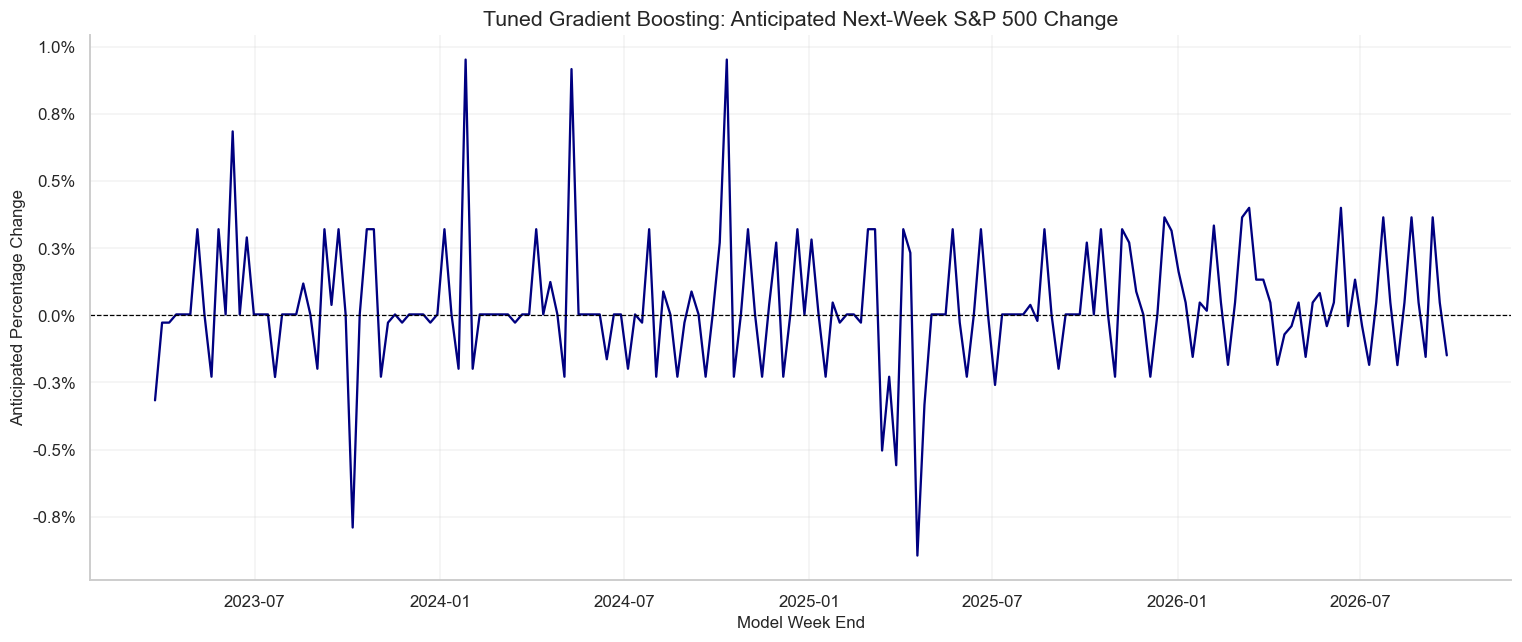

In [55]:
# CONSOLIDATED TEST-PERIOD PREDICTIONS

BEST_TUNED_FEATURES = TUNING_SPECS[
    BEST_TUNED_MODEL_NAME
]["features"]

test_prediction_data = (
    v9_controlled_matched_frame.loc[
        v9_controlled_matched_frame[DATE_COL].between(
            TEST_START_DATE,
            LAST_KNOWN_TARGET_DATE,
        )
        & v9_controlled_matched_frame[TARGET_COL].notna()
    ]
    .copy()
    .reset_index(drop=True)
)

assert len(test_prediction_data) == len(test_dates) == 184
assert test_prediction_data[DATE_COL].equals(test_dates)

test_prediction_data["anticipated_pct_change"] = (
    TUNED_PIPELINES[BEST_TUNED_MODEL_NAME].predict(
        test_prediction_data[BEST_TUNED_FEATURES]
    )
)

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    test_prediction_data[DATE_COL],
    test_prediction_data["anticipated_pct_change"],
    color="navy",
    linewidth=1.5,
)

ax.axhline(
    0,
    color="black",
    linewidth=0.8,
    linestyle="--",
)

ax.set_title(
    "Tuned Gradient Boosting: Anticipated Next-Week S&P 500 Change"
)
ax.set_xlabel("Model Week End")
ax.set_ylabel("Anticipated Percentage Change")

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda value, position: f"{value:.1%}"
    )
)

ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

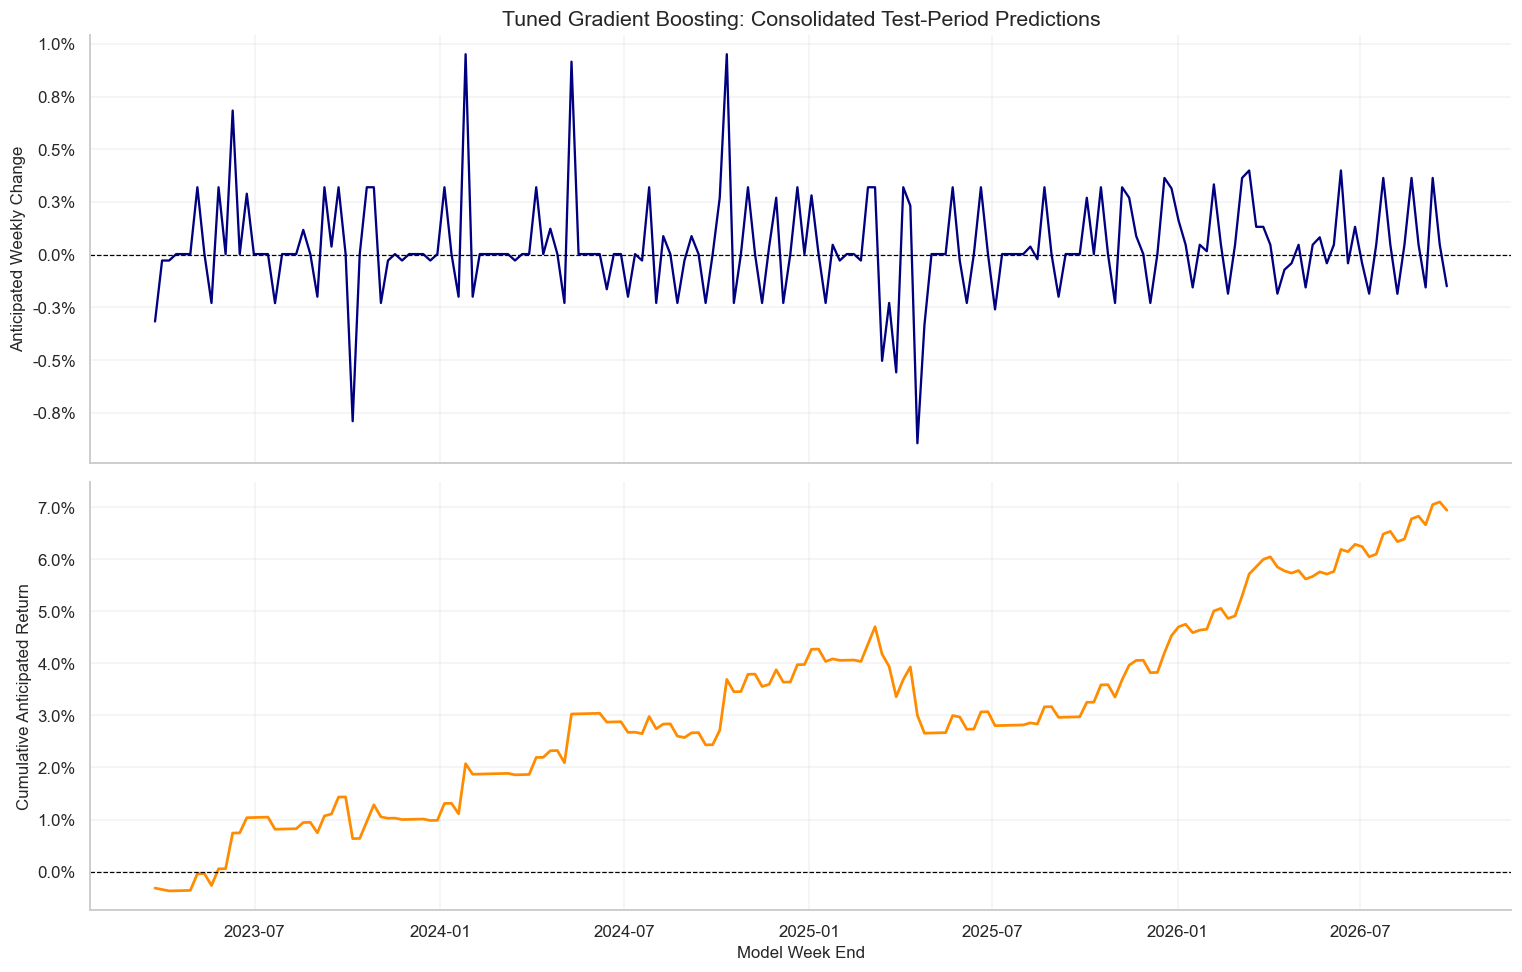

In [56]:
# WEEKLY AND CUMULATIVE ANTICIPATED CHANGES

test_prediction_data[
    "cumulative_anticipated_return"
] = (
    1.0
    + test_prediction_data[
        "anticipated_pct_change"
    ]
).cumprod() - 1.0

fig, (ax_weekly, ax_cumulative) = plt.subplots(
    2,
    1,
    figsize=(14, 9),
    sharex=True,
)

# Weekly anticipated percentage change
ax_weekly.plot(
    test_prediction_data[DATE_COL],
    test_prediction_data["anticipated_pct_change"],
    color="navy",
    linewidth=1.5,
)

ax_weekly.axhline(
    0,
    color="black",
    linewidth=0.8,
    linestyle="--",
)

ax_weekly.set_title(
    "Tuned Gradient Boosting: Consolidated Test-Period Predictions"
)
ax_weekly.set_ylabel(
    "Anticipated Weekly Change"
)
ax_weekly.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda value, position: f"{value:.1%}"
    )
)
ax_weekly.grid(alpha=0.25)

# Cumulative compounded anticipated return
ax_cumulative.plot(
    test_prediction_data[DATE_COL],
    test_prediction_data[
        "cumulative_anticipated_return"
    ],
    color="darkorange",
    linewidth=1.8,
)

ax_cumulative.axhline(
    0,
    color="black",
    linewidth=0.8,
    linestyle="--",
)

ax_cumulative.set_xlabel("Model Week End")
ax_cumulative.set_ylabel(
    "Cumulative Anticipated Return"
)
ax_cumulative.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda value, position: f"{value:.1%}"
    )
)
ax_cumulative.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### 11 Model Comparison Interpretation and Selection

In [57]:
# STEP 11: MODEL COMPARISON, INTERPRETATION, AND SELECTION

from sklearn.inspection import permutation_importance


# 1. FINAL CANDIDATE COMPARISON

benchmark_folds = CV_BENCHMARK_FOLD_RESULTS.assign(
    candidate_type="benchmark",
    feature_count=0,
).copy()
benchmark_folds["model"] = benchmark_folds["benchmark"]

tuned_folds = STEP10_FOLD_RESULTS.assign(
    candidate_type="tuned_model"
).copy()
tuned_folds["feature_count"] = tuned_folds["model"].map(
    lambda model: len(TUNING_SPECS[model]["features"])
)

STEP11_FOLD_RESULTS = pd.concat(
    [
        benchmark_folds[
            [
                "candidate_type", "model", "feature_count",
                "fold", "mae", "rmse", "r2",
            ]
        ],
        tuned_folds[
            [
                "candidate_type", "model", "feature_count",
                "fold", "mae", "rmse", "r2",
            ]
        ],
    ],
    ignore_index=True,
)

benchmark_mae_by_fold = (
    benchmark_folds.loc[
        benchmark_folds["model"].eq(best_benchmark_name)
    ]
    .set_index("fold")["mae"]
)

STEP11_FOLD_RESULTS["beats_benchmark_fold"] = [
    mae < benchmark_mae_by_fold.loc[fold]
    for mae, fold in zip(
        STEP11_FOLD_RESULTS["mae"],
        STEP11_FOLD_RESULTS["fold"],
    )
]

STEP11_MODEL_COMPARISON = (
    STEP11_FOLD_RESULTS
    .groupby(
        ["candidate_type", "model"],
        sort=False,
    )
    .agg(
        features=("feature_count", "first"),
        validation_mae=("mae", "mean"),
        mae_std=(
            "mae",
            lambda values: np.std(values, ddof=0),
        ),
        validation_rmse=("rmse", "mean"),
        validation_r2=("r2", "mean"),
        folds_beating_benchmark=(
            "beats_benchmark_fold",
            "sum",
        ),
        fold_mae=(
            "mae",
            lambda values: tuple(np.round(values, 4)),
        ),
    )
    .reset_index()
)

model_profiles = {
    "historical_mean": ("minimal", "high"),
    "zero_return": ("minimal", "high"),
    "ridge": ("moderate", "high"),
    "elastic_net": ("moderate", "high"),
    "random_forest": ("high", "low"),
    "gradient_boosting": ("high", "low"),
}

STEP11_MODEL_COMPARISON[
    ["complexity", "interpretability"]
] = (
    STEP11_MODEL_COMPARISON["model"]
    .map(model_profiles)
    .apply(pd.Series)
)

STEP11_MODEL_COMPARISON = (
    STEP11_MODEL_COMPARISON
    .sort_values("validation_mae")
    .reset_index(drop=True)
)


# 2. COEFFICIENTS AND PERMUTATION IMPORTANCE

coefficient_rows = []
importance_rows = []

for model_name, specification in TUNING_SPECS.items():
    features = specification["features"]

    for fold, (train_index, validation_index) in enumerate(
        CV_SPLITS,
        start=1,
    ):
        pipeline = clone(TUNED_PIPELINES[model_name])

        X_fit = X_train_controlled_unscaled.iloc[
            train_index
        ][features]
        X_validate = X_train_controlled_unscaled.iloc[
            validation_index
        ][features]

        pipeline.fit(X_fit, y_train.iloc[train_index])

        if model_name in {"ridge", "elastic_net"}:
            coefficient_rows.extend(
                {
                    "model": model_name,
                    "fold": fold,
                    "feature": feature,
                    "coefficient": coefficient,
                }
                for feature, coefficient in zip(
                    features,
                    pipeline.named_steps["model"].coef_,
                )
            )
        else:
            importance = permutation_importance(
                pipeline,
                X_validate,
                y_train.iloc[validation_index],
                scoring="neg_mean_absolute_error",
                n_repeats=3,
                random_state=RANDOM_SEED + fold,
                n_jobs=1,
            )

            importance_rows.extend(
                {
                    "model": model_name,
                    "fold": fold,
                    "feature": feature,
                    "mae_increase": value,
                }
                for feature, value in zip(
                    features,
                    importance.importances_mean,
                )
            )

STEP11_LINEAR_COEFFICIENTS = (
    pd.DataFrame(coefficient_rows)
    .groupby(["model", "feature"], sort=False)
    .agg(
        coefficient_mean=("coefficient", "mean"),
        coefficient_std=("coefficient", "std"),
        sign_consistency=(
            "coefficient",
            coefficient_sign_consistency,
        ),
    )
    .reset_index()
    .assign(
        absolute_mean=lambda frame:
        frame["coefficient_mean"].abs()
    )
    .sort_values(
        ["model", "absolute_mean"],
        ascending=[True, False],
    )
    .groupby("model", sort=False)
    .head(5)
    .drop(columns="absolute_mean")
    .reset_index(drop=True)
)

STEP11_NONLINEAR_IMPORTANCE = (
    pd.DataFrame(importance_rows)
    .groupby(["model", "feature"], sort=False)
    .agg(
        mae_increase_mean=("mae_increase", "mean"),
        mae_increase_std=("mae_increase", "std"),
        positive_fold_share=(
            "mae_increase",
            lambda x: np.mean(x > 0),
        ),
    )
    .reset_index()
    .sort_values(
        ["model", "mae_increase_mean"],
        ascending=[True, False],
    )
    .groupby("model", sort=False)
    .head(5)
    .reset_index(drop=True)
)


# 3. THRESHOLD SUPPORT AND INSTABILITY

STEP11_THRESHOLD_SUPPORT = STEP8_THRESHOLD_SUPPORT[
    [
        "threshold_id",
        "training_activations",
        "supported_training_folds",
        "eligible_for_cv",
        "status",
    ]
].copy()

STEP11_UNSUPPORTED_THRESHOLDS = (
    STEP11_THRESHOLD_SUPPORT.loc[
        ~STEP11_THRESHOLD_SUPPORT["eligible_for_cv"]
    ]
    .reset_index(drop=True)
)

STEP11_UNSTABLE_THRESHOLDS = (
    STEP8_COEFFICIENT_STABILITY
    .reset_index()
    .loc[
        lambda frame:
        frame["sign_consistency"].lt(0.80)
        | frame["nonzero_fold_share"].lt(0.80)
    ]
    .sort_values(
        "coefficient_mean",
        key=lambda x: x.abs(),
        ascending=False,
    )
    .head(10)
    .reset_index(drop=True)
)


# 4. FREEZE THE UNCHANGED STEP-10 WINNER

FINAL_MODEL_NAME = BEST_TUNED_MODEL_NAME
FINAL_FEATURES = tuple(
    TUNING_SPECS[FINAL_MODEL_NAME]["features"]
)
FINAL_MODEL_PARAMETERS = dict(
    TUNING_SELECTION_RESULTS.loc[
        FINAL_MODEL_NAME,
        "selected_parameters",
    ]
)

FINAL_MODEL_PIPELINE = clone(
    TUNED_PIPELINES[FINAL_MODEL_NAME]
).fit(
    X_train_controlled_unscaled[list(FINAL_FEATURES)],
    y_train,
)

final_result = STEP10_RESULTS.loc[FINAL_MODEL_NAME]

STEP11_SUMMARY = pd.Series(
    {
        "final_model": FINAL_MODEL_NAME,
        "feature_stage": TUNING_SPECS[
            FINAL_MODEL_NAME
        ]["feature_stage"],
        "feature_count": len(FINAL_FEATURES),
        "selected_parameters": FINAL_MODEL_PARAMETERS,
        "validation_mae": final_result["validation_mae"],
        "validation_mae_std": final_result[
            "validation_mae_std"
        ],
        "validation_rmse": final_result["validation_rmse"],
        "validation_r2": final_result["validation_r2"],
        "beats_best_benchmark": bool(
            final_result["beats_best_benchmark"]
        ),
        "excessive_gap_flag": bool(
            final_result["excessive_gap_flag"]
        ),
        "unsupported_thresholds": len(
            STEP11_UNSUPPORTED_THRESHOLDS
        ),
        "manual_weights_used": False,
        "test_metrics_used_for_selection": False,
        "final_model_frozen": True,
        "selection_reason": (
            "Frozen unchanged from Step 10 because Gradient "
            "Boosting had the lowest tuned-model training-CV "
            "MAE. It did not beat the historical-mean benchmark."
        ),
        "step11_status": "PASS",
    },
    name="Step 11 model selection",
)

assert FINAL_MODEL_NAME == "gradient_boosting"
assert len(FINAL_FEATURES) == 63
assert not STEP11_SUMMARY["test_metrics_used_for_selection"]


display(STEP11_SUMMARY)
display(STEP11_MODEL_COMPARISON)
display(STEP11_LINEAR_COEFFICIENTS)
display(STEP11_NONLINEAR_IMPORTANCE)
display(STEP11_THRESHOLD_SUPPORT)
display(STEP11_UNSUPPORTED_THRESHOLDS)
display(STEP11_UNSTABLE_THRESHOLDS)

final_model                                                        gradient_boosting
feature_stage                                                     broader_engineered
feature_count                                                                     63
selected_parameters                {'learning_rate': 0.03, 'max_depth': 1, 'min_s...
validation_mae                                                                0.0202
validation_mae_std                                                            0.0064
validation_rmse                                                               0.0249
validation_r2                                                                -0.0757
beats_best_benchmark                                                           False
excessive_gap_flag                                                             False
unsupported_thresholds                                                             7
manual_weights_used                                              

,candidate_type,model,features,validation_mae,mae_std,validation_rmse,validation_r2,folds_beating_benchmark,fold_mae,complexity,interpretability
0,benchmark,historical_mean,0,0.0201,0.0066,0.0246,-0.0341,0,"(0.02, 0.01, 0.0187, 0.0307, 0.0212)",minimal,high
1,benchmark,zero_return,0,0.0202,0.0061,0.0247,-0.0579,1,"(0.0204, 0.0107, 0.0189, 0.0297, 0.0212)",minimal,high
2,tuned_model,gradient_boosting,63,0.0202,0.0064,0.0249,-0.0757,2,"(0.0195, 0.0105, 0.0189, 0.0305, 0.0216)",high,low
3,tuned_model,elastic_net,47,0.0203,0.0067,0.0248,-0.0584,3,"(0.02, 0.0107, 0.0179, 0.0315, 0.0212)",moderate,high
4,tuned_model,ridge,47,0.0204,0.0060,0.0251,-0.1332,2,"(0.0198, 0.0121, 0.0187, 0.0308, 0.0208)",moderate,high
5,tuned_model,random_forest,15,0.0208,0.0061,0.0252,-0.1177,2,"(0.0194, 0.0113, 0.0193, 0.03, 0.024)",high,low


,model,feature,coefficient_mean,coefficient_std,sign_consistency
0,elastic_net,thr_vix_change_above_pos_5_excess,-0.0034,0.0016,1.0000
1,elastic_net,thr_sp500_below_neg_2pct_flag,0.0020,0.0011,1.0000
2,elastic_net,thr_baa10y_spread_above_250bp_excess,0.0017,0.0005,1.0000
3,elastic_net,thr_usd_change_below_neg_1pct_excess,0.0002,0.0004,0.8000
4,elastic_net,thr_usd_change_above_pos_1pct_flag,0.0002,0.0004,0.6000
5,ridge,thr_sp500_below_neg_2pct_flag,0.0040,0.0005,1.0000
6,ridge,thr_vix_change_above_pos_5_excess,-0.0033,0.0001,1.0000
7,ridge,thr_baa10y_spread_above_250bp_excess,0.0029,0.0004,1.0000
8,ridge,thr_vix_change_above_pos_5_flag,0.0026,0.0012,1.0000
9,ridge,thr_sp500_below_neg_2pct_excess,-0.0025,0.0004,1.0000


,model,feature,mae_increase_mean,mae_increase_std,positive_fold_share
0,gradient_boosting,nfci_level_lag_2w,0.0002,0.0003,0.2000
1,gradient_boosting,sp500_weekly_pct_chg,0.0001,0.0003,0.6000
2,gradient_boosting,sp500_weekly_pct_chg_lag_2w,0.0001,0.0002,0.4000
3,gradient_boosting,initial_claims_weekly_pct_chg,0.0001,0.0001,0.6000
4,gradient_boosting,thr_sp500_below_neg_2pct_excess,0.0001,0.0001,0.2000
5,random_forest,sp500_weekly_pct_chg,0.0004,0.0007,0.6000
6,random_forest,baa10y_yield_spread,0.0001,0.0002,0.4000
7,random_forest,treasury_10y_yield_level,0.0000,0.0001,0.2000
8,random_forest,initial_claims_weekly_pct_chg,0.0000,0.0001,0.6000
9,random_forest,sp500_forward_pe_level,0.0000,0.0000,0.4000


,threshold_id,training_activations,supported_training_folds,eligible_for_cv,status
0,sp500_below_neg_2pct,41,5,True,eligible
1,sp500_above_pos_2pct,47,5,True,eligible
2,fed_funds_cut_25bp,4,0,False,insufficient training support
3,fed_funds_hike_25bp,10,1,False,insufficient training support
4,vix_change_below_neg_5,13,5,True,eligible
5,vix_change_above_pos_5,17,5,True,eligible
6,wti_change_below_neg_5pct,43,5,True,eligible
7,wti_change_above_pos_5pct,47,5,True,eligible
8,usd_change_below_neg_1pct,16,5,True,eligible
9,usd_change_above_pos_1pct,21,5,True,eligible


,threshold_id,training_activations,supported_training_folds,eligible_for_cv,status
0,fed_funds_cut_25bp,4,0,False,insufficient training support
1,fed_funds_hike_25bp,10,1,False,insufficient training support
2,nfci_above_zero,8,5,False,insufficient training support
3,fed_funds_above_4pct,14,0,False,insufficient training support
4,treasury_10y_above_5_25pct,0,0,False,provisional: no training activations
5,tips_10y_above_3_25pct,0,0,False,insufficient training support
6,wti_price_above_90,32,2,False,insufficient training support


,feature,coefficient_mean,coefficient_std,nonzero_fold_share,sign_consistency
0,thr_sp500_below_neg_2pct_excess,-0.0031,0.0029,0.6000,0.6000
1,thr_vix_change_above_pos_5_excess,-0.0015,0.0027,0.6000,0.6000
2,thr_wti_change_above_pos_5pct_flag,0.0006,0.0008,0.6000,0.6000
3,thr_forward_pe_above_20_excess,0.0003,0.0007,0.2000,0.8000
4,thr_forward_pe_below_16_flag,-0.0002,0.0003,0.6000,0.6000
5,thr_vix_change_below_neg_5_flag,0.0002,0.0004,0.2000,0.8000
6,thr_wei_below_zero_flag,0.0001,0.0002,0.2000,0.8000
7,thr_wti_change_below_neg_5pct_excess,0.0001,0.0001,0.2000,0.8000
8,thr_claims_change_below_neg_5pct_flag,-0.0000,0.0000,0.2000,0.8000
9,thr_sp500_above_pos_2pct_excess,0.0000,0.0000,0.0000,1.0000


### 12 Final Test Evaluation and Retained Row Forecast

frozen_model                                                            gradient_boosting
frozen_feature_count                                                                   63
frozen_parameters                       {'learning_rate': 0.03, 'max_depth': 1, 'min_s...
training_observations_used_for_refit                                                  348
consolidated_test_observations                                                         99
test_start                                                                     2024-11-08
test_end                                                                       2026-09-25
original_test_rows_reconciled                                                          88
added_rows_reported_separately                                                      False
test_used_for_model_changes                                                         False
validation_conclusion                   Supports the training-period validation result...
step12_sta

,mae,rmse,r2,directional_accuracy
historical_mean,0.0152,0.0206,-0.0000,0.5556
gradient_boosting,0.0153,0.0206,-0.0059,0.5455
zero_return,0.0154,0.0207,-0.0182,0.0000


rows                                       88
first_date                         2024-11-08
last_date                          2026-07-10
weekly_date_sequence_matches             True
targets_match_v9_source                  True
missing_predictions                         0
separate_performance_evaluation         False
Name: first 88 rows: integrity check only, dtype: object

,model_week_end,actual_return,predicted_return,residual,absolute_error
0,2025-03-28,-0.0908,-0.0043,-0.0865,0.0865
1,2025-04-18,0.0459,-0.0074,0.0533,0.0533
2,2025-05-09,0.0527,0.0014,0.0514,0.0514
3,2025-04-04,0.0570,0.0058,0.0513,0.0513
4,2026-04-10,0.0454,0.0010,0.0444,0.0444
5,2025-02-28,-0.0310,0.0054,-0.0363,0.0363
6,2026-07-31,0.0358,0.0010,0.0348,0.0348
7,2026-04-03,0.0356,0.0014,0.0342,0.0342
8,2025-11-21,0.0373,0.0054,0.0319,0.0319
9,2025-04-25,0.0292,-0.0021,0.0314,0.0314


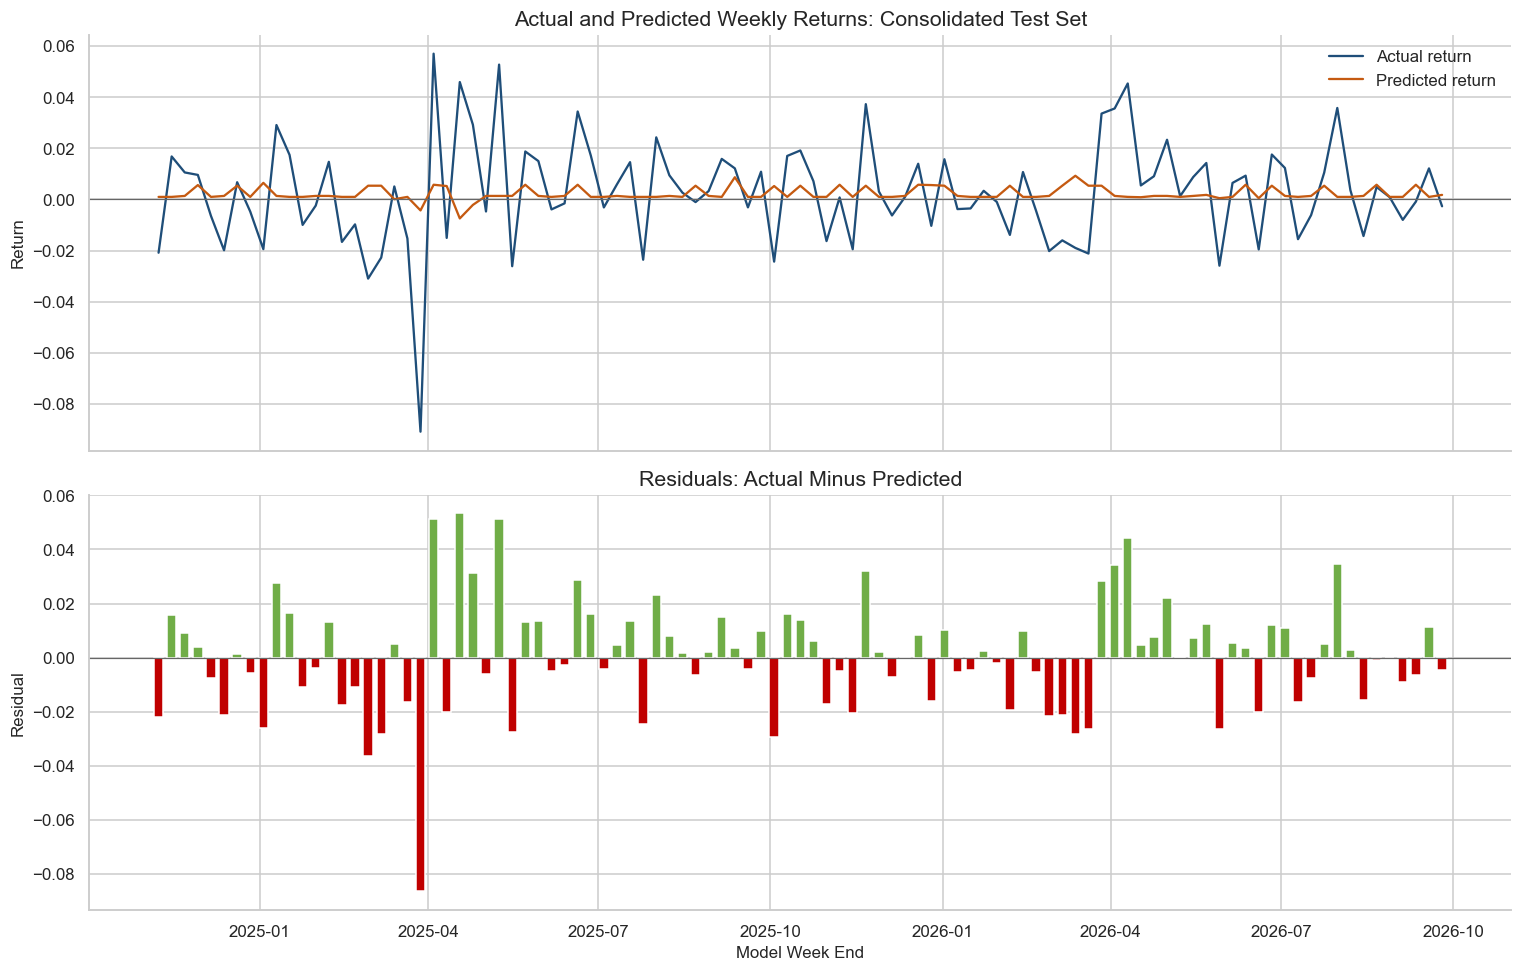

,threshold_id,frozen_step11_status,sparse_training_support,included_in_final_features,step11_training_activations,step12_refit_training_activations,consolidated_test_activations,test_mae_when_active,test_mae_when_inactive
0,sp500_below_neg_2pct,eligible,False,True,41,47,13,0.0199,0.0146
1,sp500_above_pos_2pct,eligible,False,True,47,60,17,0.0130,0.0157
2,fed_funds_cut_25bp,insufficient training support,True,False,4,5,4,0.0054,0.0157
3,fed_funds_hike_25bp,insufficient training support,True,False,10,13,1,0.0111,0.0153
4,vix_change_below_neg_5,eligible,False,True,13,15,6,0.0176,0.0151
5,vix_change_above_pos_5,eligible,False,True,17,18,7,0.0252,0.0145
6,wti_change_below_neg_5pct,eligible,False,True,43,50,11,0.0154,0.0152
7,wti_change_above_pos_5pct,eligible,False,True,47,54,17,0.0192,0.0144
8,usd_change_below_neg_1pct,eligible,False,True,16,19,6,0.0141,0.0153
9,usd_change_above_pos_1pct,eligible,False,True,21,22,6,0.0110,0.0155


,threshold_id,frozen_step11_status,sparse_training_support,included_in_final_features,step11_training_activations,step12_refit_training_activations,consolidated_test_activations,test_mae_when_active,test_mae_when_inactive
0,fed_funds_cut_25bp,insufficient training support,True,False,4,5,4,0.0054,0.0157
1,fed_funds_hike_25bp,insufficient training support,True,False,10,13,1,0.0111,0.0153
2,nfci_above_zero,insufficient training support,True,False,8,8,0,NaN,0.0153
3,fed_funds_above_4pct,insufficient training support,True,False,14,97,51,0.0175,0.0129
4,treasury_10y_above_5_25pct,provisional: no training activations,True,False,0,0,0,NaN,0.0153
5,tips_10y_above_3_25pct,insufficient training support,True,False,0,0,0,NaN,0.0153
6,wti_price_above_90,insufficient training support,True,False,32,31,16,0.0153,0.0152


result_type                        forecast (not a performance result)
model_week_end                                              2026-10-02
forecast_target_week_end                                    2026-10-09
all_required_features_available                                   True
predicted_next_week_return                                      0.0014
prediction_rule_signal                                      Investment
used_for_performance_evaluation                                  False
Name: retained-row forecast, dtype: object

In [58]:
# STEP 12: FINAL TEST EVALUATION AND RETAINED-ROW FORECAST

STEP12_TEST_START = pd.Timestamp("2024-11-08")
STEP12_ORIGINAL_TEST_END = pd.Timestamp("2026-07-10")
STEP12_TEST_END = pd.Timestamp("2026-09-25")
STEP12_FORECAST_DATE = pd.Timestamp("2026-10-02")

# Preserve the fixed V9 Model Data sample.
retained_rows = normalize_v9_dates(
    v9_model_data_raw,
    [DATE_COL],
)[[DATE_COL, TARGET_COL]]

step12_frame = retained_rows.merge(
    v9_controlled_feature_calendar[
        [DATE_COL, *PREDICTORS, *ALL_ENGINEERED_CANDIDATES]
    ],
    on=DATE_COL,
    how="left",
    validate="one_to_one",
)

step12_train = step12_frame.loc[
    step12_frame[DATE_COL].lt(STEP12_TEST_START)
    & step12_frame[TARGET_COL].notna()
].reset_index(drop=True)

step12_test = step12_frame.loc[
    step12_frame[DATE_COL].between(
        STEP12_TEST_START,
        STEP12_TEST_END,
    )
    & step12_frame[TARGET_COL].notna()
].reset_index(drop=True)

step12_forecast_row = step12_frame.loc[
    step12_frame[DATE_COL].eq(STEP12_FORECAST_DATE)
    & step12_frame[TARGET_COL].isna()
].reset_index(drop=True)

assert len(retained_rows) == 448
assert len(step12_train) == 348
assert len(step12_test) == 99
assert len(step12_forecast_row) == 1
assert step12_test[DATE_COL].iloc[0] == STEP12_TEST_START
assert step12_test[DATE_COL].iloc[-1] == STEP12_TEST_END
assert step12_test[DATE_COL].iloc[87] == STEP12_ORIGINAL_TEST_END

X_step12_train = step12_train[list(FINAL_FEATURES)]
y_step12_train = step12_train[TARGET_COL]
X_step12_test = step12_test[list(FINAL_FEATURES)]
y_step12_test = step12_test[TARGET_COL]

# Refit the unchanged frozen pipeline on all 348 training observations.
STEP12_FINAL_PIPELINE = clone(FINAL_MODEL_PIPELINE)
STEP12_FINAL_PIPELINE.fit(X_step12_train, y_step12_train)

step12_predictions = STEP12_FINAL_PIPELINE.predict(X_step12_test)

benchmark_predictions = {
    "historical_mean": np.full(
        len(step12_test),
        y_step12_train.mean(),
    ),
    "zero_return": np.zeros(len(step12_test)),
}

STEP12_TEST_COMPARISON = pd.DataFrame(
    {
        "gradient_boosting": calculate_regression_metrics(
            y_step12_test,
            step12_predictions,
        ),
        **{
            name: calculate_regression_metrics(
                y_step12_test,
                predictions,
            )
            for name, predictions in benchmark_predictions.items()
        },
    }
).T.sort_values("mae")

STEP12_PREDICTIONS = step12_test[
    [DATE_COL, TARGET_COL]
].rename(columns={TARGET_COL: "actual_return"})

STEP12_PREDICTIONS["predicted_return"] = step12_predictions
STEP12_PREDICTIONS["residual"] = (
    STEP12_PREDICTIONS["actual_return"]
    - STEP12_PREDICTIONS["predicted_return"]
)
STEP12_PREDICTIONS["absolute_error"] = (
    STEP12_PREDICTIONS["residual"].abs()
)

STEP12_LARGEST_ERRORS = (
    STEP12_PREDICTIONS
    .nlargest(10, "absolute_error")
    .reset_index(drop=True)
)

# Reconcile the original 88 observations as an integrity check only.
first_88 = STEP12_PREDICTIONS.iloc[:88]
expected_88_dates = pd.date_range(
    STEP12_TEST_START,
    STEP12_ORIGINAL_TEST_END,
    freq="W-FRI",
)

target_lookup = normalize_v9_dates(
    v9_target_source,
    [DATE_COL],
).set_index(DATE_COL)[TARGET_COL]

STEP12_FIRST88_RECONCILIATION = pd.Series(
    {
        "rows": len(first_88),
        "first_date": first_88[DATE_COL].iloc[0].date(),
        "last_date": first_88[DATE_COL].iloc[-1].date(),
        "weekly_date_sequence_matches": (
            first_88[DATE_COL]
            .reset_index(drop=True)
            .equals(pd.Series(expected_88_dates, name=DATE_COL))
        ),
        "targets_match_v9_source": np.allclose(
            first_88["actual_return"],
            target_lookup.loc[
                first_88[DATE_COL]
            ].to_numpy(dtype=float),
        ),
        "missing_predictions": int(
            first_88["predicted_return"].isna().sum()
        ),
        "separate_performance_evaluation": False,
    },
    name="first 88 rows: integrity check only",
)

model_mae = STEP12_TEST_COMPARISON.loc[
    "gradient_boosting",
    "mae",
]
historical_mean_mae = STEP12_TEST_COMPARISON.loc[
    "historical_mean",
    "mae",
]

STEP12_VALIDATION_CONCLUSION = (
    "Supports the training-period validation result: "
    "the frozen model did not beat the historical-mean benchmark "
    "on the consolidated test set."
    if model_mae >= historical_mean_mae
    else
    "Does not reinforce the training-period benchmark result: "
    "the frozen model beat the historical-mean benchmark "
    "on the consolidated test set."
)

STEP12_SUMMARY = pd.Series(
    {
        "frozen_model": FINAL_MODEL_NAME,
        "frozen_feature_count": len(FINAL_FEATURES),
        "frozen_parameters": FINAL_MODEL_PARAMETERS,
        "training_observations_used_for_refit": len(step12_train),
        "consolidated_test_observations": len(step12_test),
        "test_start": step12_test[DATE_COL].iloc[0].date(),
        "test_end": step12_test[DATE_COL].iloc[-1].date(),
        "original_test_rows_reconciled": len(first_88),
        "added_rows_reported_separately": False,
        "test_used_for_model_changes": False,
        "validation_conclusion": STEP12_VALIDATION_CONCLUSION,
        "step12_status": "PASS",
    },
    name="final consolidated test evaluation",
)

display(STEP12_SUMMARY)
display(STEP12_TEST_COMPARISON)
display(STEP12_FIRST88_RECONCILIATION)
display(STEP12_LARGEST_ERRORS)

fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 9),
    sharex=True,
)

axes[0].plot(
    STEP12_PREDICTIONS[DATE_COL],
    STEP12_PREDICTIONS["actual_return"],
    label="Actual return",
    color="#1F4E79",
    linewidth=1.5,
)
axes[0].plot(
    STEP12_PREDICTIONS[DATE_COL],
    STEP12_PREDICTIONS["predicted_return"],
    label="Predicted return",
    color="#C55A11",
    linewidth=1.5,
)
axes[0].axhline(0, color="#666666", linewidth=0.8)
axes[0].set_title(
    "Actual and Predicted Weekly Returns: Consolidated Test Set"
)
axes[0].set_ylabel("Return")
axes[0].legend()

axes[1].bar(
    STEP12_PREDICTIONS[DATE_COL],
    STEP12_PREDICTIONS["residual"],
    width=5,
    color=np.where(
        STEP12_PREDICTIONS["residual"].ge(0),
        "#70AD47",
        "#C00000",
    ),
)
axes[1].axhline(0, color="#666666", linewidth=0.8)
axes[1].set_title("Residuals: Actual Minus Predicted")
axes[1].set_ylabel("Residual")
axes[1].set_xlabel("Model Week End")

plt.tight_layout()
plt.show()


# THRESHOLD-REGIME DIAGNOSTICS

threshold_records = []

for threshold_id, rule in THRESHOLD_REGISTRY.iterrows():
    indicator = rule["indicator_feature"]
    active_test_regime = step12_test[indicator].eq(1)

    frozen_support = STEP11_THRESHOLD_SUPPORT.loc[
        STEP11_THRESHOLD_SUPPORT["threshold_id"].eq(
            threshold_id
        )
    ].iloc[0]

    threshold_records.append(
        {
            "threshold_id": threshold_id,
            "frozen_step11_status": frozen_support["status"],
            "sparse_training_support": (
                frozen_support["status"] != "eligible"
            ),
            "included_in_final_features": (
                indicator in FINAL_FEATURES
                or rule["excess_feature"] in FINAL_FEATURES
            ),
            "step11_training_activations": int(
                frozen_support["training_activations"]
            ),
            "step12_refit_training_activations": int(
                step12_train[indicator].sum()
            ),
            "consolidated_test_activations": int(
                active_test_regime.sum()
            ),
            "test_mae_when_active": (
                STEP12_PREDICTIONS.loc[
                    active_test_regime,
                    "absolute_error",
                ].mean()
            ),
            "test_mae_when_inactive": (
                STEP12_PREDICTIONS.loc[
                    ~active_test_regime,
                    "absolute_error",
                ].mean()
            ),
        }
    )

STEP12_THRESHOLD_DIAGNOSTICS = pd.DataFrame(
    threshold_records
)

STEP12_SPARSE_REGIMES = (
    STEP12_THRESHOLD_DIAGNOSTICS.loc[
        STEP12_THRESHOLD_DIAGNOSTICS[
            "sparse_training_support"
        ]
    ]
    .reset_index(drop=True)
)

assert len(STEP12_THRESHOLD_DIAGNOSTICS) == 23
assert len(STEP12_SPARSE_REGIMES) == 7

display(STEP12_THRESHOLD_DIAGNOSTICS)
display(STEP12_SPARSE_REGIMES)


# RETAINED-ROW FORECAST

required_features_available = bool(
    step12_forecast_row[list(FINAL_FEATURES)]
    .notna()
    .all()
    .all()
    and np.isfinite(
        step12_forecast_row[
            list(FINAL_FEATURES)
        ].to_numpy(dtype=float)
    ).all()
)

forecast_value = (
    float(
        STEP12_FINAL_PIPELINE.predict(
            step12_forecast_row[
                list(FINAL_FEATURES)
            ]
        )[0]
    )
    if required_features_available
    else np.nan
)

STEP12_RETAINED_ROW_FORECAST = pd.Series(
    {
        "result_type": "forecast (not a performance result)",
        "model_week_end": STEP12_FORECAST_DATE.date(),
        "forecast_target_week_end": (
            STEP12_FORECAST_DATE
            + pd.Timedelta(weeks=1)
        ).date(),
        "all_required_features_available": (
            required_features_available
        ),
        "predicted_next_week_return": forecast_value,
        "prediction_rule_signal": (
            "Investment"
            if forecast_value > 0
            else "No Investment"
        )
        if np.isfinite(forecast_value)
        else "Unavailable",
        "used_for_performance_evaluation": False,
    },
    name="retained-row forecast",
)

assert required_features_available

display(STEP12_RETAINED_ROW_FORECAST)

### 13 Conclusions Limitations and Submission Check

### Model Summary
- The model is a Gradient Boosting regression model using 63 engineered features (see below for list of features).
- It predicts the following week’s S&P 500 return.
- The model was trained on 348 observations.

63 Engineered Features
Model Features:
- S&P 500 weekly percentage change
- Federal-funds rate level
- Federal-funds weekly basis-point change
- VIX level
- VIX weekly point change
- 10-year Treasury yield
- 10-year TIPS yield
- 10-year/3-month Treasury yield spread
- Baa–10-year Treasury yield spread
- WTI weekly percentage change
- Broad U.S. dollar weekly percentage change
- Initial unemployment claims weekly percentage change
- Weekly Economic Index level
- National Financial Conditions Index level
- S&P 500 forward P/E level

Two-Week Lagged Features:
- The model used two-week lags of the 15 predictors above, plus the WTI price level:
- S&P 500 weekly change, lagged two weeks
- Federal-funds level, lagged two weeks
- Federal-funds weekly change, lagged two weeks
- VIX level, lagged two weeks
- VIX weekly change, lagged two weeks
- 10-year Treasury yield, lagged two weeks
- 10-year TIPS yield, lagged two weeks
- 10-year/3-month spread, lagged two weeks
- Baa–10-year Treasury spread, lagged two weeks
- WTI weekly change, lagged two weeks
- WTI price level, lagged two weeks
- Broad U.S. dollar weekly change, lagged two weeks
- Initial claims weekly change, lagged two weeks
- Weekly Economic Index, lagged two weeks
- National Financial Conditions Index, lagged two weeks
- S&P 500 forward P/E, lagged two weeks

Threshold Features:
- S&P 500 return below −2%: flag and excess
- S&P 500 return above +2%: flag and excess
- VIX weekly change below −5 points: flag and excess
- VIX weekly change above +5 points: flag and excess
- WTI weekly change below −5%: flag and excess
- WTI weekly change above +5%: flag and excess
- U.S. dollar weekly change below −1%: flag and excess
- U.S. dollar weekly change above +1%: flag and excess
- Initial-claims weekly change below −5%: flag and excess
- Initial-claims weekly change above +5%: flag and excess
- Yield curve below zero: flag and excess
- Weekly Economic Index below zero: flag and excess
- Forward P/E below 16: flag and excess
- Forward P/E above 20: flag and excess
- VIX above 25: flag and excess
- Baa–10-year Treasury spread above 250 basis points: flag and excess

### Optimization Process
The optimization began by establishing historical-mean and zero-return benchmarks. Ridge and Elastic Net were then evaluated as regularized linear alternatives. Random Forest and Gradient Boosting were tested to determine whether nonlinear relationships improved prediction.

Feature engineering was performed in controlled stages. The project evaluated the original predictors, WTI price level, one-, two-, and four-week lags, rolling and momentum measures, supported economic thresholds, and timing-regime interactions. Only the two-week lags and supported threshold features improved training-period cross-validation and were retained, producing the final 63-feature specification.

Ridge, Elastic Net, Random Forest, and Gradient Boosting were tuned using the same five training-period folds. The search adjusted regularization strength for the linear models and tree count, learning rate, tree depth, and minimum leaf size for the nonlinear models. Mean absolute error was the primary selection measure, while RMSE, R², fold variability, and the training-versus-validation gap were also reviewed.

Gradient Boosting recorded the lowest mean validation MAE among the tuned models at 0.0202, with an MAE standard deviation of 0.0064, RMSE of 0.0249, and R² of −0.0757. It showed no excessive training-versus-validation gap, but it did not outperform the historical-mean benchmark MAE of 0.0201.

Gradient Boosting was therefore selected as the best candidate model, not as a model that had demonstrated a material benchmark advantage. Its 63 features, thresholds, and tuned parameters were frozen before the test results were examined. The frozen pipeline was then refitted on all 348 training observations and evaluated once on the consolidated test set. All predictor effects and threshold weights were estimated by the model; none were assigned manually.

### Weighting Process
No predictor or threshold weights were assigned manually. Gradient Boosting learned each feature’s contribution from the training data by building a sequence of shallow decision trees, with each tree correcting earlier prediction errors.

Permutation importance was used to assess the final model. Feature importance was generally small and inconsistent across folds, indicating limited stability and interpretability. Ten retained threshold features were classified as unstable, while seven thresholds lacked sufficient training support and were excluded.

The Treasury yield above 5.25% and TIPS yield above 3.25% thresholds never occurred in the training data. They remained provisional economic-risk indicators only and were not used by the final model.

### Investment Comparison
Using the reported forced-first-contribution convention over March 24, 2023–October 2, 2026:
- Model-timed contributions: 132 contributions, USD 13,200 invested, 18.86% money-weighted annualized return.
- Weekly $100 benchmark: 184 contributions, USD 18,400 invested, 18.84% money-weighted annualized return.

The annualized-return difference was 0.02 percentage points and was not material. Under the strict positive-prediction rule, the model would have made 131 contributions because the first prediction was negative.

,contribution_count,total_contributed,ending_value,investment_gain,money_weighted_annual_return
Model-timed contributions,132,"$13,200.00","$18,332.87","$5,132.87",18.86%
Weekly $100 benchmark,184,"$18,400.00","$25,374.61","$6,974.61",18.84%


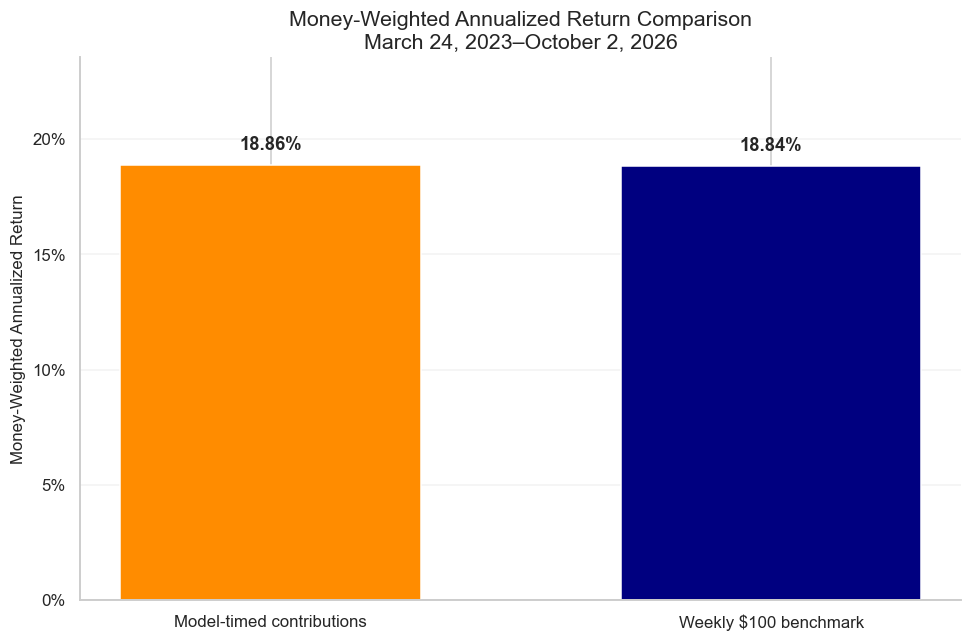

In [59]:
# MONEY-WEIGHTED MODEL STRATEGY VS. WEEKLY INVESTMENT BENCHMARK

from scipy.optimize import brentq

WEEKLY_INVESTMENT = 100.0

model_value = 0.0
benchmark_value = 0.0

model_cash_flows = []
benchmark_cash_flows = []
strategy_records = []

for row_number, row in test_prediction_data.iterrows():
    contribution_date = row[DATE_COL]
    target_week_end = (
        contribution_date
        + pd.Timedelta(weeks=1)
    )

    predicted_return = float(
        row["anticipated_pct_change"]
    )
    actual_return = float(row[TARGET_COL])

    # Model contribution rule:
    # initial $100, then $100 only after positive forecasts.
    model_contribution = (
        WEEKLY_INVESTMENT
        if row_number == 0 or predicted_return > 0
        else 0.0
    )

    # Benchmark contribution rule:
    # $100 at the beginning of every weekly period.
    benchmark_contribution = WEEKLY_INVESTMENT

    model_value += model_contribution
    benchmark_value += benchmark_contribution

    if model_contribution > 0:
        model_cash_flows.append(
            (
                contribution_date,
                -model_contribution,
            )
        )

    benchmark_cash_flows.append(
        (
            contribution_date,
            -benchmark_contribution,
        )
    )

    # Both balances earn the same actual S&P 500 return.
    model_value *= 1.0 + actual_return
    benchmark_value *= 1.0 + actual_return

    strategy_records.append(
        {
            "target_week_end": target_week_end,
            "predicted_return": predicted_return,
            "actual_sp500_return": actual_return,
            "model_contribution": model_contribution,
            "benchmark_contribution": (
                benchmark_contribution
            ),
            "model_portfolio_value": model_value,
            "benchmark_portfolio_value": (
                benchmark_value
            ),
        }
    )

MONEY_WEIGHTED_STRATEGY_PATH = pd.DataFrame(
    strategy_records
)

ending_date = MONEY_WEIGHTED_STRATEGY_PATH[
    "target_week_end"
].iloc[-1]

assert len(MONEY_WEIGHTED_STRATEGY_PATH) == 184
assert ending_date == pd.Timestamp("2026-10-02")

# Final liquidation values are positive ending cash flows.
model_cash_flows.append(
    (ending_date, model_value)
)

benchmark_cash_flows.append(
    (ending_date, benchmark_value)
)


def calculate_xirr(cash_flows):
    initial_date = cash_flows[0][0]

    def dated_npv(annual_rate):
        return sum(
            cash_flow
            / (
                (1.0 + annual_rate)
                ** (
                    (cash_flow_date - initial_date).days
                    / 365.25
                )
            )
            for cash_flow_date, cash_flow
            in cash_flows
        )

    return brentq(
        dated_npv,
        -0.9999,
        10.0,
    )


model_xirr = calculate_xirr(
    model_cash_flows
)

benchmark_xirr = calculate_xirr(
    benchmark_cash_flows
)

model_total_contributed = (
    MONEY_WEIGHTED_STRATEGY_PATH[
        "model_contribution"
    ].sum()
)

benchmark_total_contributed = (
    MONEY_WEIGHTED_STRATEGY_PATH[
        "benchmark_contribution"
    ].sum()
)

MONEY_WEIGHTED_COMPARISON = pd.DataFrame(
    {
        "contribution_count": [
            int(
                MONEY_WEIGHTED_STRATEGY_PATH[
                    "model_contribution"
                ].gt(0).sum()
            ),
            len(MONEY_WEIGHTED_STRATEGY_PATH),
        ],
        "total_contributed": [
            model_total_contributed,
            benchmark_total_contributed,
        ],
        "ending_value": [
            model_value,
            benchmark_value,
        ],
        "investment_gain": [
            model_value - model_total_contributed,
            benchmark_value
            - benchmark_total_contributed,
        ],
        "money_weighted_annual_return": [
            model_xirr,
            benchmark_xirr,
        ],
    },
    index=[
        "Model-timed contributions",
        "Weekly $100 benchmark",
    ],
)

display(
    MONEY_WEIGHTED_COMPARISON.style.format(
        {
            "total_contributed": "${:,.2f}",
            "ending_value": "${:,.2f}",
            "investment_gain": "${:,.2f}",
            "money_weighted_annual_return": "{:.2%}",
        }
    )
)

fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(
    MONEY_WEIGHTED_COMPARISON.index,
    MONEY_WEIGHTED_COMPARISON[
        "money_weighted_annual_return"
    ],
    color=["darkorange", "navy"],
    width=0.6,
)

ax.set_title(
    "Money-Weighted Annualized Return Comparison\n"
    "March 24, 2023–October 2, 2026"
)
ax.set_ylabel("Money-Weighted Annualized Return")

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda value, position: f"{value:.0%}"
    )
)

ax.set_ylim(
    0,
    MONEY_WEIGHTED_COMPARISON[
        "money_weighted_annual_return"
    ].max() * 1.25,
)

for bar, value in zip(
    bars,
    MONEY_WEIGHTED_COMPARISON[
        "money_weighted_annual_return"
    ],
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.005,
        f"{value:.2%}",
        ha="center",
        va="bottom",
        fontweight="bold",
    )

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

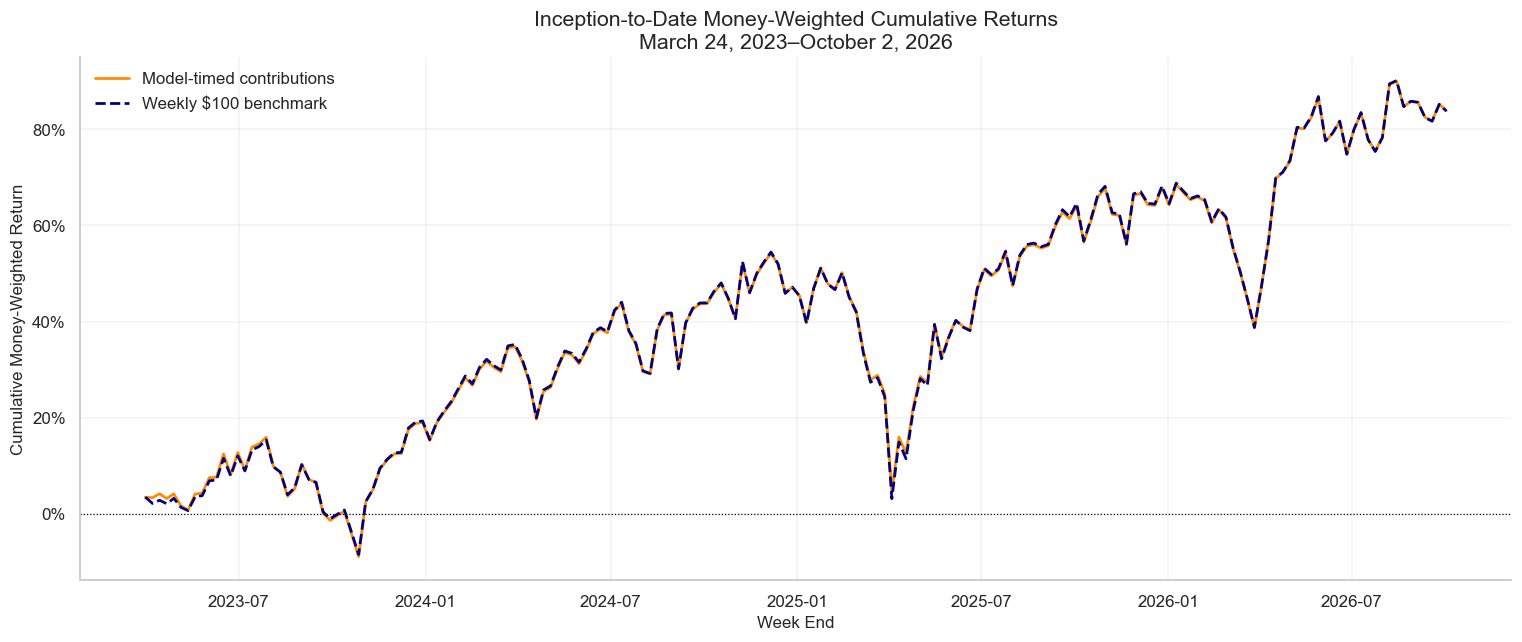

In [60]:
# WEEKLY MONEY-WEIGHTED CUMULATIVE RETURN COMPARISON

def expanding_xirr(cash_flows):
    initial_date = cash_flows[0][0]

    def dated_npv(annual_rate):
        return sum(
            cash_flow
            / (
                (1.0 + annual_rate)
                ** (
                    (cash_flow_date - initial_date).days
                    / 365.25
                )
            )
            for cash_flow_date, cash_flow
            in cash_flows
        )

    lower_bound = -0.999999
    upper_bound = 1.0

    while (
        dated_npv(lower_bound)
        * dated_npv(upper_bound)
        > 0
        and upper_bound < 1_000_000
    ):
        upper_bound = upper_bound * 2 + 1

    return brentq(
        dated_npv,
        lower_bound,
        upper_bound,
    )


model_flows_to_date = []
benchmark_flows_to_date = []
weekly_return_records = []

initial_date = (
    MONEY_WEIGHTED_STRATEGY_PATH[
        "target_week_end"
    ].iloc[0]
    - pd.Timedelta(weeks=1)
)

for _, row in MONEY_WEIGHTED_STRATEGY_PATH.iterrows():
    target_week_end = row["target_week_end"]
    contribution_date = (
        target_week_end
        - pd.Timedelta(weeks=1)
    )

    if row["model_contribution"] > 0:
        model_flows_to_date.append(
            (
                contribution_date,
                -row["model_contribution"],
            )
        )

    benchmark_flows_to_date.append(
        (
            contribution_date,
            -row["benchmark_contribution"],
        )
    )

    model_rate = expanding_xirr(
        [
            *model_flows_to_date,
            (
                target_week_end,
                row["model_portfolio_value"],
            ),
        ]
    )

    benchmark_rate = expanding_xirr(
        [
            *benchmark_flows_to_date,
            (
                target_week_end,
                row["benchmark_portfolio_value"],
            ),
        ]
    )

    elapsed_years = (
        target_week_end - initial_date
    ).days / 365.25

    weekly_return_records.append(
        {
            "target_week_end": target_week_end,
            "model_cumulative_return": (
                (1.0 + model_rate)
                ** elapsed_years
                - 1.0
            ),
            "benchmark_cumulative_return": (
                (1.0 + benchmark_rate)
                ** elapsed_years
                - 1.0
            ),
        }
    )

WEEKLY_MONEY_WEIGHTED_RETURNS = pd.DataFrame(
    weekly_return_records
)

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    WEEKLY_MONEY_WEIGHTED_RETURNS[
        "target_week_end"
    ],
    WEEKLY_MONEY_WEIGHTED_RETURNS[
        "model_cumulative_return"
    ],
    color="darkorange",
    linewidth=1.8,
    label="Model-timed contributions",
)

ax.plot(
    WEEKLY_MONEY_WEIGHTED_RETURNS[
        "target_week_end"
    ],
    WEEKLY_MONEY_WEIGHTED_RETURNS[
        "benchmark_cumulative_return"
    ],
    color="navy",
    linewidth=1.8,
    linestyle="--",
    label="Weekly $100 benchmark",
)

ax.axhline(
    0,
    color="black",
    linewidth=0.8,
    linestyle=":",
)

ax.set_title(
    "Inception-to-Date Money-Weighted Cumulative Returns\n"
    "March 24, 2023–October 2, 2026"
)
ax.set_xlabel("Week End")
ax.set_ylabel("Cumulative Money-Weighted Return")

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda value, position: f"{value:.0%}"
    )
)

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [61]:
# TEST-PERIOD WEEKLY MODEL DECISIONS

TEST_INVESTMENT_DECISION_TABLE = pd.DataFrame(
    {
        "Week Ended": pd.to_datetime(
            test_prediction_data[DATE_COL]
        ),
        "Model Anticipated S&P 500 Return for Next Week": (
            test_prediction_data["anticipated_pct_change"]
        ),
    }
)

TEST_INVESTMENT_DECISION_TABLE[
    "Investment or No Investment"
] = np.where(
    TEST_INVESTMENT_DECISION_TABLE[
        "Model Anticipated S&P 500 Return for Next Week"
    ] > 0,
    "Investment",
    "No Investment",
)

assert len(TEST_INVESTMENT_DECISION_TABLE) == 184

display(
    TEST_INVESTMENT_DECISION_TABLE.style
    .format(
        {
            "Week Ended": lambda date: date.strftime("%Y-%m-%d"),
            "Model Anticipated S&P 500 Return for Next Week": "{:.2%}",
        }
    )
    .hide(axis="index")
)

Week Ended,Model Anticipated S&P 500 Return for Next Week,Investment or No Investment
2023-03-24,-0.32%,No Investment
2023-03-31,-0.03%,No Investment
2023-04-07,-0.03%,No Investment
2023-04-14,0.00%,Investment
2023-04-21,0.00%,Investment
2023-04-28,0.00%,Investment
2023-05-05,0.32%,Investment
2023-05-12,0.00%,Investment
2023-05-19,-0.23%,No Investment
2023-05-26,0.32%,Investment
